
# Projeto Eixo 7: Machine Learning e Cybersecurity - Pré-processamento e Análise Exploratória de Dados do dataset de Treino

## A) Importação das Bibliotecas
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import RobustScaler
from sklearn.manifold import TSNE

## B) Criação do DataFrame
---

O DataFrame, `df` é criado usando a função de `Pandas` específica para arquivos `.parquet`, chamada `pd.read_csv()`, uma vez que o dataset `UNSW_NB15_training-set.parquet` está neste formato.

In [3]:
df= pd.read_parquet('../dataset/original/UNSW_NB15_training-set.parquet')
df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,0,0,2,1,0,0,0,0,Normal,0


## C) Manipulação dos Dados
---

### 1 - Conferência dos atributos, renomeação e correção da tipagem
---

O método `.info()` mostra todos os atributos (colunas) do DataFrame, junto à quantidade de valores não nulos e tipagem de cada um, além de gasto de memória do df.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 36 columns):
 #   Column             Non-Null Count   Dtype   
---  ------             --------------   -----   
 0   dur                175341 non-null  float32 
 1   proto              175341 non-null  category
 2   service            175341 non-null  category
 3   state              175341 non-null  category
 4   spkts              175341 non-null  int16   
 5   dpkts              175341 non-null  int16   
 6   sbytes             175341 non-null  int32   
 7   dbytes             175341 non-null  int32   
 8   rate               175341 non-null  float32 
 9   sload              175341 non-null  float32 
 10  dload              175341 non-null  float32 
 11  sloss              175341 non-null  int16   
 12  dloss              175341 non-null  int16   
 13  sinpkt             175341 non-null  float32 
 14  dinpkt             175341 non-null  float32 
 15  sjit               175341 non-null  float32 


#### 1.1. Renomeando os atributos
---

A adequação dos nomes dos atributos é feita com o atributo `.rename()`. Para tal, há a necessidade de explicitar o parâmetro `columns` e passar como argumento os nomes antigos e novos dos atributos, em formato de `dicionário` ou `JSON`.

É feita para uma maior comodidade e compreensão no contexto de `Manipulação de Dados` e `Análise Exploratória de Dados`.

In [6]:
df = df.rename(columns={
    'dur':'duracao_conexao_seg',
    'proto':'protocolo_rede',
    'service':'servico_conexao',
    'state':'estado_conexao',
    'spkts':'num_pacotes_origem',
    'dpkts':'num_pacotes_destino',
    'sbytes':'total_bytes_origem',
    'dbytes':'total_bytes_destino',
    'rate':'taxa_pacote',
    'sload':'carga_origem',
    'dload':'carga_destino',
    'sloss':'pacotes_perdidos_origem',
    'dloss':'pacotes_perdidos_destino',
    'sinpkt':'tempo_medio_pacote_origem',
    'dinpkt':'bytes_por_pacote_destino',
    'sjit':'var_lat_pacotes_origem',
    'djit':'var_lat_pacotes_destino',
    'swin':'tamanho_janela_tcp_origem',
    'stcpb':'num_sequencia_tcp_origem',
    'dtcpb':'num_sequencia_tcp_destino',
    'dwin':'tamanho_janela_tcp_destino',
    'tcprtt':'rtt_handshake_tcp',
    'synack':'tempo_syn_synack',
    'ackdat':'tempo_synack_ack',
    'smean':'tamanho_medio_pacotes_origem',
    'dmean':'tamanho_medio_pacotes_destino',
    'trans_depth':'profundidade_transacao_http',
    'response_body_len':'tamanho_corpo_resposta_http',
    'ct_src_dport_ltm':"conexoes_recentes_ip_porta_destino",
    'ct_dst_sport_ltm':"conexoes_recentes_ip_porta_origem",
    'is_ftp_login':'ftp_autenticada',
    'ct_ftp_cmd':'num_comandos_ftp',
    'ct_flw_http_mthd':'num_metodos_http',
    'is_sm_ips_ports':'ip_porta_origem_destino_iguais',
    'attack_cat':'categoria_ataque',
    'label':'label'
})

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 36 columns):
 #   Column                              Non-Null Count   Dtype   
---  ------                              --------------   -----   
 0   duracao_conexao_seg                 175341 non-null  float32 
 1   protocolo_rede                      175341 non-null  category
 2   servico_conexao                     175341 non-null  category
 3   estado_conexao                      175341 non-null  category
 4   num_pacotes_origem                  175341 non-null  int16   
 5   num_pacotes_destino                 175341 non-null  int16   
 6   total_bytes_origem                  175341 non-null  int32   
 7   total_bytes_destino                 175341 non-null  int32   
 8   taxa_pacote                         175341 non-null  float32 
 9   carga_origem                        175341 non-null  float32 
 10  carga_destino                       175341 non-null  float32 
 11  pacotes_perdidos_origem 

#### 1.2. Conferência de Valores e Nulos
---

In [8]:
for col in df.columns:
    print(f'\nValores do atributo {col}:\n')
    print(df[col].value_counts())
    print('\n')
    print('='*40)


Valores do atributo duracao_conexao_seg:

duracao_conexao_seg
0.000009    23031
0.000003    11751
0.000008    10634
0.000005     6690
0.000004     5026
            ...  
2.013791        1
1.914309        1
3.719110        1
0.996503        1
1.557125        1
Name: count, Length: 74039, dtype: int64



Valores do atributo protocolo_rede:

protocolo_rede
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
          ...  
netblt       98
rdp          98
igmp         18
icmp         15
rtp           1
Name: count, Length: 133, dtype: int64



Valores do atributo servico_conexao:

servico_conexao
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64



Valores do atributo estado_conexao:

estado_conexao
INT    82275
FIN    77825
CON    13152
REQ     1991
RST 

Valores nulos geram erro de processamento, por isso devem ser tratados.

No dataset escolhido, nenhuma coluna apresentou tais valores.

In [9]:
df.isna().sum()

duracao_conexao_seg                   0
protocolo_rede                        0
servico_conexao                       0
estado_conexao                        0
num_pacotes_origem                    0
num_pacotes_destino                   0
total_bytes_origem                    0
total_bytes_destino                   0
taxa_pacote                           0
carga_origem                          0
carga_destino                         0
pacotes_perdidos_origem               0
pacotes_perdidos_destino              0
tempo_medio_pacote_origem             0
bytes_por_pacote_destino              0
var_lat_pacotes_origem                0
var_lat_pacotes_destino               0
tamanho_janela_tcp_origem             0
num_sequencia_tcp_origem              0
num_sequencia_tcp_destino             0
tamanho_janela_tcp_destino            0
rtt_handshake_tcp                     0
tempo_syn_synack                      0
tempo_synack_ack                      0
tamanho_medio_pacotes_origem          0


#### 1.3. Conferência de registros duplicados em todo o DataFrame
---

Manter registros completos duplicados na base de dados que será usada para testes do modelo preditivo pode levar a `overfitting`, onde o modelo acaba "decorando" padrões específicos, que pode levar a um enviezamento de respostas. Portanto, duplicatas devem ser excluídas.

No dataset, há a presença de `78519` registros duplicados.

***Nota:*** `Conversar com o professor sobre se é o melhor caminho dar drop, já que são muitos registros duplicados`

In [10]:
df.duplicated().sum()

np.int64(78519)

#### 1.4. Conferência de valores únicos por atributo
---

O dataset possui 11 atributos que, por terem poucos valores únicos poderiam ser divididos em `categorias`:
| Atributo | Número de valores únicos |
| :---: | :---: |
| `servico_conexao` | 13 |
| `estado_conexao` | 9 |
| `tamanho_janela_tcp_origem` | 13 |
| `tamanho_janela_tcp_destino` | 7 |
| `profundidade_transacao_http` | 11 |
| `ftp_autenticada` | 4 |
| `num_comandos_ftp` | 4 |
| `num_metodos_http` | 11 |
| `ip_porta_origem_destino_iguais` | 2 |
| `categoria_ataque` | 10 |
| `label` | 2 |

Os demais atributos possuem diversos valores únicos, não podendo ser divididos e, categorias de maneira mais simples.

In [11]:
df.nunique()

duracao_conexao_seg                   74039
protocolo_rede                          133
servico_conexao                          13
estado_conexao                            9
num_pacotes_origem                      480
num_pacotes_destino                     443
total_bytes_origem                     7214
total_bytes_destino                    6660
taxa_pacote                           76794
carga_origem                          80885
carga_destino                         77474
pacotes_perdidos_origem                 409
pacotes_perdidos_destino                370
tempo_medio_pacote_origem             76050
bytes_por_pacote_destino              74177
var_lat_pacotes_origem                77390
var_lat_pacotes_destino               76743
tamanho_janela_tcp_origem                13
num_sequencia_tcp_origem              75265
num_sequencia_tcp_destino             75089
tamanho_janela_tcp_destino                7
rtt_handshake_tcp                     43319
tempo_syn_synack                

#### 1.5. Exclusão de registros duplicados
---

Manter colunas e dados desnecessários é perigoso, pois não trazem nenhum tipo de informação relevante ou características que agregam valor ao modelo preditivo, mas podem ocasionar `enviesamento` e `ruídos` que podem confundí-lo e reduzir sua eficiência e confiabilidade.

O dataset possui `175341` registros no total, mas destes, `78519` são duplicados e devem, portanto, ser apagados.  

In [12]:
df.duplicated().sum()

np.int64(78519)

In [13]:
df = df.drop_duplicates()

In [14]:
print(df.shape)

(96822, 36)


#### 1.6. Adequando a tipagem dos dados relativos aos atributos
---

É necessária a adequação da tipagem dos dados relativos aos atributos, para que todo o processo de `Análise Exploratória de Dados` e `Treino e Teste dos Modelos de Aprendizado Supervisionado` aconteçam da melhor maneira.

Tanto a `Matriz de Correlação de Pearson` e a biblioteca `Scikit-Learn` operam somente com valores numéricos. Em caso de haver dados das classes `str`, `object`, `datetime` e `category`, a matriz pode desconsiderá-los e o sklearn pode retornar erro.

Há a necessidade de tratar os atributos categóricos que tenham a tipagem `str` ou `object`. São muito relevantes tanto para as análises descritivas, quanto para as preditivas, por agruparem dados que possam ter grande correlação com o diagnóstico de ataque cibernético. Contudo, para serem usados, devem ser transformados em números.   

A tecnologia escolhida foi o `OrdinalEncoder` de `Scikit Learn` para transformar os dados dos atributos categóricos em números (`float64`) possibilitando seu uso na `Ánalise Exploratória dos Dados` e `Treino e Teste do Modelo de Aprendizado Supervisionado`. Há a vantagem de não aumentar a dimensionalidade do `df` (aumento do número de colunas transformar cada categoria em um atributo novo).

In [15]:
df.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype   
---  ------                              --------------  -----   
 0   duracao_conexao_seg                 96822 non-null  float32 
 1   protocolo_rede                      96822 non-null  category
 2   servico_conexao                     96822 non-null  category
 3   estado_conexao                      96822 non-null  category
 4   num_pacotes_origem                  96822 non-null  int16   
 5   num_pacotes_destino                 96822 non-null  int16   
 6   total_bytes_origem                  96822 non-null  int32   
 7   total_bytes_destino                 96822 non-null  int32   
 8   taxa_pacote                         96822 non-null  float32 
 9   carga_origem                        96822 non-null  float32 
 10  carga_destino                       96822 non-null  float32 
 11  pacotes_perdidos_origem             96822 n

In [16]:
atr_categoricos = ['protocolo_rede', 'servico_conexao', 'estado_conexao', 'categoria_ataque']

In [17]:
encoder = OrdinalEncoder()
df[atr_categoricos] = encoder.fit_transform(df[atr_categoricos])

Aumentar todos os valores `int` e `float` entre 16 e 32 para 64, para garantir que os números não apresentem problemas, já que podem ser bem extensos

- Aumento de `int`:

In [18]:
int_aumentar = ['num_pacotes_origem', 'num_pacotes_destino', 'total_bytes_origem', 'total_bytes_destino', 'pacotes_perdidos_origem', 'pacotes_perdidos_destino','num_sequencia_tcp_origem', 'tamanho_janela_tcp_origem', 'tamanho_janela_tcp_destino',
                'num_sequencia_tcp_destino', 'tamanho_medio_pacotes_origem', 'tamanho_medio_pacotes_destino', 'profundidade_transacao_http', 'tamanho_corpo_resposta_http',]

In [19]:
for x in int_aumentar:
    df[x] = df[x].astype(int)
    print(f'O atributo {x} teve o tipo convertido para int64')

O atributo num_pacotes_origem teve o tipo convertido para int64
O atributo num_pacotes_destino teve o tipo convertido para int64
O atributo total_bytes_origem teve o tipo convertido para int64
O atributo total_bytes_destino teve o tipo convertido para int64
O atributo pacotes_perdidos_origem teve o tipo convertido para int64
O atributo pacotes_perdidos_destino teve o tipo convertido para int64
O atributo num_sequencia_tcp_origem teve o tipo convertido para int64
O atributo tamanho_janela_tcp_origem teve o tipo convertido para int64
O atributo tamanho_janela_tcp_destino teve o tipo convertido para int64
O atributo num_sequencia_tcp_destino teve o tipo convertido para int64
O atributo tamanho_medio_pacotes_origem teve o tipo convertido para int64
O atributo tamanho_medio_pacotes_destino teve o tipo convertido para int64
O atributo profundidade_transacao_http teve o tipo convertido para int64
O atributo tamanho_corpo_resposta_http teve o tipo convertido para int64


- Aumento de `float`:

In [20]:
float_aumentar = ['protocolo_rede', 'servico_conexao', 'estado_conexao', 'categoria_ataque', 'duracao_conexao_seg', 'taxa_pacote', 'carga_origem', 'carga_destino', 'tempo_medio_pacote_origem', 'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
                  'var_lat_pacotes_destino', 'rtt_handshake_tcp', 'tempo_syn_synack', 'tempo_synack_ack', 'tamanho_corpo_resposta_http']

In [21]:
for x in float_aumentar:
  df[x] = df[x].astype(float)
  print(f'O atributo {x} teve o tipo convertido para float64')

O atributo protocolo_rede teve o tipo convertido para float64
O atributo servico_conexao teve o tipo convertido para float64
O atributo estado_conexao teve o tipo convertido para float64
O atributo categoria_ataque teve o tipo convertido para float64
O atributo duracao_conexao_seg teve o tipo convertido para float64
O atributo taxa_pacote teve o tipo convertido para float64
O atributo carga_origem teve o tipo convertido para float64
O atributo carga_destino teve o tipo convertido para float64
O atributo tempo_medio_pacote_origem teve o tipo convertido para float64
O atributo bytes_por_pacote_destino teve o tipo convertido para float64
O atributo var_lat_pacotes_origem teve o tipo convertido para float64
O atributo var_lat_pacotes_destino teve o tipo convertido para float64
O atributo rtt_handshake_tcp teve o tipo convertido para float64
O atributo tempo_syn_synack teve o tipo convertido para float64
O atributo tempo_synack_ack teve o tipo convertido para float64
O atributo tamanho_corp

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   protocolo_rede                      96822 non-null  float64
 2   servico_conexao                     96822 non-null  float64
 3   estado_conexao                      96822 non-null  float64
 4   num_pacotes_origem                  96822 non-null  int64  
 5   num_pacotes_destino                 96822 non-null  int64  
 6   total_bytes_origem                  96822 non-null  int64  
 7   total_bytes_destino                 96822 non-null  int64  
 8   taxa_pacote                         96822 non-null  float64
 9   carga_origem                        96822 non-null  float64
 10  carga_destino                       96822 non-null  float64
 11  pacotes_perdidos_origem             96822 non-null  int6

## D) Análise Exploratória e Pré-processamento de Dados
---

A Análise Exploratória de Dados visa trazer maior conhecimento dos dados e, portanto, condições melhores de prepará-los para a Análise Preditiva.

Outliers são dados discrepantes, situando-se nas extremidades de uma Distribuição Normal — modelo estatístico onde a maioria das observações se concentra em torno da média, formando o "sino". Dados que se afastam significativamente desse centro (geralmente além de 3 desvios padrão) são estatisticamente improváveis e, por isso, classificados como anomalias.

Potencialmente, esses valores são danosos para a análise descritiva e modelos de Machine Learning. Contudo, para este projeto focado em cibersegurança e classificação, tais outliers podem evidenciar ataques e atitudes suspeitas, desde que exprimam contextos reais. A prioridade é tratar apenas os outliers que não possuam lastro real, evitando o enviesamento das análises e a redução da eficiência do modelo.

### 1 - Importação do pacote Predexan 
---

O pacote `Predexan` foi criado para este projeto com o intuito de guardar as funções pertinentes criadas e relacionadas a `Análise Exploratória de Dados` e `Pré-processamento`.  

In [23]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Buscando em: {caminho_predexan}")
print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Buscando em: C:\Users\rmaca\PUC_eixo7\projeto\pmv-si-2026-1-pe7-t3-g1-pesquisaexperimentacao-2026-1\src
Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'predexan', 'README.md']


### 2 - Visualização dos dados, Outliers e distribuição de cada atributo, usando as funções pertinentes
---

As análises serão feitas a partir das funções do pacote `Predexan`.

A estrutura será a seguinte:

1. coluna_alvo = ['nome da coluna']

2. for col in coluna_alvo:

3. gerar_histograma(col)

4. gerar_boxplot(col)

5. for funcao in funcoes_medidas:

6. funcao(coluna_alvo)

onde se é determinado um atributo alvo e este servirá de parâmetro para o for externo, que cria os gráficos e para o interno que imprime as métricas.

Todos os atributos serão analisados com os gráficos tanto com outliers, quanto sem, para um  maior entendimento do impacto destes na visualização. Para isto, será usado um novo dataframe o `df_visualizacao`, cópia do `df` original.

A primeira análise (com outliers) foca em trazer uma noção geral dos dados contidos nos atributos. Já a segunda (sem outliers), foca na confirmação da `Normalidade`, ou não, da distribuição de dados e maior conhecimento na amplitude dos dados.

**Nota:** o nome da coluna deve estar contido em uma lista.

#### 2.0.1. Criação do df_visualização
---

O `df_visualizacao`, como cópia de `df`, será usado para a análise sem outliers, em caso de ser `optado por manter` os outliers do atributo em `df`.

In [24]:
df_visualizacao = df.copy()

#### 2.0.2. Determinando lista com as funções a serem usadas com os loops `for`
---

In [25]:
funcoes_medidas = [pm.imprimir_analise_basica, pm.imprimir_tendencia_central, pm.imprimir_dispersao, pm.imprimir_quartis, pm.imprimir_outliers, pm.imprimir_regra_ouro_normal]
medidas_sem_outlier = [pm.imprimir_analise_basica, pm.imprimir_tendencia_central, pm.imprimir_dispersao, pm.imprimir_regra_ouro_normal]

#### 2.1. Atributo duracao_conexao_seg
---

Este atributo **possui** outliers.

##### 2.1.1. Análise e visualização com outliers
---

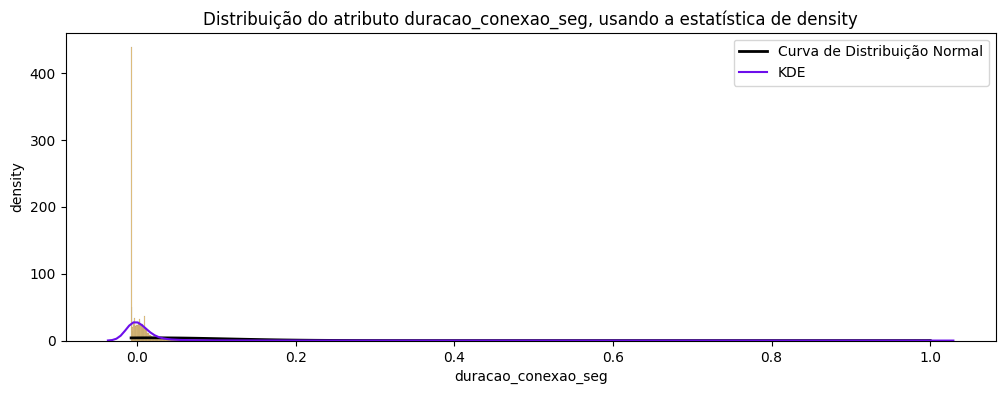

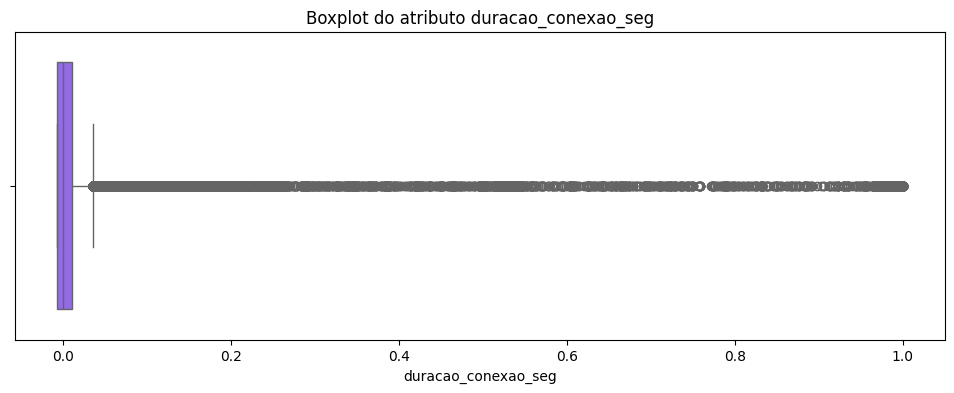




A coluna duracao_conexao_seg não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo duracao_conexao_seg:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo duracao_conexao_seg: 

 - A média aritmética de seus valores é, aproximadamente, 0.02;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, -0.01;


 Medidas de Dispersão e Amplitude

 - Amplitude: de -0.01 até 1.00. Variam em uma faixa de 1.01

 - Desvio Padrão: 0.10

 - Coeficiente de Variação: 5.50 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo duracao_conexao_seg:

 - O valor do quartil de 25% é -0.01. Isto significa que 25% dos dados da amostra do atributo duracao_conexao_seg são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Is

In [38]:
# Lista com o atributo desejado
coluna_alvo = ['duracao_conexao_seg']
# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

##### 2.1.2. Análise e visualização sem outliers
---

Exclusão dos outliers e geração dos gráficos e métricas:

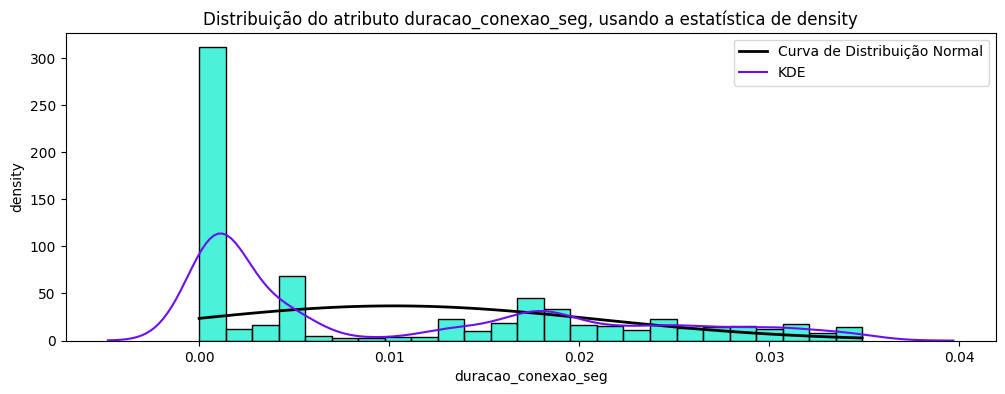

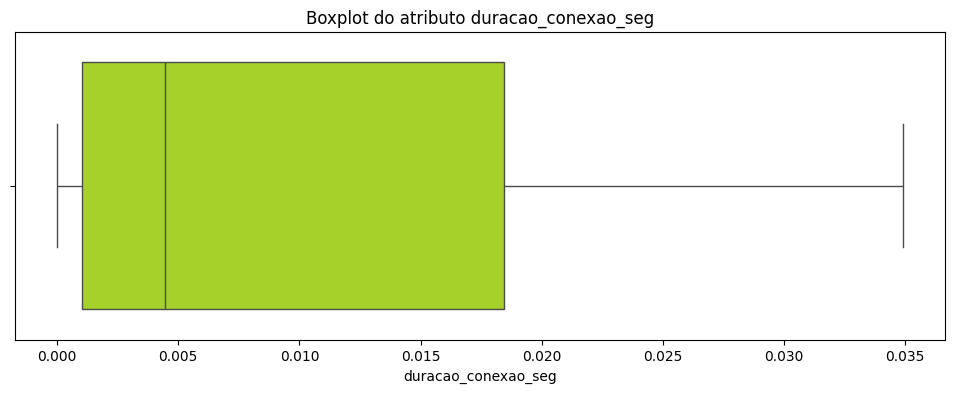






 Análise Básica do atributo duracao_conexao_seg:

 - No total, há 14232 células e destas, 0 são nulas, 7692 estão repetidas e o total de valores unicos são 6540.


 Medidas de Tendência Central do atributo duracao_conexao_seg: 

 - A média aritmética de seus valores é, aproximadamente, 0.01;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.03. Variam em uma faixa de 0.03

 - Desvio Padrão: 0.01

 - Coeficiente de Variação: 1.06 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo duracao_conexao_seg:

 - 68% da amostra está compreendida entre, aproximadamente, -0.00 e 0.02;

 - 95% da amostra está compreendida entre, aproximadamente, -0.01 e 0.03;

 - 99.7% da amostra está compreendida entre, aproximadamente, -0.02 e 0.04.


In [46]:
coluna_alvo = ['duracao_conexao_seg']

_,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, 'duracao_conexao_seg')
df_visualizacao = pp.drop_outlier(df_visualizacao, 'duracao_conexao_seg', limite_inferior, limite_superior)
df_visualizacao[(df_visualizacao['duracao_conexao_seg'] < limite_inferior) | (df_visualizacao['duracao_conexao_seg'] > limite_superior)].shape[0]

for col in coluna_alvo:
    pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
    pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in medidas_sem_outlier:
        funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 a 60.00 e agora é de 0.00 até 0.03.

#### 2.2. Atributo protocolo_rede
---

Este atributo **possui** outliers.

##### 2.2.1. Análise e visualização com outliers
---

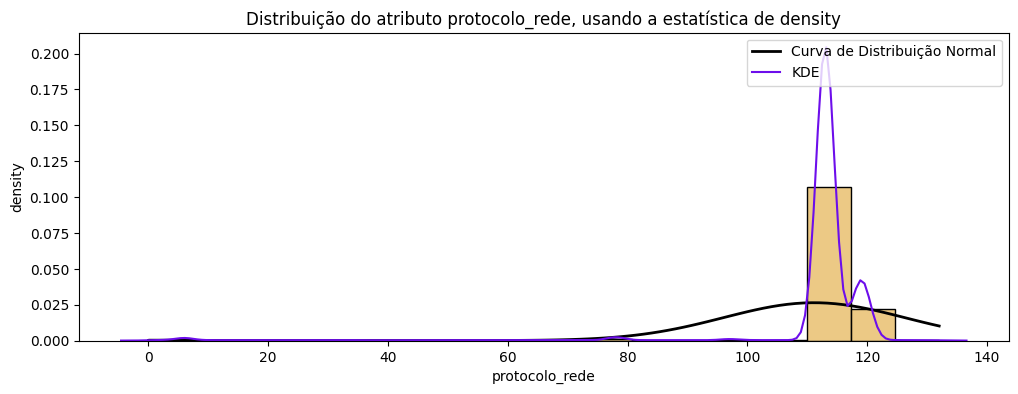

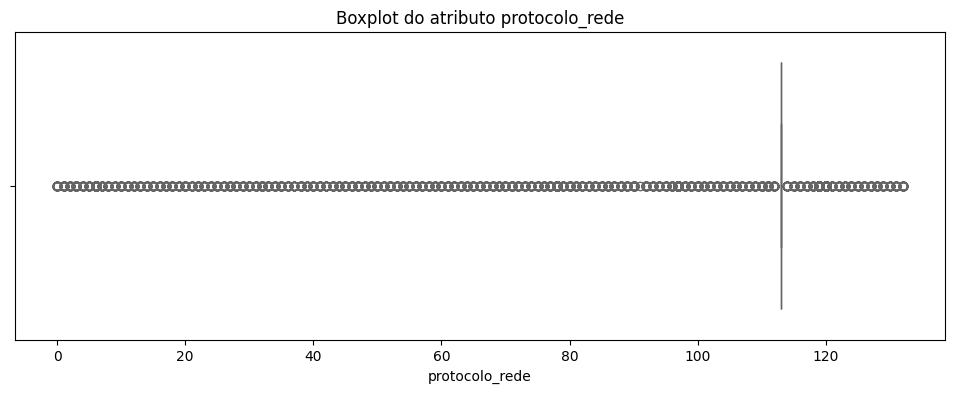






 Análise Básica do atributo protocolo_rede:

 - No total, há 96822 células e destas, 0 são nulas, 96689 estão repetidas e o total de valores unicos são 133.


 Medidas de Tendência Central do atributo protocolo_rede: 

 - A média aritmética de seus valores é, aproximadamente, 111.12;

 - A mediana é, aproximadamente, 113.00;

 - A moda é, aproximadamente, 113.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 132.00. Variam em uma faixa de 132.00

 - Desvio Padrão: 15.12

 - Coeficiente de Variação: 0.14 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 96.01 a 126.24 (em caso de normalidade).


 Medidas de Posição (Quartis) do atributo protocolo_rede:

 - O valor do quartil de 25% é 113.00. Isto significa que 25% dos dados da amostra do atributo protocolo_rede são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 113.00. Isto significa que 50% dos dados da amostra do atributo protocolo_rede são menores ou iguais a esse va

In [42]:
# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
coluna_alvo = ['protocolo_rede']
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo protocolo_rede apresenta um comportamento `distribuição não normal`. O `histograma` e o `KDE` revelam picos de densidade extremamente acentuados, especialmente em torno do valor 113.00 (que atua como moda, mediana e todos os quartis). A `Curva Normal` aparece visivelmente desconectada da realidade dos dados, pois tenta suavizar uma distribuição que é inerentemente discreta e concentrada. A aplicação das regras de ouro reforça essa inadequação ao sugerir intervalos que chegam a 156.47, valor que extrapola a amplitude real do atributo (máximo de 132.00).

O `boxplot` exibe uma configuração atípica de compressão central, onde o corpo do gráfico (os quartis) se reduz a uma única linha no valor 113.00. Como os limites estatísticos inferior e superior coincidem nesse mesmo valor, qualquer protocolo diferente de 113 é tecnicamente classificado como outlier. Isso resulta em 5.12% de outliers inferiores (4.955 registros) e 16.59% de outliers superiores (16.062 registros). Apesar do `Coeficiente de Variação` de 0.14 sugerir uma dispersão baixa em relação à média (111.12), a distribuição é fortemente enviesada pela dominância de protocolos específicos.

Os `outliers serão mantidos`, pois cada valor representa um protocolo de rede distinto mapeado via codificação ordinal. Em um ambiente de rede, a predominância de certos protocolos (como TCP ou UDP) é esperada, mas a presença de protocolos menos frequentes — representados aqui como outliers — é crucial para a segurança. Esses registros "discrepantes" exprimem casos reais de comunicação que podem variar desde serviços legítimos e raros até tentativas de tunelamento ou uso de protocolos não convencionais para evasão de sistemas de detecção.

##### 2.2.2. Análise e visualização sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

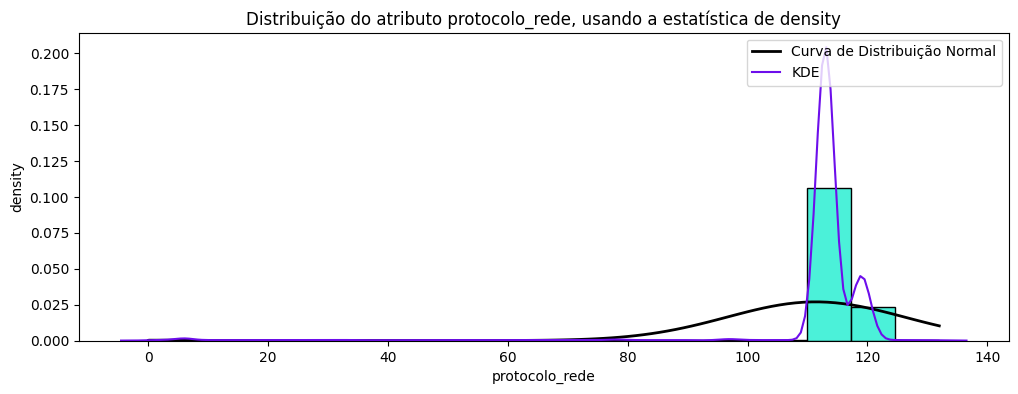

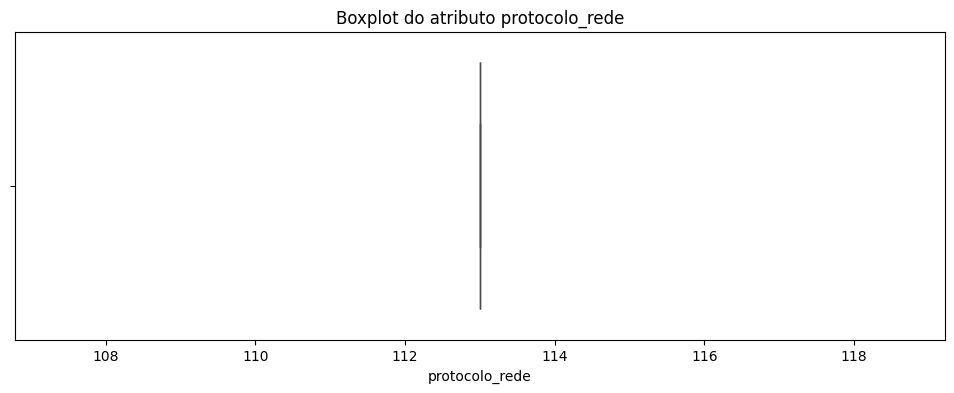






 Análise Básica do atributo protocolo_rede:

 - No total, há 89329 células e destas, 0 são nulas, 89197 estão repetidas e o total de valores unicos são 132.


 Medidas de Tendência Central do atributo protocolo_rede: 

 - A média aritmética de seus valores é, aproximadamente, 111.40;

 - A mediana é, aproximadamente, 113.00;

 - A moda é, aproximadamente, 113.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 132.00. Variam em uma faixa de 132.00

 - Desvio Padrão: 14.81

 - Coeficiente de Variação: 0.13 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 96.59 a 126.21 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo protocolo_rede:

 - 68% da amostra está compreendida entre, aproximadamente, 96.59 e 126.21;

 - 95% da amostra está compreendida entre, aproximadamente, 81.77 e 141.02;

 - 99.7% da amostra está compreendida entre, aproximadamente, 66.96 e 155.84.


In [28]:
coluna_alvo = ['protocolo_rede']

_,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, 'duracao_conexao_seg')
df_visualizacao = pp.drop_outlier(df_visualizacao, 'duracao_conexao_seg', limite_inferior, limite_superior)
df_visualizacao[(df_visualizacao['duracao_conexao_seg'] < limite_inferior) | (df_visualizacao['duracao_conexao_seg'] > limite_superior)].shape[0]

for col in coluna_alvo:
    pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
    pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
    for funcao in medidas_sem_outlier:
        funcao(df_visualizacao,col)

A visualização sem outliers não inferiu muito nesta análise, uma vez que o atributo é categórico. Está confirmado que a **distribuição não é normal** tanto pela curva achatada quanto pelos valores positivos não alcançáveis das regras de ouro, por serem maiores que o valor máximo. A amplitude anterior e a atual continuam as mesmas, de 0.00 a 132.00.

#### 2.3. Atributo servico_conexao
---

Este atributo **não possui** outliers naturalmente.

##### 2.3.1. Visualização com outliers
---

In [44]:
# Lista com o atributo desejado
coluna_alvo = ['servico_conexao']

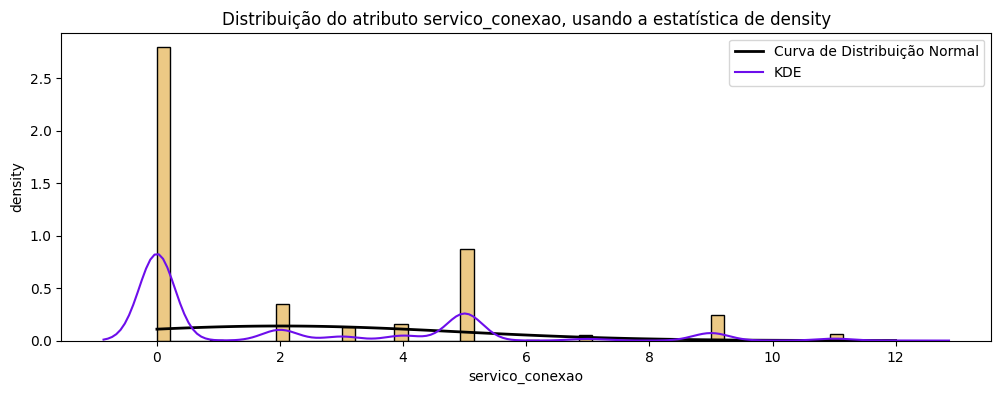

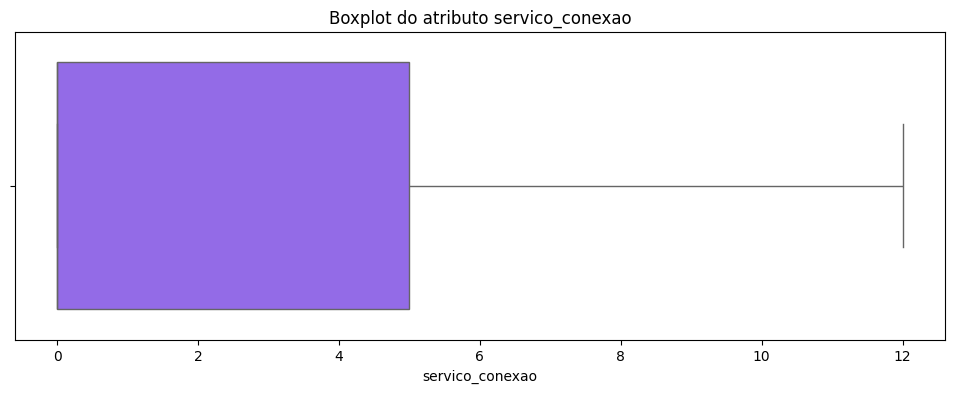






 Análise Básica do atributo servico_conexao:

 - No total, há 96822 células e destas, 0 são nulas, 96809 estão repetidas e o total de valores unicos são 13.


 Medidas de Tendência Central do atributo servico_conexao: 

 - A média aritmética de seus valores é, aproximadamente, 2.01;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 12.00. Variam em uma faixa de 12.00

 - Desvio Padrão: 2.87

 - Coeficiente de Variação: 1.43 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo servico_conexao:

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo servico_conexao são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo servico_conexao são menores ou iguais a esse val

In [45]:
# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True, limite_x=False)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo servico_conexao apresenta um comportamento de `distribuição não normal`. O `histograma` e o `KDE` revelam picos de densidade bem definidos, com destaque absoluto para o valor 0.00 (moda e mediana), seguido por concentrações relevantes nos valores 5.00, 2.00 e 9.00. A `Curva Normal` aparece achatada e deslocada, falhando em representar a natureza discreta dos dados, enquanto as regras de ouro reforçam essa inadequação ao sugerir intervalos negativos (até -6.61) que não possuem aplicação prática para índices de serviço.

O `boxplot` exibe um corpo robusto que se estende do valor 0.00 (25% e 50%) até o valor 5.00 (75%). `Não foram detectados outliers` (0.00%), uma vez que toda a amplitude observada (de 0.00 a 12.00) está contida dentro dos limites estatísticos calculados, que variam de -7.50 a 12.50. O `Coeficiente de Variação` de 1.43 e o `desvio padrão` (2.87) superior à média (2.01) confirmam a alta dispersão dos dados entre as diferentes categorias de serviço disponíveis.

Os dados deste atributo `serão mantidos` integralmente, pois cada valor numérico representa um tipo de serviço de rede específico (como HTTP, DNS, SMTP, etc.) mapeado via codificação ordinal. A alta concentração em serviços específicos e a ausência de outliers indicam que, embora a frequência de uso varie entre os protocolos, todos os serviços registrados fazem parte do escopo operacional esperado do dataset. Essa diversidade de serviços é fundamental para que o modelo identifique quais portas e protocolos são mais visados em diferentes categorias de ataque.

#### 2.4. Atributo estado_conexao
---

Este atributo **possui** outliers.

##### 2.4.1. Análise e visualização com outliers
---

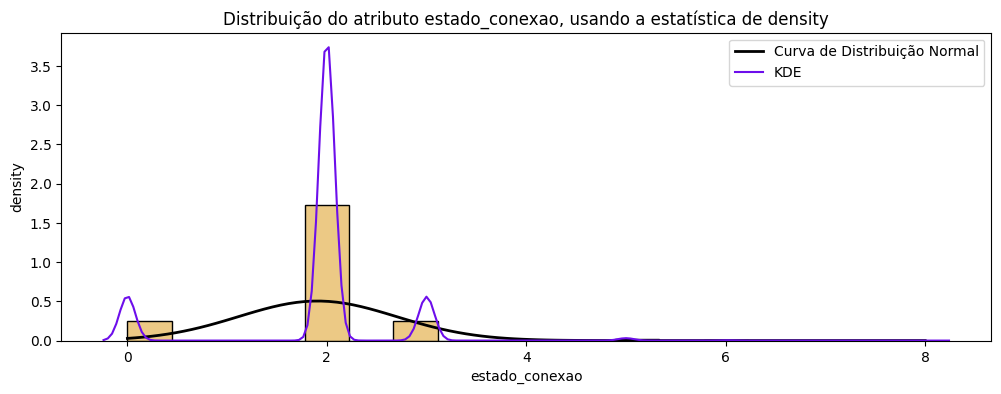

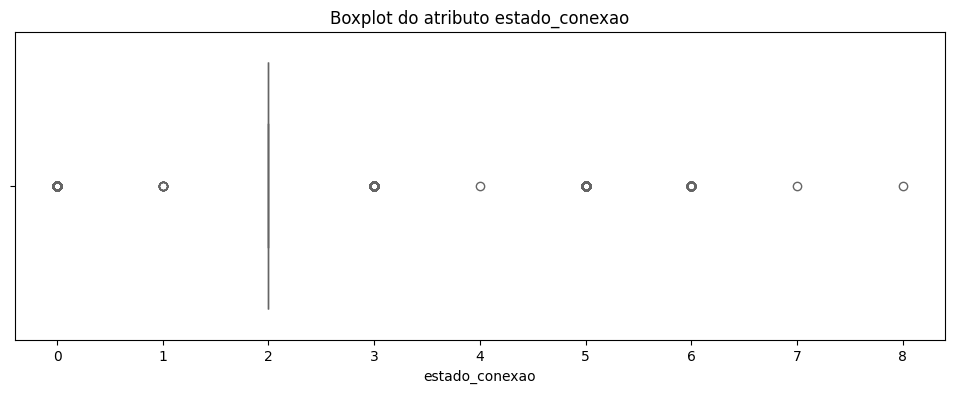






 Análise Básica do atributo estado_conexao:

 - No total, há 96822 células e destas, 0 são nulas, 96813 estão repetidas e o total de valores unicos são 9.


 Medidas de Tendência Central do atributo estado_conexao: 

 - A média aritmética de seus valores é, aproximadamente, 1.91;

 - A mediana é, aproximadamente, 2.00;

 - A moda é, aproximadamente, 2.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 8.00. Variam em uma faixa de 8.00

 - Desvio Padrão: 0.79

 - Coeficiente de Variação: 0.41 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 1.12 a 2.70 (em caso de normalidade).


 Medidas de Posição (Quartis) do atributo estado_conexao:

 - O valor do quartil de 25% é 2.00. Isto significa que 25% dos dados da amostra do atributo estado_conexao são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 2.00. Isto significa que 50% dos dados da amostra do atributo estado_conexao são menores ou iguais a esse valor. Equivale à medi

In [46]:
# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
# Lista com o atributo desejado
coluna_alvo = ['estado_conexao']
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True, limite_x=False)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo estado_conexao apresenta um comportamento de `distribuição não normal`. O `histograma` e o `KDE` revelam picos de densidade isolados e acentuados, com destaque absoluto para o valor 2.00, que atua simultaneamente como moda, mediana e todos os quartis (25%, 50% e 75%). A `Curva Normal` falha em representar a realidade dos dados por tentar suavizar uma distribuição que é discreta e agrupada. As regras de ouro reforçam essa inadequação ao sugerir valores negativos (até -0.47) para um índice de estado que é estritamente não negativo.

O `boxplot` é comprimido. Como os limites estatísticos inferior e superior coincidem no mesmo valor de 2, qualquer estado de conexão diferente de 2.00 é tecnicamente classificado como outlier. Isso resulta em 11.35% de outliers inferiores (10.985 registros) e 11.87% de outliers superiores (11.492 registros), estendendo-se por uma amplitude total de 0.00 a 8.00. O `Coeficiente de Variação` de 0.41 indica uma dispersão moderada em relação à média (1.91), embora a concentração de dados esteja em poucos valores.

Os `outliers serão mantidos`, pois cada valor numérico representa um estado de conexão de rede real e funcional (como SYN, ESTABLISHED, FIN, etc.). A predominância do estado 2.00 sugere que a maioria do tráfego capturado compartilha uma mesma fase de conexão. No entanto, os estados menos frequentes, classificados estatisticamente como outliers, são vitais para a detecção de anomalias, pois podem sinalizar desde encerramentos abruptos de conexão até comportamentos de varredura (scanning) e outras táticas de exploração de rede.

##### 2.4.2. Análise e visualização sem outliers
---

Exclusão dos outliers:

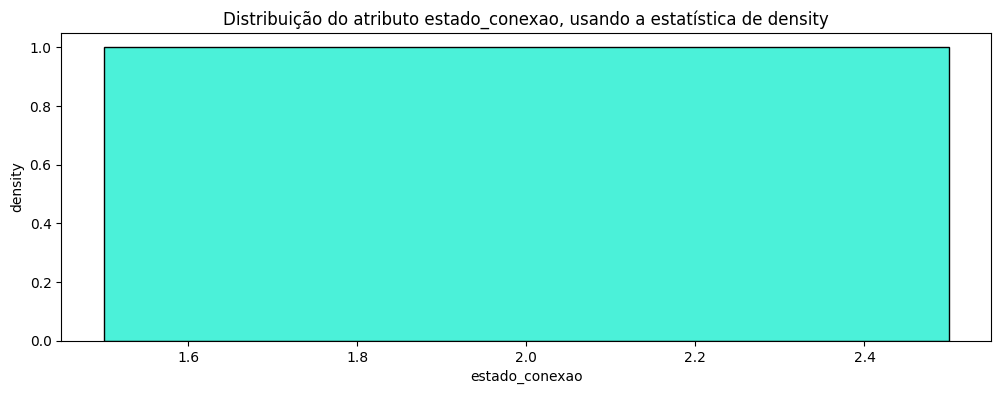

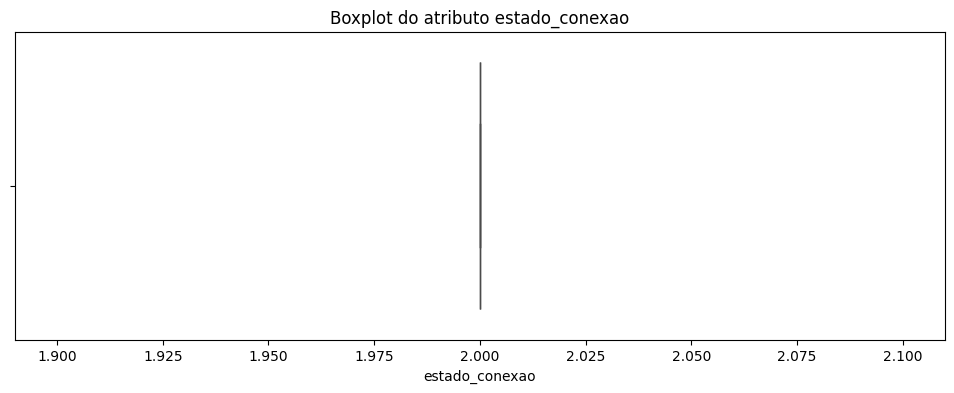




A coluna estado_conexao não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo estado_conexao:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo estado_conexao: 

 - A média aritmética de seus valores é, aproximadamente, 2.00;

 - A mediana é, aproximadamente, 2.00;

 - A moda é, aproximadamente, 2.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 2.00 até 2.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 2.00 a 2.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo estado_conexao:

 - 68% da amostra está compreendida entre, aproximadamente, 2.00 e 2.00;

 - 95% da amostra está compreendida entre, aproximadamente, 2.00 e 2.00;

 - 99.7% da amostra está compreendida entre, aproximadamente, 2.00 

In [47]:
coluna_alvo = ['estado_conexao']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu ver de maneira mais clara o pico que há no entorno do valor 2, que a categoria dominante. Este atributo é categórico e confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 a 8.00 e agora é 2.00 a 2.00.

#### 2.5. Atributo num_pacotes_origem
---

Este atributo **possui** outliers.

##### 2.5.1. Análise e visualização com outliers
---

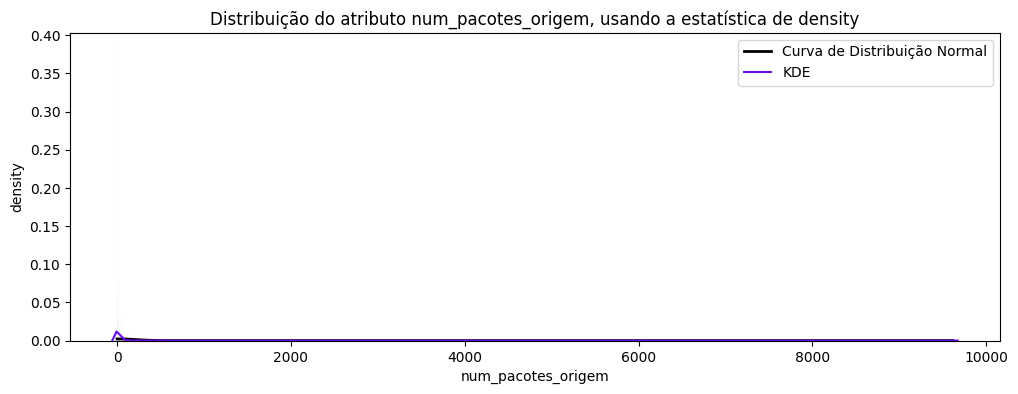

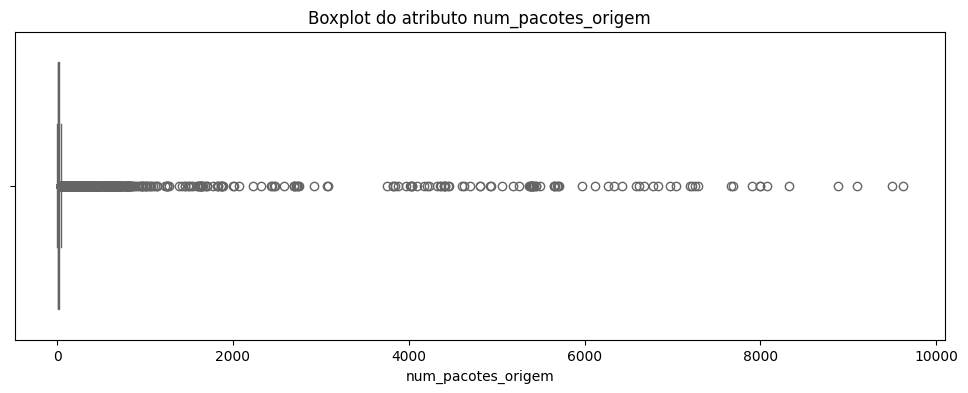




A coluna num_pacotes_origem não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo num_pacotes_origem:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo num_pacotes_origem: 

 - A média aritmética de seus valores é, aproximadamente, 33.34;

 - A mediana é, aproximadamente, 10.00;

 - A moda é, aproximadamente, 10.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 1.00 até 9616.00. Variam em uma faixa de 9615.00

 - Desvio Padrão: 182.66

 - Coeficiente de Variação: 5.48 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo num_pacotes_origem:

 - O valor do quartil de 25% é 8.00. Isto significa que 25% dos dados da amostra do atributo num_pacotes_origem são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 10.00

In [30]:
# Lista com o atributo desejado
coluna_alvo = ['num_pacotes_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True, limite_x=False)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo num_pacotes_origem apresenta `distribuição não normal`. O `histograma` e o `KDE` revelam que a grande massa de dados está comprimida próxima ao valor 10.00 (moda e mediana), fazendo com que a `Curva Normal` apareça praticamente como uma linha reta horizontal no gráfico. A aplicação das regras de ouro reforça essa inadequação estatística ao sugerir intervalos com valores negativos (até -514.65), o que é impossível para uma contagem de pacotes.

O `boxplot` evidencia uma cauda superior longa, onde 75% dos registros apresentam até 24.00 pacotes enviados, mas o valor máximo atinge 9616.00. Com um limite superior estatístico de 48.00, o atributo registra 15.33% de outliers superiores (14.846 células). O `Coeficiente de Variação` de 5.48 e o desvio padrão (182.66) significativamente maior que a média (33.34) confirmam a altíssima dispersão e a presença de dados discrepantes.

Os `outliers serão mantidos`, pois representam comportamentos de rede reais e variados. É notável que a maioria desses registros discrepantes (11.298) corresponde a tráfego legítimo (não ataque), enquanto uma parcela menor (3.548) está vinculada a atividades maliciosas. Como a quantidade de pacotes enviados depende estritamente do contexto da aplicação e do tipo de comunicação estabelecida, excluir esses valores resultaria na perda de informações críticas para a diferenciação entre fluxos de dados volumosos legítimos e ataques de negação de serviço ou exfiltração.

##### 2.5.2. Análise e visualização sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

In [35]:
coluna_alvo = ['num_pacotes_origem']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

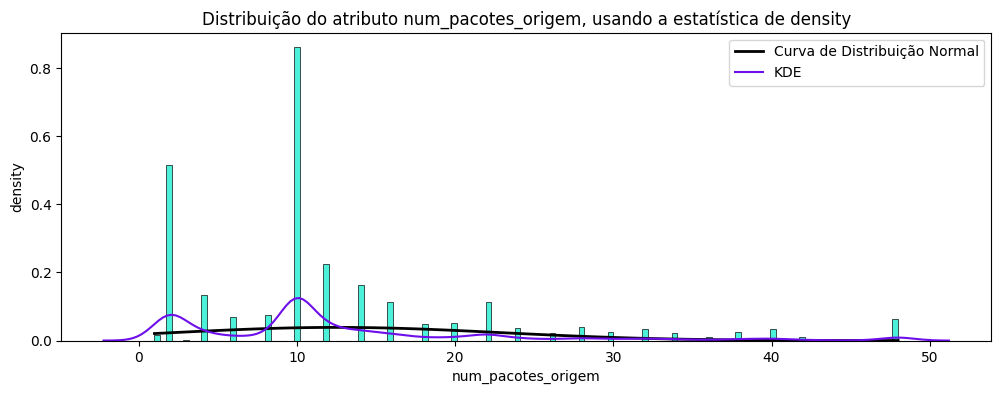

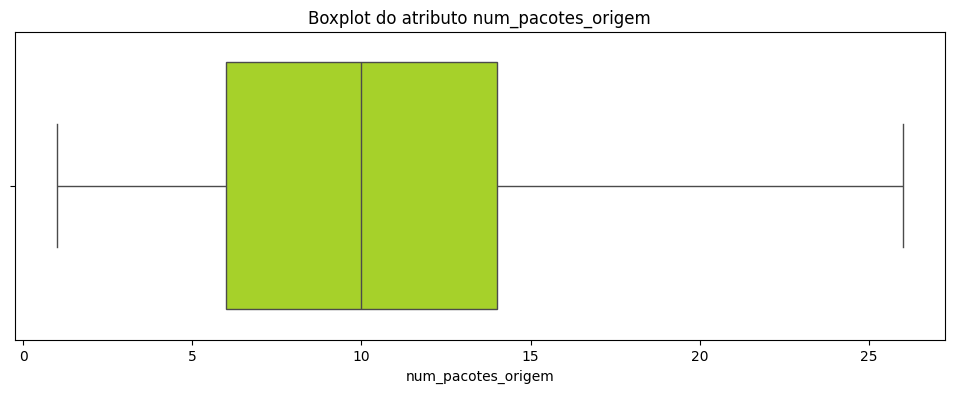




A coluna num_pacotes_origem não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo num_pacotes_origem:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo num_pacotes_origem: 

 - A média aritmética de seus valores é, aproximadamente, 12.53;

 - A mediana é, aproximadamente, 10.00;

 - A moda é, aproximadamente, 10.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 1.00 até 48.00. Variam em uma faixa de 47.00

 - Desvio Padrão: 10.30

 - Coeficiente de Variação: 0.82 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 2.23 a 22.84 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo num_pacotes_origem:

 - 68% da amostra está compreendida entre, aproximadamente, 2.23 e 22.84;

 - 95% da amostra está compreendida entre, aproximadamente, -8.08 e 33.14;

 - 99.7% da amostra está compreendida ent

In [36]:
for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 1.00 a 9,616.00 e agora é de 1.00 a 48.00.

#### 2.6. Atributo num_pacotes_destino
---

Este atributo **possui** outliers.

##### 2.6.1. Análise e visualização com outliers
---

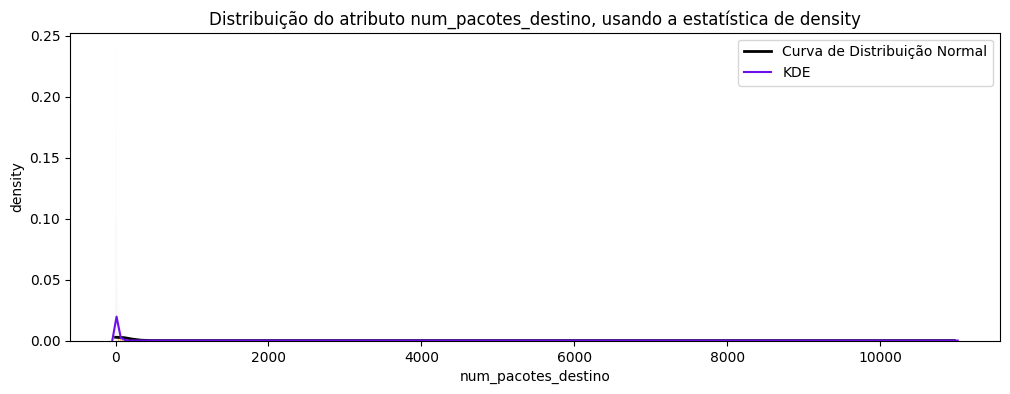

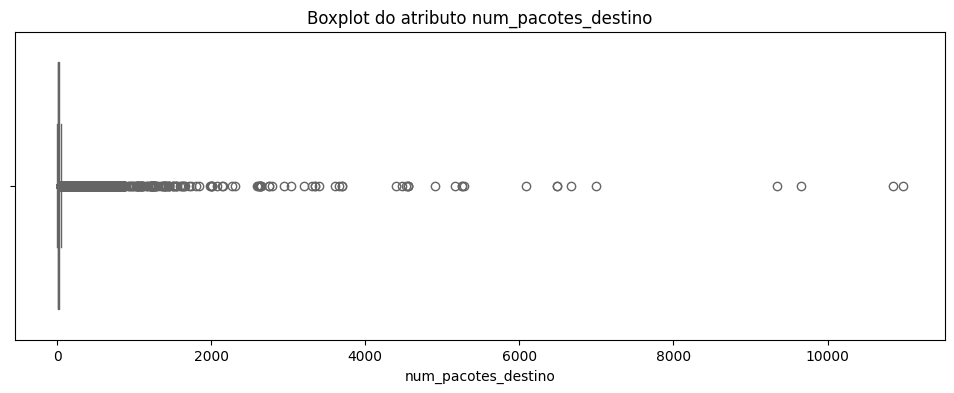






 Análise Básica do atributo num_pacotes_destino:

 - No total, há 96822 células e destas, 0 são nulas, 96379 estão repetidas e o total de valores unicos são 443.


 Medidas de Tendência Central do atributo num_pacotes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 33.40;

 - A mediana é, aproximadamente, 8.00;

 - A moda é, aproximadamente, 8.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 10974.00. Variam em uma faixa de 10974.00

 - Desvio Padrão: 143.65

 - Coeficiente de Variação: 4.30 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo num_pacotes_destino:

 - O valor do quartil de 25% é 6.00. Isto significa que 25% dos dados da amostra do atributo num_pacotes_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 8.00. Isto significa que 50% dos dados da amostra do atributo num_pacotes_destino sã

In [37]:
# Lista com o atributo desejado
coluna_alvo = ['num_pacotes_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo num_pacotes_destino apresenta um comportamento de `distribuição não normal`. O `histograma` e o `KDE` revelam que a grande massa de dados está comprimida próxima ao valor 8.00 (moda e mediana), o que faz com que a `Curva Normal` apareça praticamente como uma linha reta horizontal no gráfico, incapaz de representar a realidade do tráfego. A aplicação das regras de ouro reforça essa inadequação estatística ao sugerir intervalos com valores negativos (até -397.56), o que é impossível para uma contagem de pacotes recebidos.

O `boxplot` evidencia uma cauda superior extremamente longa, onde 75% dos registros apresentam até 22.00 pacotes recebidos, mas o valor máximo atinge 10974.00. Com um limite superior estatístico calculado em 46.00, o atributo registra 14.10% de outliers superiores (13.648 células). O `Coeficiente de Variação` de 4.30 e o `desvio padrão` (143.65) significativamente superior à média (33.40) confirmam a altíssima dispersão dos dados.

Os `outliers serão mantidos`, pois representam variações legítimas e críticas no volume de recepção de dados em uma rede. Em cenários de segurança, volumes discrepantes de pacotes no destino podem indicar desde downloads de arquivos pesados e sessões de streaming (tráfego normal) até ataques de inundação (DoS/DDoS) ou respostas volumosas de servidores após uma consulta maliciosa. A preservação desses dados garante que o modelo de Machine Learning capture a complexidade e a relatividade do fluxo de rede em diferentes contextos operacionais.

##### 2.6.1. Análise e visualização sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

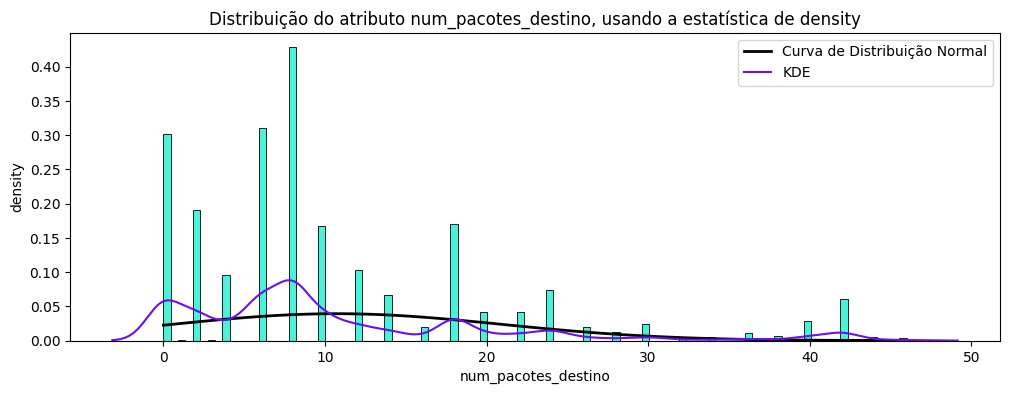

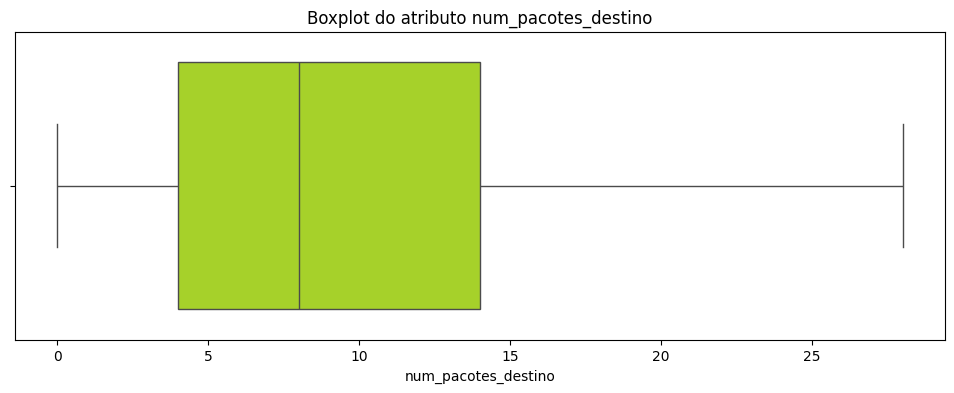






 Análise Básica do atributo num_pacotes_destino:

 - No total, há 83174 células e destas, 0 são nulas, 83148 estão repetidas e o total de valores unicos são 26.


 Medidas de Tendência Central do atributo num_pacotes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 10.74;

 - A mediana é, aproximadamente, 8.00;

 - A moda é, aproximadamente, 8.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 46.00. Variam em uma faixa de 46.00

 - Desvio Padrão: 10.16

 - Coeficiente de Variação: 0.95 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.57 a 20.90 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo num_pacotes_destino:

 - 68% da amostra está compreendida entre, aproximadamente, 0.57 e 20.90;

 - 95% da amostra está compreendida entre, aproximadamente, -9.59 e 31.06;

 - 99.7% da amostra está compreendida entre, aproximadamente, -19.75 e 41.23.


In [40]:
coluna_alvo = ['num_pacotes_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 a 10,974.00 e agora é de 0.00 a 46.00.

#### 2.7. Atributo total_bytes_origem
---

Este atributo **possui** outliers

##### 2.7.1. Análise e visualização com outliers
---

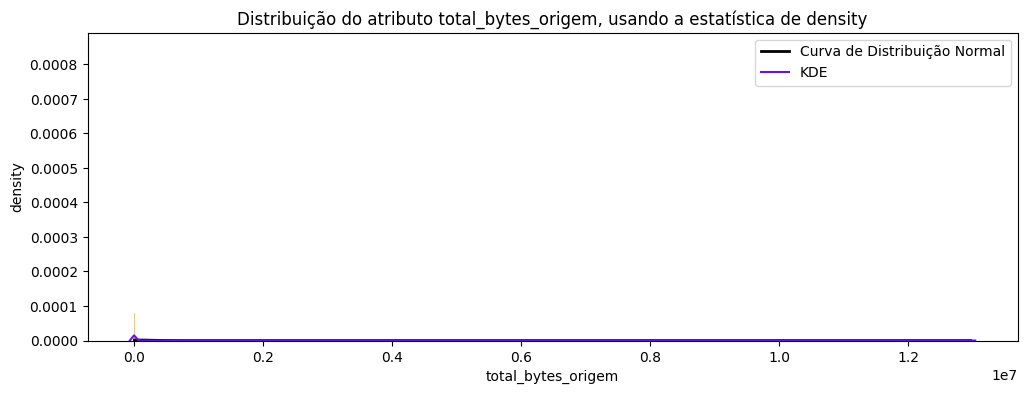

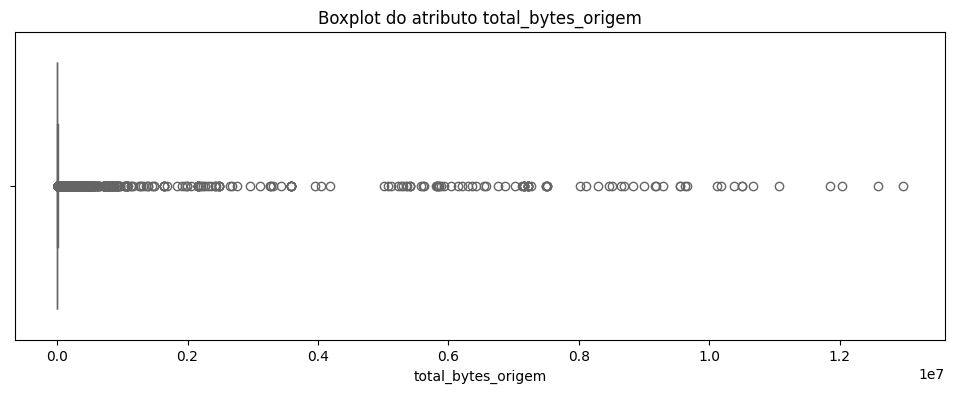




A coluna total_bytes_origem não foi encontrada. Favor digitar uma coluna válida.


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 15349.94;

 - A mediana é, aproximadamente, 1048.00;

 - A moda é, aproximadamente, 146.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 28.00 até 12965233.00

 - Desvio Padrão: 234802.08

 - Coeficiente de Variação: 15.30 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 564.00. Isto significa que 25% dos dados da amostra do atributo total_bytes_origem são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 1048.00. Isto significa que 50% dos dados da amostra do atributo total_bytes_origem são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil de 75% é 2958.00. Isto significa que 75% dos dados da amostra do atributo total_byte

In [47]:
# Lista com o atributo desejado
coluna_alvo = ['total_bytes_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo total_bytes_origem apresenta um comportamento de extrema assimetria positiva, característico de tráfego de rede onde a maioria das conexões transporta poucos dados, enquanto uma minoria movimenta volumes massivos, portanto, a `distribuição não é normal`. O `histograma` e o `KDE` revelam que a grande massa de dados está comprimida próxima aos valores de 146.00 (moda) e 1048.00 (mediana), resultando em uma `Curva Normal` que aparece praticamente como uma linha reta horizontal, incapaz de descrever a realidade estatística do atributo. A aplicação das regras de ouro reforça essa inadequação ao sugerir intervalos com valores negativos (até -689056.29), o que é fisicamente impossível para uma contagem de bytes.

O `boxplot` evidencia uma cauda superior longa, onde 75% dos registros apresentam até 2958.00 bytes, mas o valor máximo atinge a marca de 12.965.233.00 (aproximadamente 12.9 MB). Com um limite superior estatístico de 6549.00, o atributo registra 12.46% de outliers superiores (12.066 células). O `Coeficiente de Variação` de 15.30 e o desvio padrão (234802.08) absurdamente superior à média (15349.94) confirmam que este é um dos atributos de maior dispersão em todo o dataset.

Os `outliers serão mantidos`, pois são fundamentais para distinguir diferentes perfis de atividade. Em segurança cibernética, picos no volume de bytes originados podem indicar desde transferências legítimas de arquivos grandes até exfiltração de dados ou ataques de negação de serviço por inundação (flooding). A preservação desses valores permite que os modelos de detecção identifiquem anomalias volumétricas que seriam completamente mascaradas caso os dados fossem normalizados ou removidos.

##### 2.7.2. Análise e visualização sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

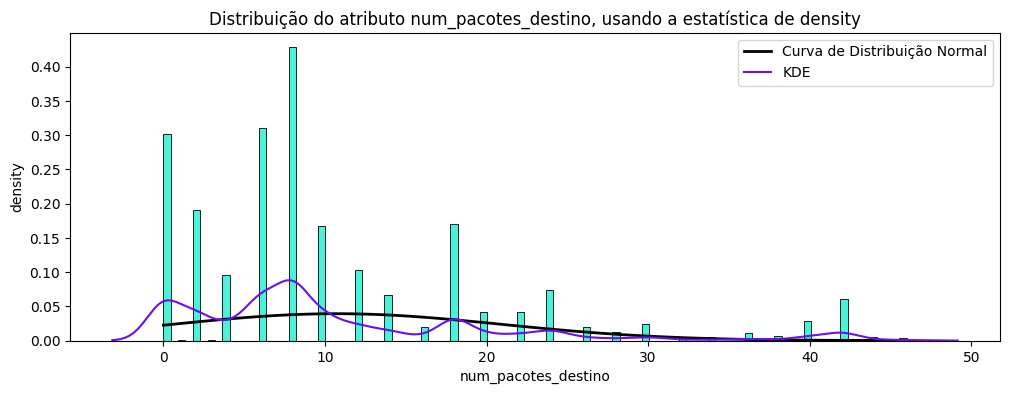

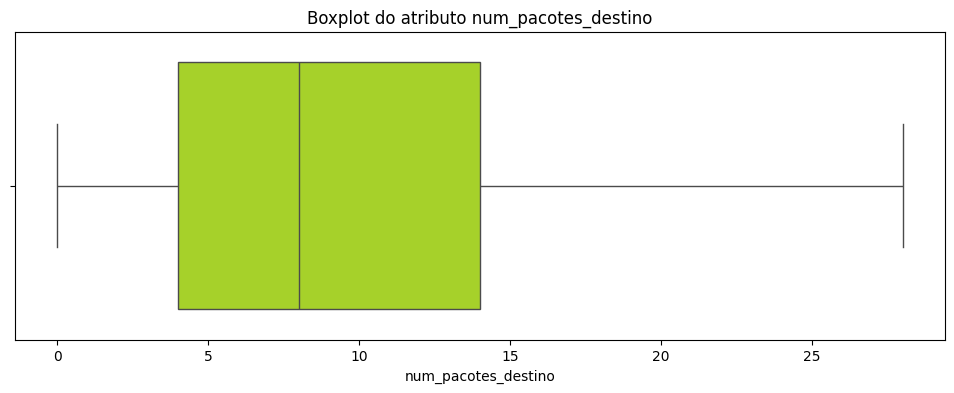






 Análise Básica do atributo num_pacotes_destino:

 - No total, há 83174 células e destas, 0 são nulas, 83148 estão repetidas e o total de valores unicos são 26.


 Medidas de Tendência Central do atributo num_pacotes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 10.74;

 - A mediana é, aproximadamente, 8.00;

 - A moda é, aproximadamente, 8.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 46.00. Variam em uma faixa de 46.00

 - Desvio Padrão: 10.16

 - Coeficiente de Variação: 0.95 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.57 a 20.90 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo num_pacotes_destino:

 - 68% da amostra está compreendida entre, aproximadamente, 0.57 e 20.90;

 - 95% da amostra está compreendida entre, aproximadamente, -9.59 e 31.06;

 - 99.7% da amostra está compreendida entre, aproximadamente, -19.75 e 41.23.


In [41]:
coluna_alvo = ['num_pacotes_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 28.00 a 12,965,233.00 e agora é de 0.00 a 46.00.

#### 2.8. Atributo total_bytes_destino
---

Este atributo **possui** outlires:

##### 2.8.1. Análise e visualização sem outliers
---

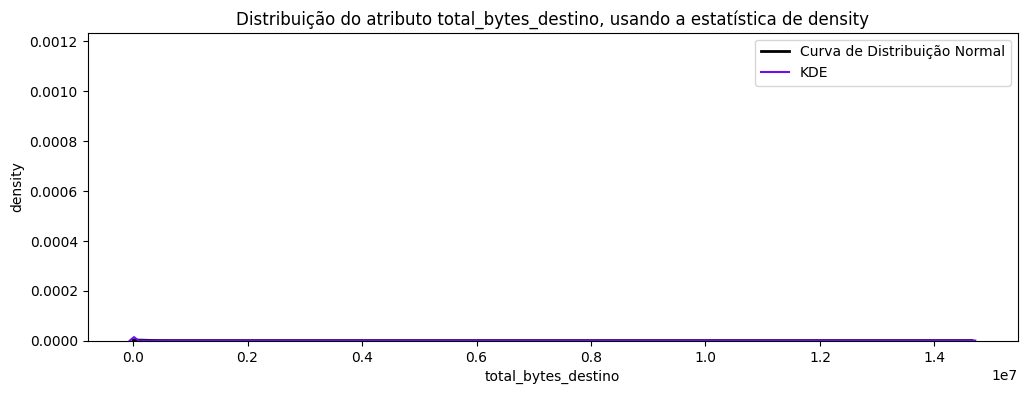

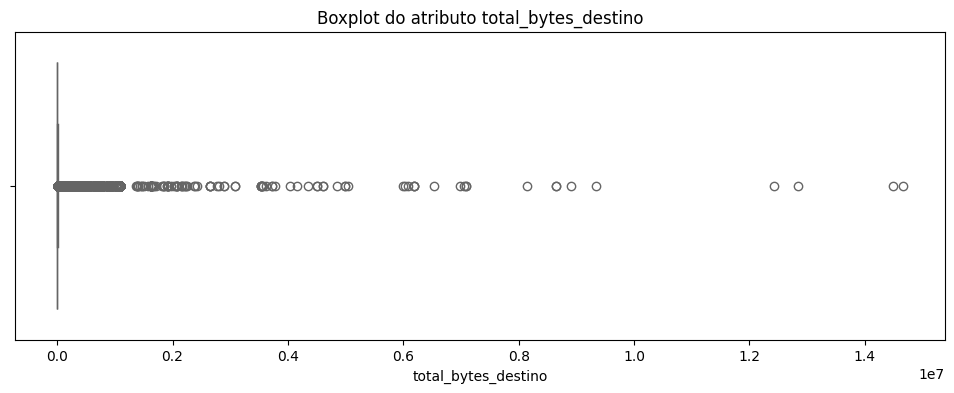






 Análise Básica do atributo total_bytes_destino:

 - No total, há 96822 células e destas, 0 são nulas, 90162 estão repetidas e o total de valores unicos são 6660.


 Medidas de Tendência Central do atributo total_bytes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 26402.05;

 - A mediana é, aproximadamente, 698.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 14655550.00. Variam em uma faixa de 14655550.00

 - Desvio Padrão: 188235.81

 - Coeficiente de Variação: 7.13 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo total_bytes_destino:

 - O valor do quartil de 25% é 268.00. Isto significa que 25% dos dados da amostra do atributo total_bytes_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 698.00. Isto significa que 50% dos dados da amostra do atributo tot

In [34]:
# Lista com o atributo desejado
coluna_alvo = ['total_bytes_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo total_bytes_destino apresenta um comportamento de extrema assimetria positiva, seguindo o padrão observado no tráfego de origem, mas com uma dispersão ainda mais acentuada. A `distribuição não é normal`. O `histograma` e o `KDE` mostram uma concentração massiva de dados próxima a 0.00 (moda) e 698.00 (mediana), o que faz com que a `Curva Normal` apareça como uma reta horizontal, falhando em representar a realidade dos dados. A aplicação das regras de ouro reforça essa inadequação ao sugerir intervalos com limites negativos (até -538305.37), o que é impossível para uma contagem de volume de dados.

O `boxplot` revela uma cauda de outliers significativamente longa e mais espaçada que a da origem, com 75% dos registros contendo até 3674.00 bytes, enquanto o valor máximo atinge 14.655.550.00 (aprox. 14.6 MB). Com um limite superior estatístico de 8783.00, o atributo registra a maior incidência de outliers superiores analisada até agora: 20.73% do total de registros (20.076 células). O `Coeficiente de Variação` de 7.13 e o `desvio padrão` (188235.81) muito superior à média (26402.05) confirmam a volatilidade extrema deste campo.

Os `outliers serão mantidos`, pois, assim como na origem, eles refletem a natureza heterogênea das comunicações de rede. Volumes elevados de bytes no destino são indicadores críticos em segurança: podem representar o sucesso de uma transferência de arquivo legítima ou, em contextos maliciosos, a recepção de cargas úteis (payloads) de ataques ou respostas volumosas de servidores em ataques de amplificação. Remover ou normalizar esses 20% de dados descaracterizaria os cenários de maior impacto que o modelo de Machine Learning deve ser capaz de detectar.

##### 2.8.2. Análise e visualização sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

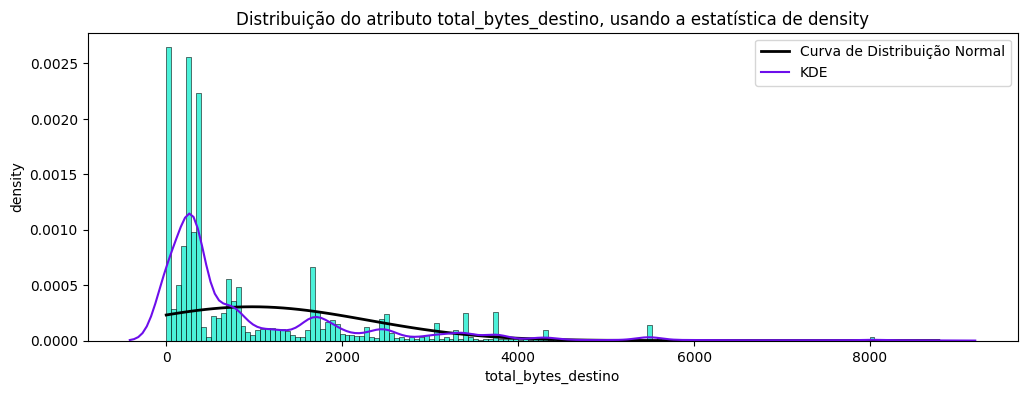

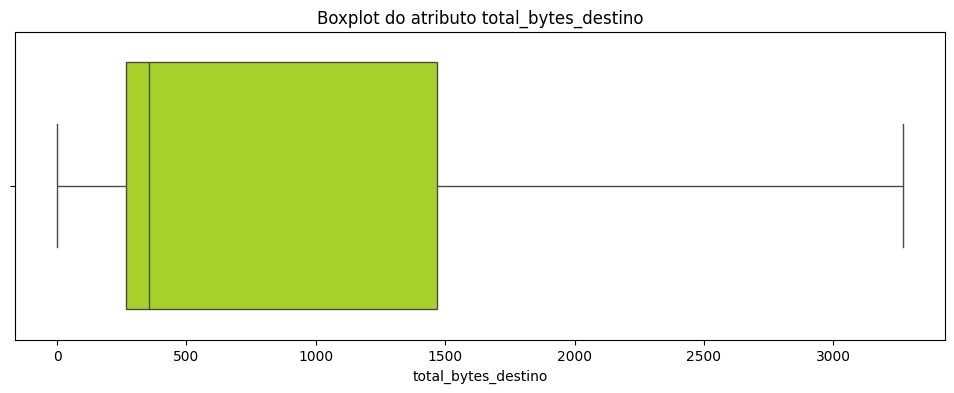






 Análise Básica do atributo total_bytes_destino:

 - No total, há 76746 células e destas, 0 são nulas, 73880 estão repetidas e o total de valores unicos são 2866.


 Medidas de Tendência Central do atributo total_bytes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 977.15;

 - A mediana é, aproximadamente, 354.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 8782.00. Variam em uma faixa de 8782.00

 - Desvio Padrão: 1308.52

 - Coeficiente de Variação: 1.34 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo total_bytes_destino:

 - 68% da amostra está compreendida entre, aproximadamente, -331.37 e 2285.66;

 - 95% da amostra está compreendida entre, aproximadamente, -1639.89 e 3594.18;

 - 99.7% da amostra está compreendida entre, aproximadamente, -2948.40 e 4902.70.


In [96]:
coluna_alvo = ['total_bytes_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 a 14,655,550.00 e agora é de 0.00 a 8,782.00.

#### 2.9. Atributo taxa_pacote
---

Este atributo **possui** outliers.

##### 2.9.1. Análise e visualização com outliers
---

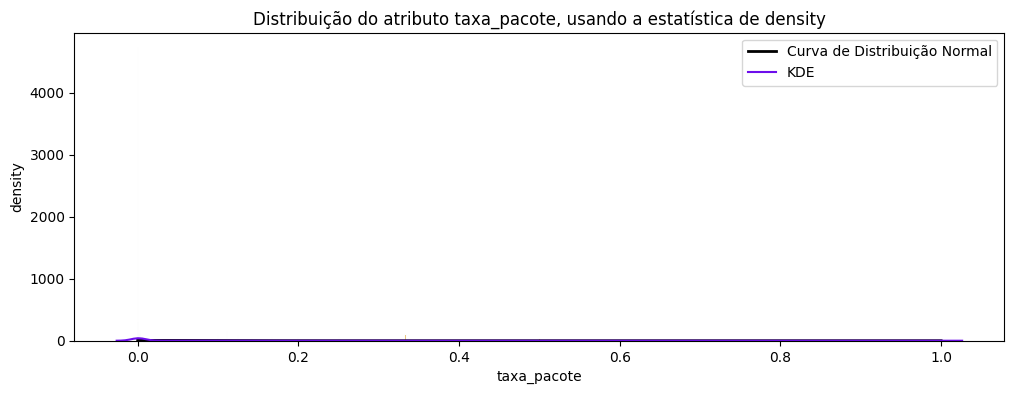

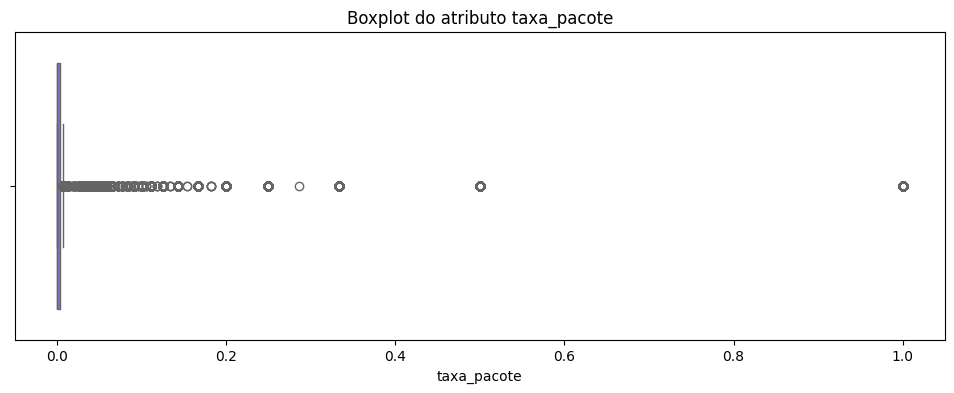






 Análise Básica do atributo taxa_pacote:

 - No total, há 96822 células e destas, 0 são nulas, 20028 estão repetidas e o total de valores unicos são 76794.


 Medidas de Tendência Central do atributo taxa_pacote: 

 - A média aritmética de seus valores é, aproximadamente, 0.02;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.11;


 Medidas de Dispersão e Amplitude

 - Amplitude: de -0.00 até 1.00. Variam em uma faixa de 1.00

 - Desvio Padrão: 0.09

 - Coeficiente de Variação: 4.02 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo taxa_pacote:

 - O valor do quartil de 25% é -0.00. Isto significa que 25% dos dados da amostra do atributo taxa_pacote são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo taxa_pacote são menores ou iguais a esse valor. Equivale à me

In [47]:
# Lista com o atributo desejado
coluna_alvo = ['taxa_pacote']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True, limite_x=False)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo taxa_pacote apresenta um comportamento de extrema assimetria positiva, `distribuição não normal`, típico de métricas de desempenho de rede onde a maioria do tráfego opera em taxas baixas, mas picos repentinos geram valores ordens de magnitude superiores. O `histograma` e o `KDE` mostram uma concentração alta próxima a 0.00, fazendo com que a Curva Normal apareça como uma linha reta horizontal. A aplicação das regras de ouro confirma a inadequação da distribuição normal ao sugerir limites negativos (até -238231.08), o que é impossível para uma taxa de pacotes por segundo.

O `boxplot` evidencia uma dispersão muito alta, com 75% dos dados situados abaixo de 2832.86, mas com um valor máximo que atinge 1.000.000.00. Com um limite superior estatístico de 7045.27, o atributo registra 12.03% de outliers superiores (11.652 registros). O `Coeficiente de Variação` de 4.01 e o `desvio padrão` (86615.93) significativamente superior à média (21616.70) reforçam a presença de picos extremos e a volatilidade dos dados.

Os `outliers serão mantidos`, pois são fundamentais para a detecção de anomalias. Em ataques cibernéticos, como o DoS (Denial of Service), a taxa_pacote é um dos principais indicadores, apresentando picos súbitos que se distanciam completamente do tráfego padrão. Preservar esses valores permite que o modelo de Machine Learning identifique essas assinaturas de ataque, que seriam eliminadas caso os dados fossem tratados como ruído estatístico.

##### 2.9.2. Análise e visualização sem outliers
---

In [ ]:
Exclusão dos outliers e geração de gráficos e métricas:

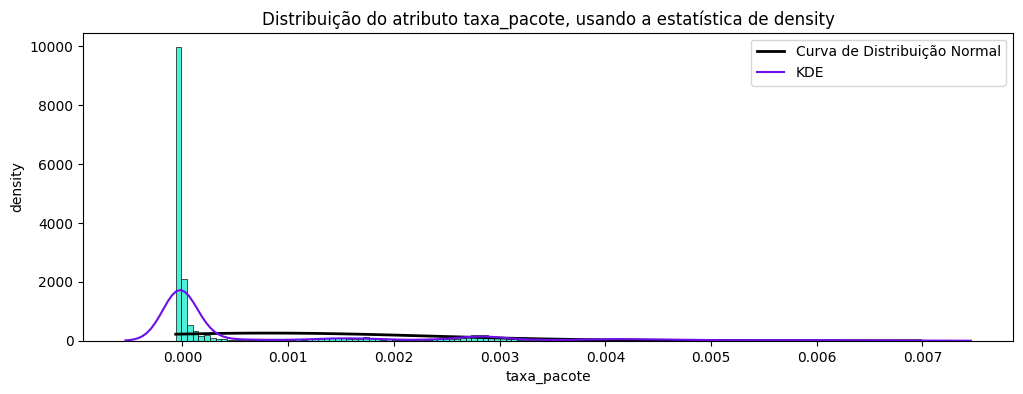

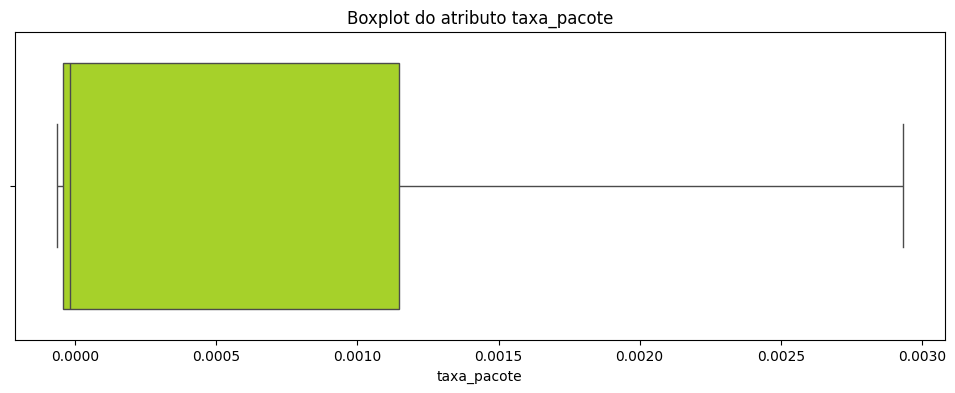






 Análise Básica do atributo taxa_pacote:

 - No total, há 85170 células e destas, 0 são nulas, 10122 estão repetidas e o total de valores unicos são 75048.


 Medidas de Tendência Central do atributo taxa_pacote: 

 - A média aritmética de seus valores é, aproximadamente, 0.00;

 - A mediana é, aproximadamente, -0.00;

 - A moda é, aproximadamente, -0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de -0.00 até 0.01. Variam em uma faixa de 0.01

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 1.91 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo taxa_pacote:

 - 68% da amostra está compreendida entre, aproximadamente, -0.00 e 0.00;

 - 95% da amostra está compreendida entre, aproximadamente, -0.00 e 0.00;

 - 99.7% da amostra está compreendida entre, aproximadamente, -0.00 e 0.01.


In [48]:
coluna_alvo = ['taxa_pacote']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 a 60.00 e agora é de 0.00 a 2.52.

#### 2.10. Atributo carga_origem
---

Este atributo **possui** outliers

##### 2.10.1. Análise e visualização com outliers
---

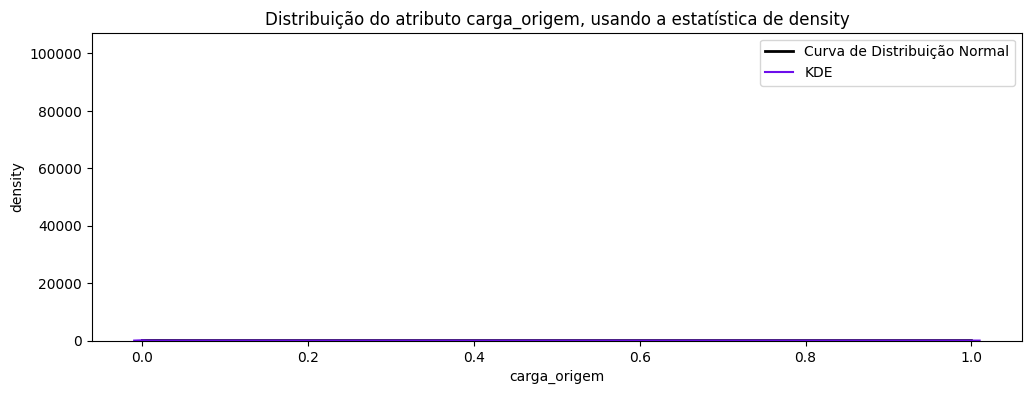

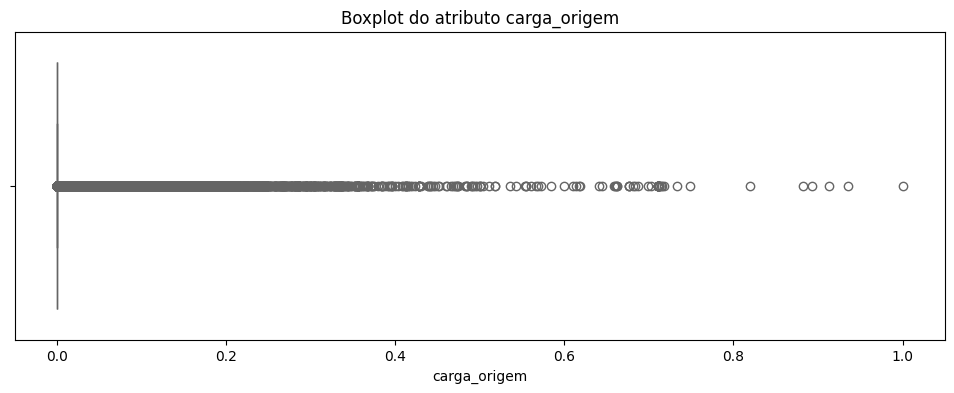




A coluna carga_origem não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo carga_origem:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo carga_origem: 

 - A média aritmética de seus valores é, aproximadamente, 0.01;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.01;


 Medidas de Dispersão e Amplitude

 - Amplitude: de -0.00 até 1.00. Variam em uma faixa de 1.00

 - Desvio Padrão: 0.03

 - Coeficiente de Variação: 5.35 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo carga_origem:

 - O valor do quartil de 25% é -0.00. Isto significa que 25% dos dados da amostra do atributo carga_origem são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da am

In [49]:
# Lista com o atributo desejado
coluna_alvo = ['carga_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True, limite_x=False)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo carga_origem apresenta um comportamento de assimetria positiva, característico de fluxos de rede onde a maior parte do tempo a carga é baixa, mas picos massivos ocorrem durante transferências de dados intensas ou ataques. O `histograma` e o `KDE` mostram uma concentração de dados quase total próxima ao zero, o que torna a `Curva Normal` uma linha praticamente horizontal e incapaz de descrever o fenômeno. A aplicação das regras de ouro reforça essa inadequação estatística, prevendo intervalos com valores negativos (até −552.463.104,00) que são impossíveis para uma métrica de carga de dados.

O `boxplot` revela uma cauda de outliers extremamente densa e longa, com o valor máximo atingindo 5.988.000.256,00. Embora o limite superior estatístico seja de aproximadamente 1.596.169,62, o atributo registra 16,06% de outliers superiores (15.548 registros). O `Coeficiente de Variação` de 5,35 e o fato de o `desvio padrão` (196.400.352,00) ser muito superior à média (36.737.904,00) confirmam a altíssima volatilidade e a presença de valores discrepantes que distorcem as medidas de tendência central.

Os `outliers serão mantidos`, pois, no contexto de segurança cibernética, a carga de origem é um indicador vital para identificar anomalias. Picos extremos de carga podem sinalizar atividades críticas, como exfiltração de dados em larga escala ou o início de um ataque de negação de serviço. A exclusão desses dados resultaria em um modelo incapaz de reconhecer as situações de maior risco, limitando sua eficácia apenas ao tráfego de rede convencional.

##### 2.10.2 Análise e visualização sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

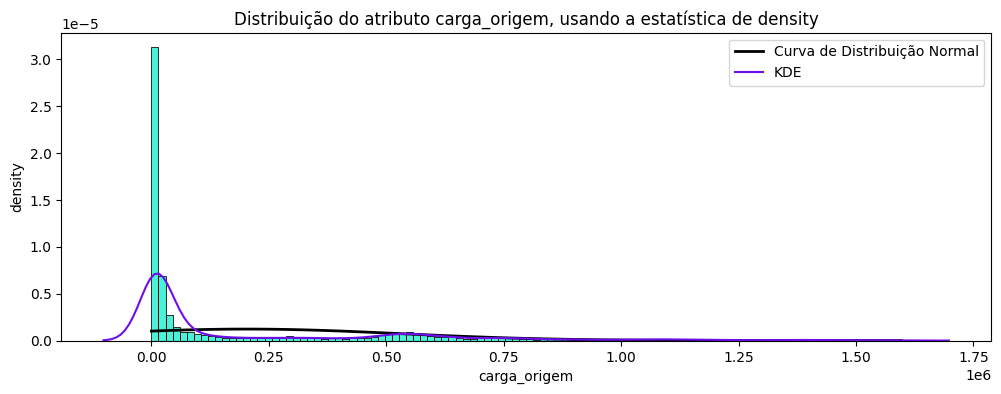

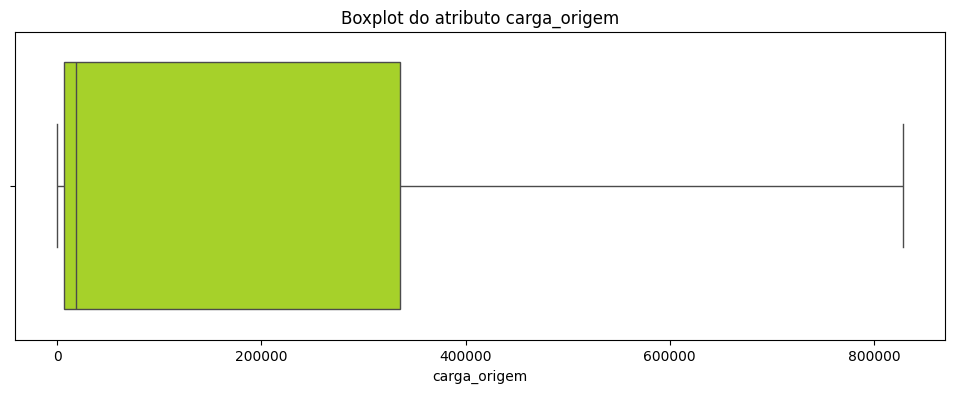






 Análise Básica do atributo carga_origem:

 - No total, há 81274 células e destas, 0 são nulas, 7991 estão repetidas e o total de valores unicos são 73283.


 Medidas de Tendência Central do atributo carga_origem: 

 - A média aritmética de seus valores é, aproximadamente, 202906.47;

 - A mediana é, aproximadamente, 18227.19;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 1596100.50. Variam em uma faixa de 1596100.50

 - Desvio Padrão: 325440.88

 - Coeficiente de Variação: 1.60 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo carga_origem:

 - 68% da amostra está compreendida entre, aproximadamente, -122534.40 e 528347.35;

 - 95% da amostra está compreendida entre, aproximadamente, -447975.28 e 853788.23;

 - 99.7% da amostra está compreendida entre, aproximadamente, -773416.16 e 1179229.11.


In [33]:
coluna_alvo = ['carga_origem']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 a 5,988,000,256.00 e agora é de 0 a 1,596,100.50.

#### 2.11. Atributo carga_destino
---

Este atributo **possui** outliers.

##### 2.11.1. Análise e visualização com outliers
---

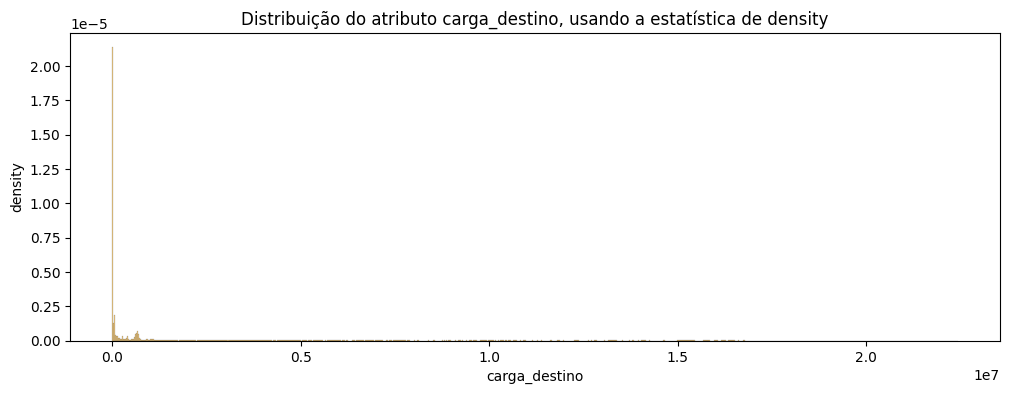

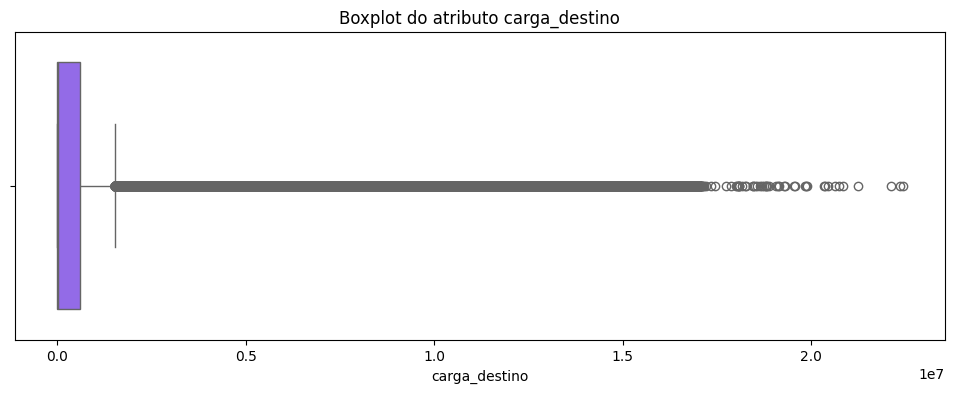






 Análise Básica do atributo carga_destino:

 - No total, há 96822 células e destas, 0 são nulas, 19348 estão repetidas e o total de valores unicos são 77474.


 Medidas de Tendência Central do atributo carga_destino: 

 - A média aritmética de seus valores é, aproximadamente, 1201663.74;

 - A mediana é, aproximadamente, 9971.82;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 22422730.00. Variam em uma faixa de 22422730.00

 - Desvio Padrão: 3158514.96

 - Coeficiente de Variação: 2.63 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo carga_destino:

 - O valor do quartil de 25% é 2972.23. Isto significa que 25% dos dados da amostra do atributo carga_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 9971.82. Isto significa que 50% dos dados da amostra do atributo carga_destino são me

In [45]:
# Lista com o atributo desejado
coluna_alvo = ['carga_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo carga_destino apresenta um comportamento de acentuada assimetria positiva, embora exiba características visuais nos gráficos que o distinguem dos atributos de volume anteriores. O `histograma` revela um pico muito pronunciado em torno de 0.00 (sua moda), enquanto o `KDE` mostra uma pequena elevação, mas que `não se sustenta como uma distribuição normal`. A aplicação da Regra de Ouro confirma essa inconsistência ao gerar intervalos teóricos com valores negativos (até −8.273.881,00), o que é fisicamente impossível no contexto de carga de dados.

No `boxplot`, a estrutura da amostra fica evidente: os quartis de 25% (2.972,23) e 50% (9.971,82) estão muito comprimidos na base, enquanto o quartil de 75% dispara para 613.657,62. Essa disparidade resulta em um limite superior de 1.529.685,71, classificando 13,88% dos registros (13.441 células) como outliers superiores. O alto `Coeficiente de Variação` (2,63) e o `desvio padrão` (3.158.515,00) quase três vezes maior que a média (1.201.663,75) indicam a presença de assimetria.

Os `outliers serão mantidos`, pois representam variações reais e legítimas (ou críticas) no comportamento do tráfego de rede. Em uma análise de segurança, descartar esses 13% de dados de alta carga poderia cegar o modelo para eventos de transferência pesada que frequentemente acompanham atividades anômalas ou ataques de exfiltração.

##### 2.11.2. Análise e visualização sem outliers
---

In [ ]:
Exclusão dos outliers e geração de gráficos e métricas:

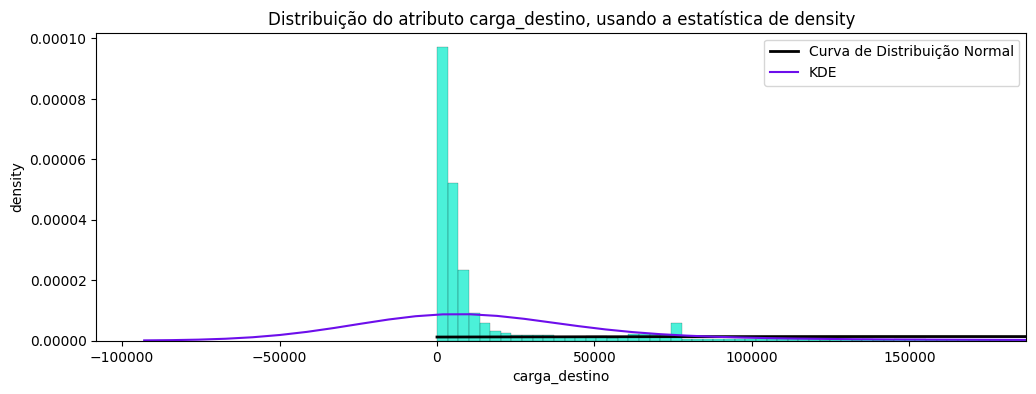

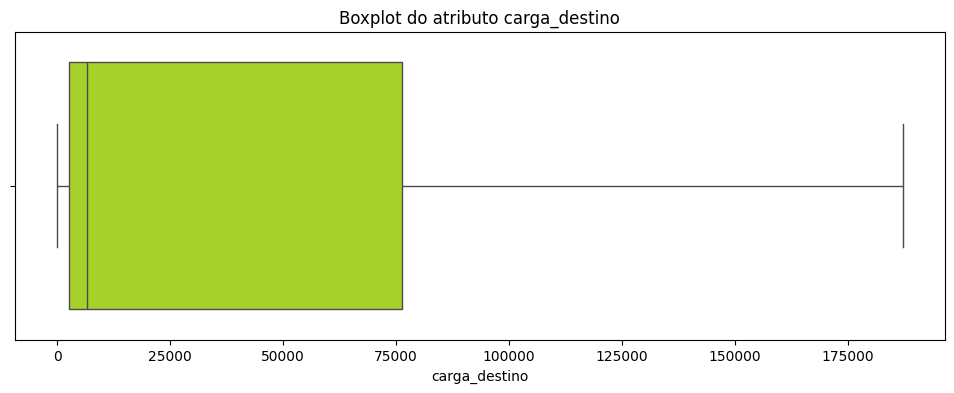






 Análise Básica do atributo carga_destino:

 - No total, há 83381 células e destas, 0 são nulas, 18667 estão repetidas e o total de valores unicos são 64714.


 Medidas de Tendência Central do atributo carga_destino: 

 - A média aritmética de seus valores é, aproximadamente, 151384.30;

 - A mediana é, aproximadamente, 6582.20;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 1529502.75. Variam em uma faixa de 1529502.75

 - Desvio Padrão: 298898.55

 - Coeficiente de Variação: 1.97 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo carga_destino:

 - 68% da amostra está compreendida entre, aproximadamente, -147514.24 e 450282.85;

 - 95% da amostra está compreendida entre, aproximadamente, -446412.79 e 749181.40;

 - 99.7% da amostra está compreendida entre, aproximadamente, -745311.34 e 1048079.95.


In [108]:
coluna_alvo = ['carga_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outlier(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=True, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 a 5,988,000,256.00 e agora é de 0 a 1,596,100.50.

#### 2.12. Atributo pacotes_perdidos_origem
---

##### 2.12.1. Análise com outliers
---

Este atributo **possui** outliers.

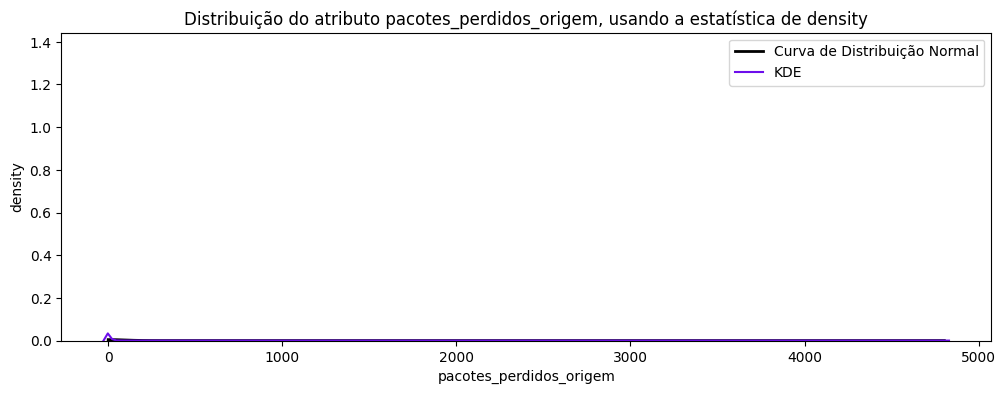

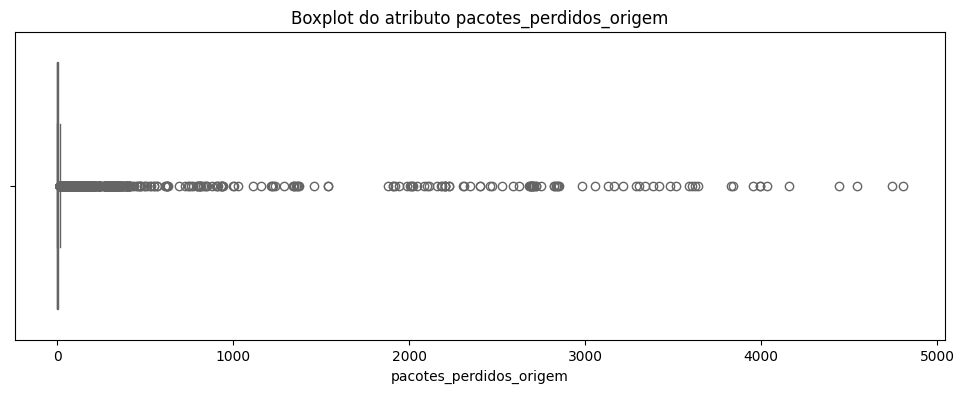






 Análise Básica do atributo pacotes_perdidos_origem:

 - No total, há 96822 células e destas, 0 são nulas, 96413 estão repetidas e o total de valores unicos são 409;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 8.78;

 - A mediana é, aproximadamente, 2.00;

 - A moda é, aproximadamente, 2.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 4803.00

 - Desvio Padrão: 88.60

 - Coeficiente de Variação: 10.09 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 2.00. Isto significa que 25% dos dados da amostra do atributo pacotes_perdidos_origem são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 2.00. Isto significa que 50% dos dados da amostra do atributo pacotes_perdidos_origem são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil de 75% é 7

In [52]:
# Lista com o atributo desejado
coluna_alvo = ['pacotes_perdidos_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo pacotes_perdidos_origem apresenta um comportamento de assimetria positiva, com uma `distribuição não normal`. O `histograma` e o `KDE` revelam uma concentração massiva de dados no valor 2.00 (moda e mediana), criando um pico isolado à esquerda, enquanto a `Curva Normal` aparece totalmente achatada. A aplicação das regras de ouro confirma essa inconsistência ao sugerir intervalos com limites negativos (até −257.03), o que é impossível para uma contagem de pacotes perdidos.

No `boxplot`, a estrutura de dados mostra uma compressão notável nos quartis iniciais: 50% dos dados são iguais a 2.00, e 75% chegam a apenas 7.00. No entanto, a cauda de outliers é extensa, atingindo o valor máximo de 4803.00. Com um limite superior estatístico de 14.50, o atributo registra 8.09% de outliers superiores (7.835 registros). O `Coeficiente de Variação` de 10.09 e o fato de o `desvio padrão` (88.60) ser dez vezes superior à média (8.78) ratificam a volatilidade extrema e a presença de picos que fogem completamente ao padrão da maioria das conexões.

Os `outliers serão mantidos`, pois, conforme você pontuou, eles carregam a assinatura de eventos reais e críticos. Em redes, perdas massivas de pacotes não são apenas ruído; elas são sintomas diretos de congestionamento severo, falhas de infraestrutura ou, mais importante para este estudo, ataques de negação de serviço (DoS). No caso do protocolo UDP, essa métrica é ainda mais sensível, pois a ausência de mecanismos de retransmissão torna esses picos de perda evidências irrefutáveis de degradação do canal, informações que o modelo de Machine Learning precisa processar para classificar anomalias com precisão.

##### 2.12.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

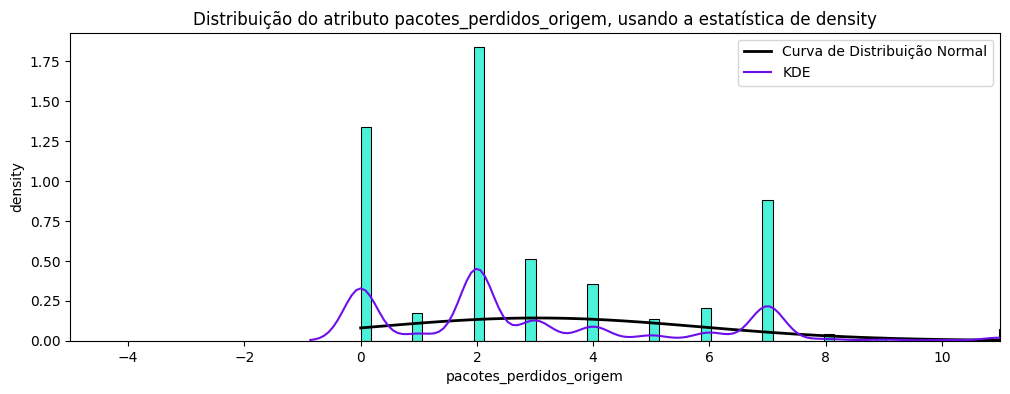

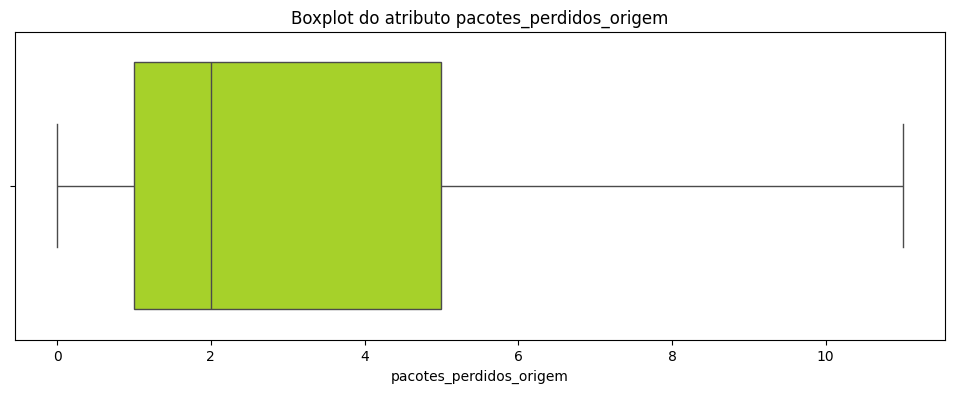






 Análise Básica do atributo pacotes_perdidos_origem:

 - No total, há 88987 células e destas, 0 são nulas, 88972 estão repetidas e o total de valores unicos são 15.


 Medidas de Tendência Central do atributo pacotes_perdidos_origem: 

 - A média aritmética de seus valores é, aproximadamente, 3.04;

 - A mediana é, aproximadamente, 2.00;

 - A moda é, aproximadamente, 2.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 14.00. Variam em uma faixa de 14.00

 - Desvio Padrão: 2.82

 - Coeficiente de Variação: 0.93 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.22 a 5.86 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo pacotes_perdidos_origem:

 - 68% da amostra está compreendida entre, aproximadamente, 0.22 e 5.86;

 - 95% da amostra está compreendida entre, aproximadamente, -2.60 e 8.68;

 - 99.7% da amostra está compreendida entre, aproximadamente, -5.42 e 11.50.


In [111]:
coluna_alvo = ['pacotes_perdidos_origem']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=True, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 4803.00 e agora é de 0.00 até 14.00.

#### 2.13. Atributo pacotes_perdidos_destino
---

Este atributo **possui** outliers.

##### 2.13.1. Análise com outliers
---

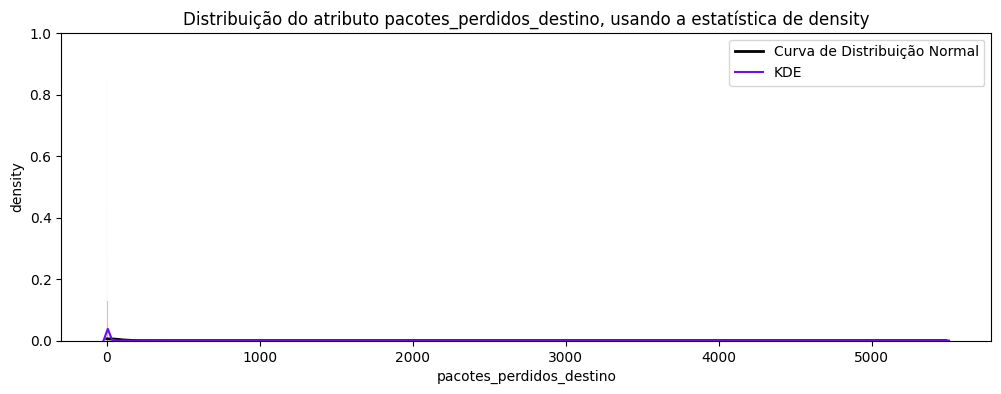

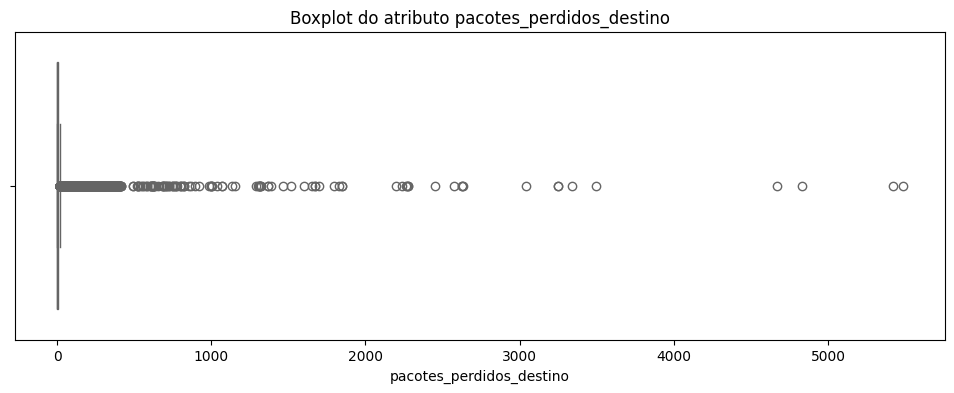






 Análise Básica do atributo pacotes_perdidos_destino:

 - No total, há 96822 células e destas, 0 são nulas, 96452 estão repetidas e o total de valores unicos são 370;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 12.24;

 - A mediana é, aproximadamente, 2.00;

 - A moda é, aproximadamente, 1.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 5484.00

 - Desvio Padrão: 68.91

 - Coeficiente de Variação: 5.63 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 1.00. Isto significa que 25% dos dados da amostra do atributo pacotes_perdidos_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 2.00. Isto significa que 50% dos dados da amostra do atributo pacotes_perdidos_destino são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil de 75% 

In [53]:
# Lista com o atributo desejado
coluna_alvo = ['pacotes_perdidos_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo pacotes_perdidos_destino espelha o comportamento de assimetria positiva observado na origem, caracterizando-se por uma `distribuição não normal`. O `histograma` e o `KDE` mostram um pico isolado à esquerda, centrado na moda de 1.00, enquanto a `Curva Normal` permanece achatada e desconexa da realidade dos dados. A inadequação do modelo normal é comprovada pelas regras de ouro, que sugerem valores negativos (até −194.50) para uma métrica que é, por natureza, uma contagem de eventos.

No `boxplot`, a alta densidade de outliers superiores (12,88% do total, ou 12.472 registros) contrasta com a mediana de apenas 2.00. O `Coeficiente de Variação` de 5.63 e o `desvio padrã`o (68.91) significativamente superior à média (12.24) ratificam a presença de eventos extremos e a alta dispersão da amostra.

Os `outliers serão mantidos`, pois são indicadores críticos de anomalias na rede. Conforme analisado, esses picos de perda no destino são evidências diretas de congestionamento de rede ou ataques de negação de serviço (DoS), especialmente quando o protocolo UDP está em uso, já que sua falta de mecanismos de retransmissão torna qualquer interrupção visível apenas como perda definitiva de pacotes.

##### 2.13.2. Análise sem outlers
---

Exclusão dos outliers e geração de gráficos e métricas:

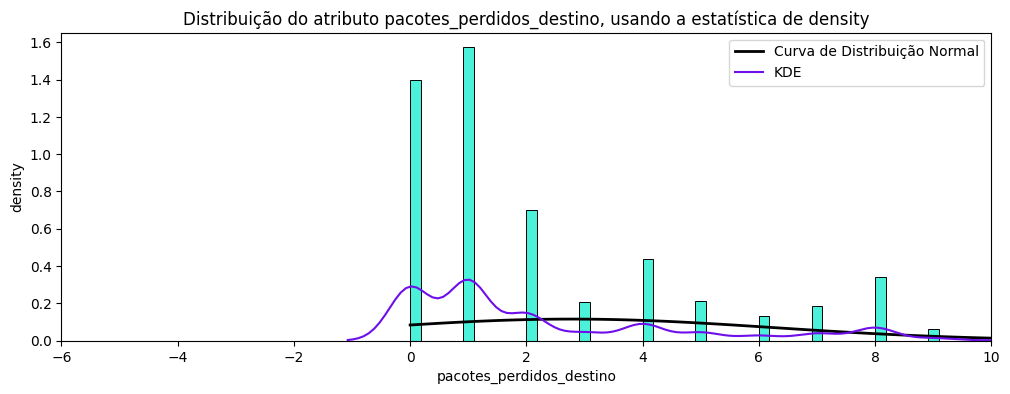

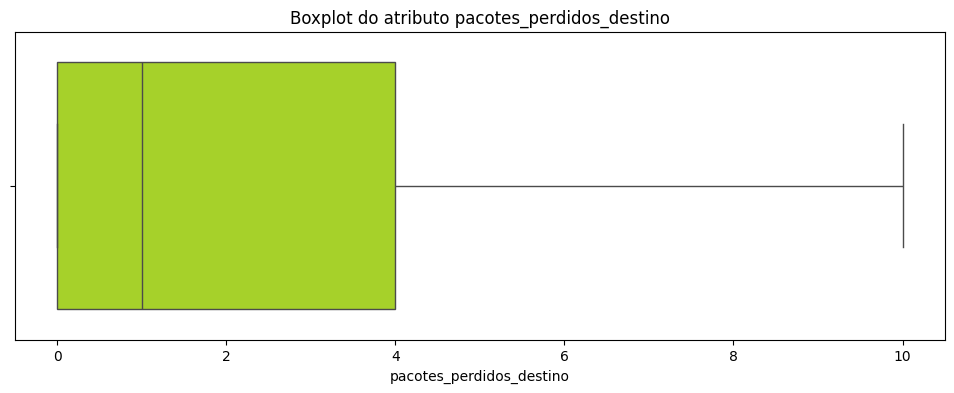






 Análise Básica do atributo pacotes_perdidos_destino:

 - No total, há 84350 células e destas, 0 são nulas, 84333 estão repetidas e o total de valores unicos são 17.


 Medidas de Tendência Central do atributo pacotes_perdidos_destino: 

 - A média aritmética de seus valores é, aproximadamente, 2.78;

 - A mediana é, aproximadamente, 1.00;

 - A moda é, aproximadamente, 1.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 16.00. Variam em uma faixa de 16.00

 - Desvio Padrão: 3.46

 - Coeficiente de Variação: 1.24 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo pacotes_perdidos_destino:

 - 68% da amostra está compreendida entre, aproximadamente, -0.68 e 6.24;

 - 95% da amostra está compreendida entre, aproximadamente, -4.14 e 9.70;

 - 99.7% da amostra está compreendida entre, aproximadamente, -7.60 e 13.16.


In [35]:
coluna_alvo = ['pacotes_perdidos_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=True, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 5484.00 e agora é de 0.00 até 16.00.

#### 2.14. Atributo tempo_medio_pacote_origem
---

Esse atributo **possui** outliers.

##### 2.14.1. Análise com outliers
---

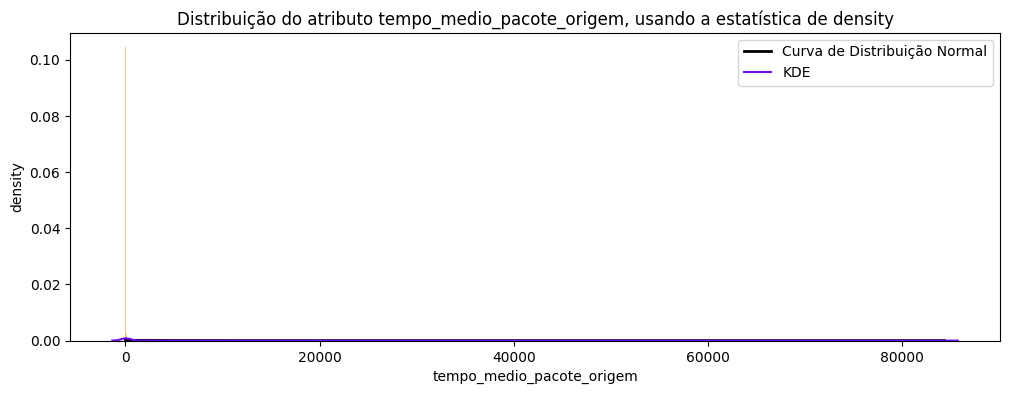

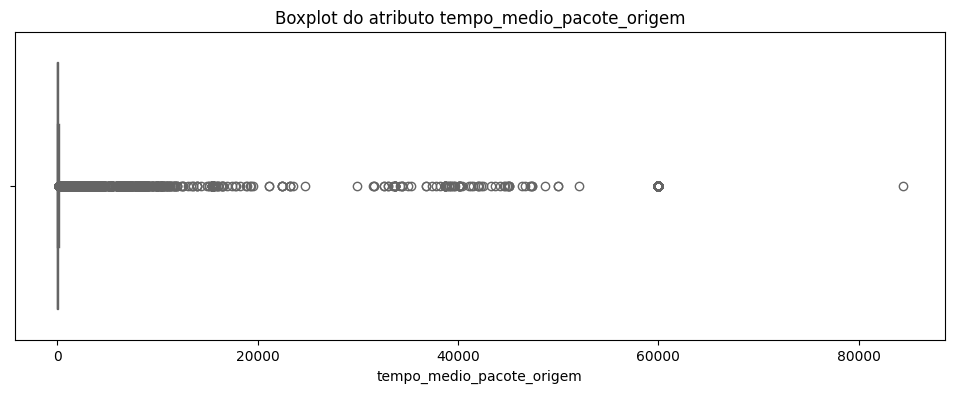






 Análise Básica do atributo tempo_medio_pacote_origem:

 - No total, há 96822 células e destas, 0 são nulas, 20772 estão repetidas e o total de valores unicos são 76050.


 Medidas de Tendência Central do atributo tempo_medio_pacote_origem: 

 - A média aritmética de seus valores é, aproximadamente, 452.94;

 - A mediana é, aproximadamente, 28.60;

 - A moda é, aproximadamente, 0.01;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 84371.49. Variam em uma faixa de 84371.49

 - Desvio Padrão: 4496.90

 - Coeficiente de Variação: 9.93 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo tempo_medio_pacote_origem:

 - O valor do quartil de 25% é 0.52. Isto significa que 25% dos dados da amostra do atributo tempo_medio_pacote_origem são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 28.60. Isto significa que 50% dos dados da amostra do a

In [36]:
# Lista com o atributo desejado
coluna_alvo = ['tempo_medio_pacote_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

A análise do atributo tempo_medio_pacote_origem revela uma distribuição de assimetria positiva, com a maioria dos registros concentrada em valores muito baixos, próximos a zero. O `histograma` apresenta um pico agudo na base, refletindo a moda de 0.01 e a mediana de 28.60, que estão drasticamente distantes da média de 452.94. Esse contraste, somado a um `Desvio Padrão` (4.496,90) que é quase dez vezes superior à média, resulta em um `Coeficiente de Variação` de 9,93, confirmando uma dispersão muito alta e a `inadequação da distribuição normal`.

No `boxplot`, observa-se que 75% dos dados estão contidos abaixo de 79.66, mas a cauda de outliers se estende até o valor máximo de 84.371,49. Com um limite superior estatístico de 198.38, o atributo identifica 5,17% de outliers superiores (5.010 registros). A visualização gráfica mostra esses valores discrepantes inicialmente densos após o limite, tornando-se esparsos e isolados nos extremos da escala.

Os `outliers serão mantidos `por representarem variações legítimas e críticas no ambiente de rede. Tempos médios de pacotes elevados (alta latência) são indicadores fundamentais de:

- Congestionamento de Rede: Sobrecarga em roteadores ou links de comunicação.

- Performance de Servidor: Atrasos no processamento de requisições na origem.

- Atividade Maliciosa: Presença de malwares ou ataques que injetam tráfego espúrio ou manipulam o fluxo normal de pacotes.

##### 2.14.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

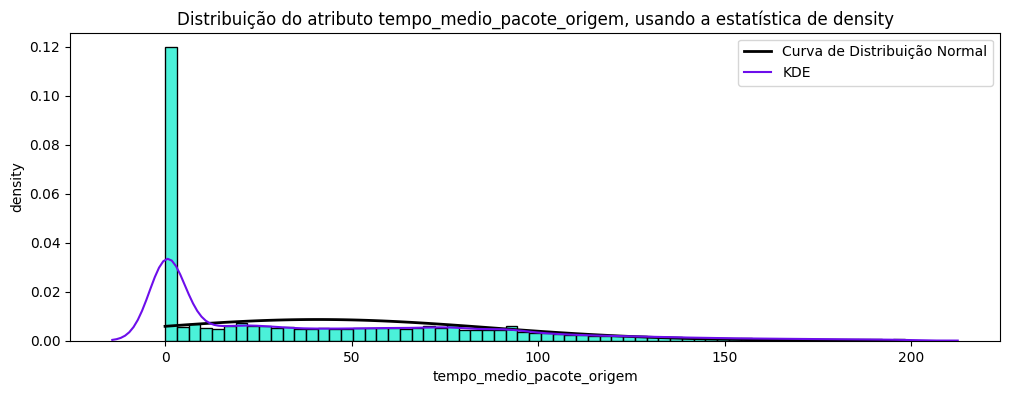

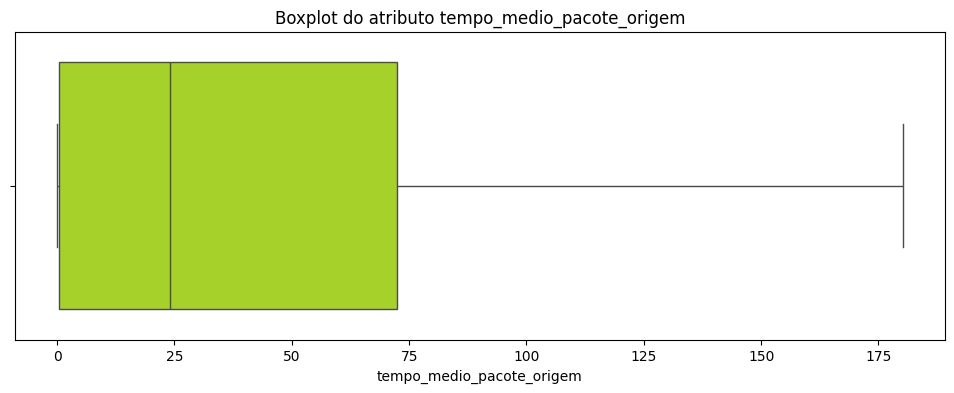






 Análise Básica do atributo tempo_medio_pacote_origem:

 - No total, há 91812 células e destas, 0 são nulas, 19796 estão repetidas e o total de valores unicos são 72016.


 Medidas de Tendência Central do atributo tempo_medio_pacote_origem: 

 - A média aritmética de seus valores é, aproximadamente, 40.98;

 - A mediana é, aproximadamente, 24.14;

 - A moda é, aproximadamente, 0.01;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 198.36. Variam em uma faixa de 198.36

 - Desvio Padrão: 46.34

 - Coeficiente de Variação: 1.13 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo tempo_medio_pacote_origem:

 - 68% da amostra está compreendida entre, aproximadamente, -5.36 e 87.32;

 - 95% da amostra está compreendida entre, aproximadamente, -51.70 e 133.66;

 - 99.7% da amostra está compreendida entre, aproximadamente, -98.05 e 180.00.


In [37]:
coluna_alvo = ['tempo_medio_pacote_origem']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 84371.49 e agora é de  0.00 até 198.36.

#### 2.15. Atributo bytes_por_pacote_destino
---

Este atributo **possui** outliers.

##### 2.15.1. Análise com outliers
---

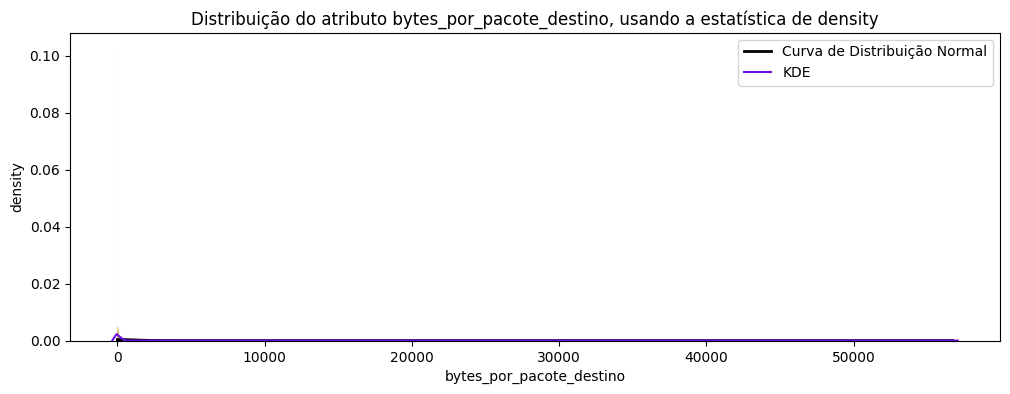

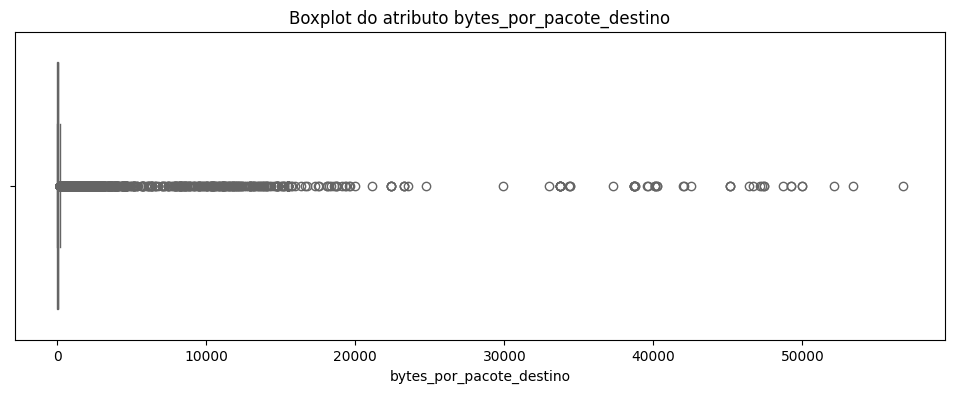






 Análise Básica do atributo bytes_por_pacote_destino:

 - No total, há 96822 células e destas, 0 são nulas, 22645 estão repetidas e o total de valores unicos são 74177;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 116.00;

 - A mediana é, aproximadamente, 30.69;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 56716.82

 - Desvio Padrão: 1137.70

 - Coeficiente de Variação: 9.81 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 0.36. Isto significa que 25% dos dados da amostra do atributo bytes_por_pacote_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 30.69. Isto significa que 50% dos dados da amostra do atributo bytes_por_pacote_destino são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil

In [55]:
# Lista com o atributo desejado
coluna_alvo = ['bytes_por_pacote_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

A análise do atributo bytes_por_pacote_destino confirma o padrão de assimetria positiva acentuada e `não normalidade` observado nos indicadores técnicos da rede. O `histograma` e o `KDE` mostram uma concentração alta de registros em valores baixos, com a moda em 0.00 indicando que uma parte significativa do tráfego não transporta carga útil no destino. A `Curva Normal` aparece severamente achatada, e a aplicação das regras de ouro resulta em limites negativos (até −3297.11), o que é fisicamente impossível para o tamanho de pacotes.

No `boxplot`, a estrutura dos dados revela quartis comprimidos próximos a zero: 50% dos registros estão abaixo de 30.69, e 75% não ultrapassam 88.59. Entretanto, a amplitude chega a 56716.82, resultando em um `Desvio Padrão` (1137.70) quase dez vezes maior que a média (116.00) e um `Coeficiente de Variação` de 9.81. Nesse cenário, há 3.62% de outliers superiores (3.506 registros) que começam a partir do limite estatístico de 220.93.

Os `outliers serão mantidos`, pois são fundamentais para o contexto de segurança e análise de rede:

- Variabilidade de Carga: O tamanho dos pacotes pode variar drasticamente dependendo da aplicação ou do protocolo utilizado.

- Anomalias e Ataques: Valores extremamente altos podem indicar exfiltração de dados ou ataques mais complexos que utilizam pacotes de tamanho não convencional para evadir sistemas de detecção simples.

##### 2.15.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

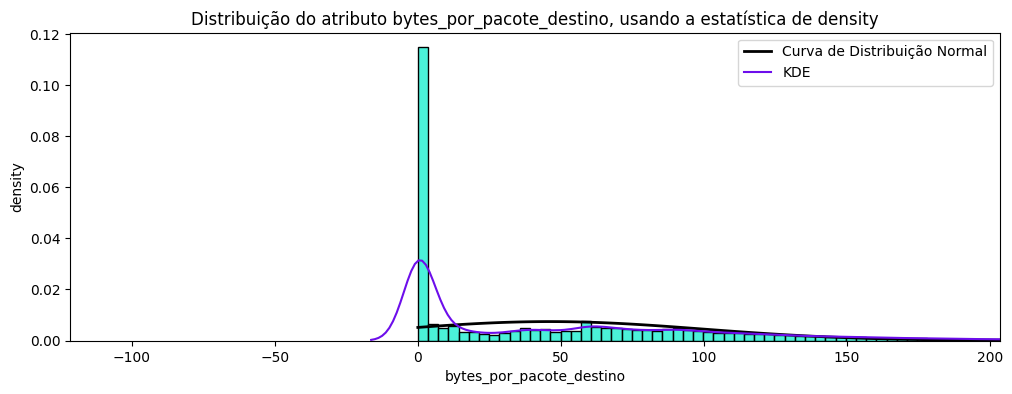

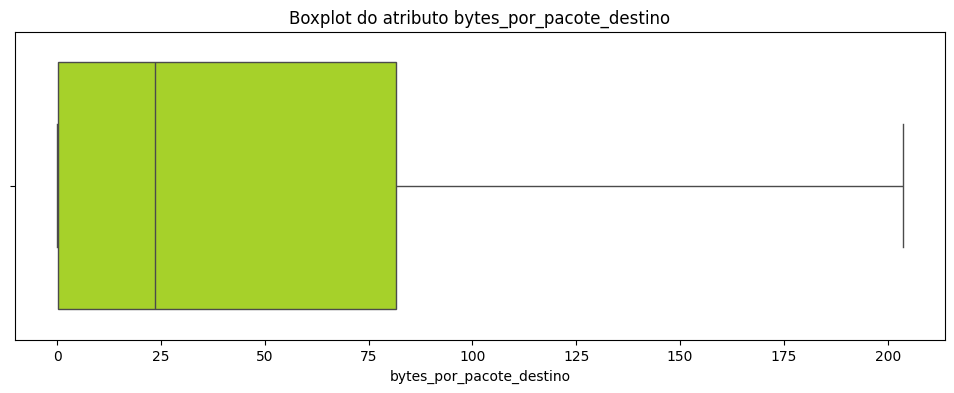






 Análise Básica do atributo bytes_por_pacote_destino:

 - No total, há 93316 células e destas, 0 são nulas, 22562 estão repetidas e o total de valores unicos são 70754.


 Medidas de Tendência Central do atributo bytes_por_pacote_destino: 

 - A média aritmética de seus valores é, aproximadamente, 46.06;

 - A mediana é, aproximadamente, 23.56;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 220.92. Variam em uma faixa de 220.92

 - Desvio Padrão: 53.66

 - Coeficiente de Variação: 1.16 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo bytes_por_pacote_destino:

 - 68% da amostra está compreendida entre, aproximadamente, -7.60 e 99.72;

 - 95% da amostra está compreendida entre, aproximadamente, -61.25 e 153.37;

 - 99.7% da amostra está compreendida entre, aproximadamente, -114.91 e 207.03.


In [38]:
coluna_alvo = ['bytes_por_pacote_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=True, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a distribuição não é normal tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 56716.82 e agora é de  0.00 até 220.92.

#### 2.16. Atributo var_lat_pacotes_origem
---

Este atributo **possui** outliers.

##### 2.16.1. Análise com outliers
---

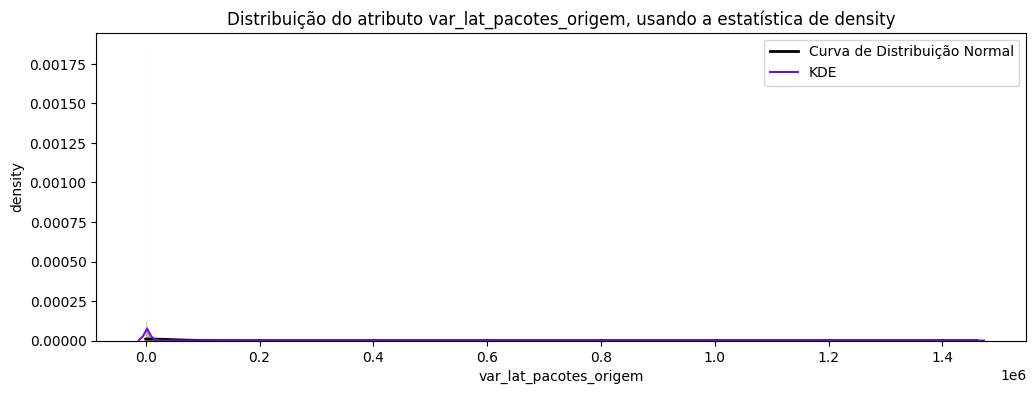

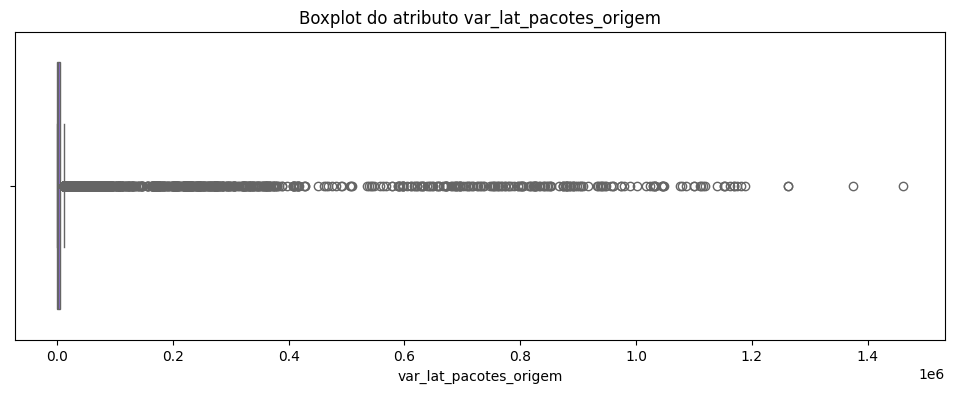






 Análise Básica do atributo var_lat_pacotes_origem:

 - No total, há 96822 células e destas, 0 são nulas, 19432 estão repetidas e o total de valores unicos são 77390.


 Medidas de Tendência Central do atributo var_lat_pacotes_origem: 

 - A média aritmética de seus valores é, aproximadamente, 5879.52;

 - A mediana é, aproximadamente, 1600.61;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 1460480.00. Variam em uma faixa de 1460480.00

 - Desvio Padrão: 41461.23

 - Coeficiente de Variação: 7.05 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo var_lat_pacotes_origem:

 - O valor do quartil de 25% é 21.23. Isto significa que 25% dos dados da amostra do atributo var_lat_pacotes_origem são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 1600.61. Isto significa que 50% dos dados da amostra do at

In [39]:
# Lista com o atributo desejado
coluna_alvo = ['var_lat_pacotes_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

A análise do atributo `var_lat_pacotes_origem` revela um comportamento de acentuada assimetria positiva, alinhado ao padrão observado nos demais indicadores de performance da rede. O `histograma` e o `KDE` apresentam um pico de densidade isolado próximo ao valor 0.00 (sua moda), enquanto a `Curva Normal` aparece notavelmente achatada e incapaz de representar a realidade dos dados. A aplicação das regras de ouro confirma essa inconsistência estatística ao sugerir intervalos com limites negativos (até -118504.16), o que é logicamente impossível para uma medida de variância de tempo.

O `boxplot` indica uma alta dispersão na cauda superior da distribuição. Enquanto 75% dos dados estão compreendidos abaixo de 4671.91, a amplitude total do atributo atinge o valor máximo de 1460480.00. Com um limite superior estatístico de aproximadamente 11647.92, o atributo identifica 4,29% de outliers superiores (4.154 registros). O `Coeficiente de Variação`de 7.05 e o `desvio padrão` (41461.23) sendo sete vezes superior à média (5879.52) confirmam a presença de picos de alta dispersão que fogem completamente ao comportamento da massa principal de dados.



Os `outliers serão mantidos`, pois a variação de latência (jitter) é uma métrica real e um indicador crítico de saúde da rede. Valores discrepantes de jitter não são erros de leitura, mas sim evidências de instabilidade no link, congestionamento de buffers ou processamento irregular de pacotes na origem. No contexto de segurança, essas variações extremas podem representar assinaturas de ataques ou a presença de tráfego espúrio injetado por malwares, informações indispensáveis para que o modelo de Machine Learning identifique anomalias com precisão.

##### 2.16.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

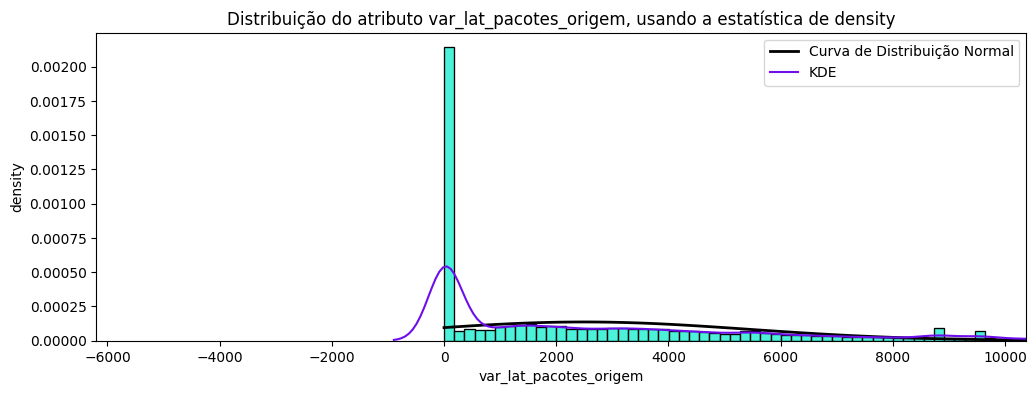

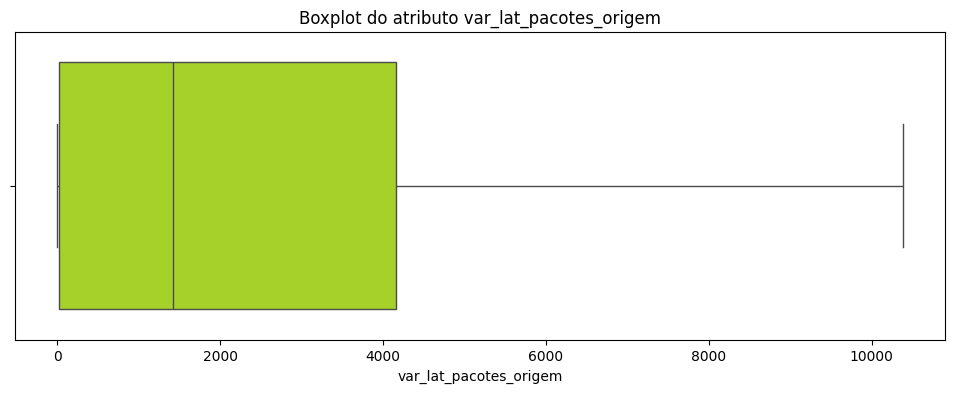






 Análise Básica do atributo var_lat_pacotes_origem:

 - No total, há 92668 células e destas, 0 são nulas, 19378 estão repetidas e o total de valores unicos são 73290.


 Medidas de Tendência Central do atributo var_lat_pacotes_origem: 

 - A média aritmética de seus valores é, aproximadamente, 2496.52;

 - A mediana é, aproximadamente, 1421.98;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 11644.13. Variam em uma faixa de 11644.13

 - Desvio Padrão: 2934.65

 - Coeficiente de Variação: 1.18 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo var_lat_pacotes_origem:

 - 68% da amostra está compreendida entre, aproximadamente, -438.13 e 5431.17;

 - 95% da amostra está compreendida entre, aproximadamente, -3372.78 e 8365.82;

 - 99.7% da amostra está compreendida entre, aproximadamente, -6307.42 e 11300.

In [40]:
coluna_alvo = ['var_lat_pacotes_origem']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=True, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 1460480.00 e agora é de  0.00 até 11644.13.

#### 2.17.  Atributo var_lat_pacotes_destino
---

Este atributo **possui** outliers.

##### 2.17.1. Análise com outliers
---

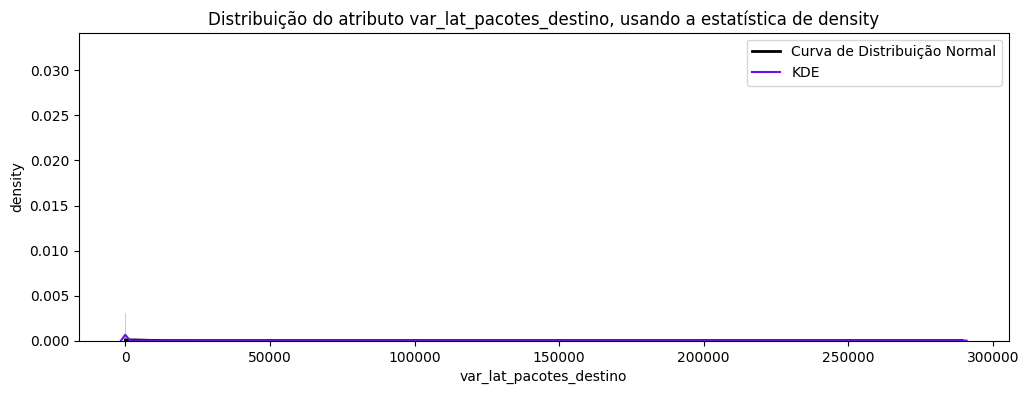

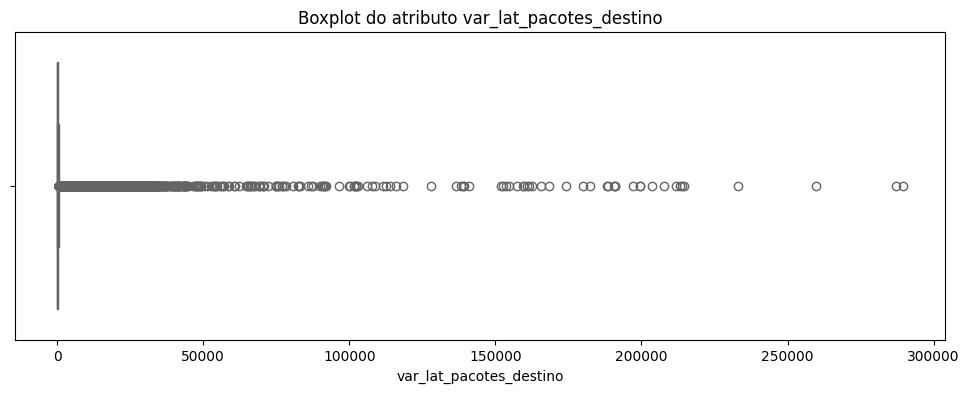






 Análise Básica do atributo var_lat_pacotes_destino:

 - No total, há 96822 células e destas, 0 são nulas, 20079 estão repetidas e o total de valores unicos são 76743.


 Medidas de Tendência Central do atributo var_lat_pacotes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 909.05;

 - A mediana é, aproximadamente, 81.66;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 289388.28. Variam em uma faixa de 289388.28

 - Desvio Padrão: 5047.60

 - Coeficiente de Variação: 5.55 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo var_lat_pacotes_destino:

 - O valor do quartil de 25% é 1.40. Isto significa que 25% dos dados da amostra do atributo var_lat_pacotes_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 81.66. Isto significa que 50% dos dados da amostra do atribut

In [41]:
# Lista com o atributo desejado
coluna_alvo = ['var_lat_pacotes_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

A análise do atributo var_lat_pacotes_destino (jitter no destino), mantêm o perfil de assimetria positiva e `não normalidade` identificado em todo o dataset, até então. O `histograma` e o `KDE` revelam uma concentração muito alta de dados na base, com a moda em 0.00 e a mediana em 81.66, enquanto a `Curva Normal` aparece totalmente achatada e desconectada da distribuição real. A aplicação das regras de ouro reforça essa distorção ao sugerir intervalos com limites negativos (até −14.233,77), o que é impossível para uma métrica de variação de tempo.

No `boxplot`, a estrutura dos dados mostra uma compressão nos quartis iniciais (75% dos dados estão abaixo de 205.20), mas com uma cauda de dispersão que atinge o valor máximo de 289.388,28. Com um limite superior estatístico de 510.90, o atributo registra 14,09% de outliers superiores (13.647 registros). O `Coeficiente de Variação` de 5.55 e o `desvio padrão` (5.047,60) significativamente maior que a média (909.05) confirmam a presença de eventos de alta latência no recebimento dos pacotes.

Os `outliers serão mantidos`, pois, assim como na origem, a variação de latência no destino é um indicador diagnóstico fundamental. Picos elevados de jitter no recebimento costumam ser sintomas de congestionamento de rede, instabilidade na rota de retorno ou sobrecarga no processamento do destinatário. Em um cenário de cibersegurança, essas flutuações extremas podem sinalizar comportamentos anômalos típicos de ataques de negação de serviço ou tráfego de comando e controle (C2) operando sob condições de rede degradadas.

##### 2.17.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

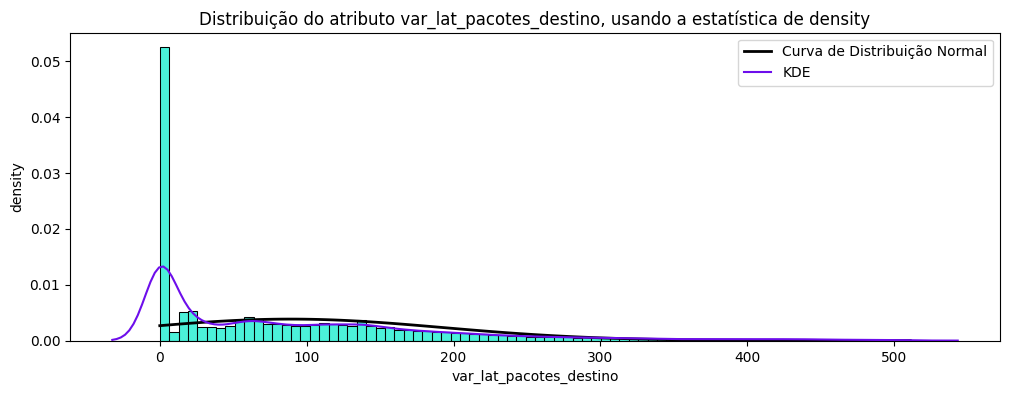

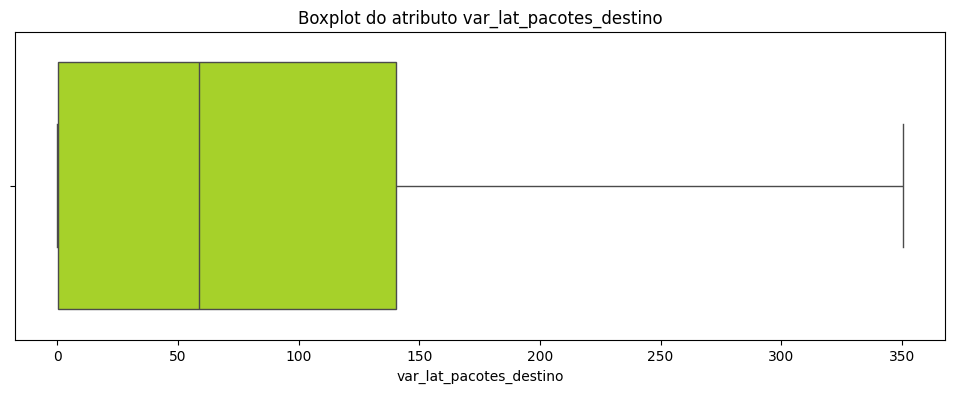






 Análise Básica do atributo var_lat_pacotes_destino:

 - No total, há 83175 células e destas, 0 são nulas, 19888 estão repetidas e o total de valores unicos são 63287.


 Medidas de Tendência Central do atributo var_lat_pacotes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 88.90;

 - A mediana é, aproximadamente, 58.65;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 510.87. Variam em uma faixa de 510.87

 - Desvio Padrão: 103.84

 - Coeficiente de Variação: 1.17 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo var_lat_pacotes_destino:

 - 68% da amostra está compreendida entre, aproximadamente, -14.93 e 192.74;

 - 95% da amostra está compreendida entre, aproximadamente, -118.77 e 296.58;

 - 99.7% da amostra está compreendida entre, aproximadamente, -222.61 e 400.41.


In [42]:
coluna_alvo = ['var_lat_pacotes_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a distribuição não é normal tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 289388.28 e agora é de 0.00 até 510.87.

#### 2.18.  Atributo tamanho_janela_tcp_origem
---

ESte atributo **possui** outliers.

##### 2.18.1. Análise com outliers
---

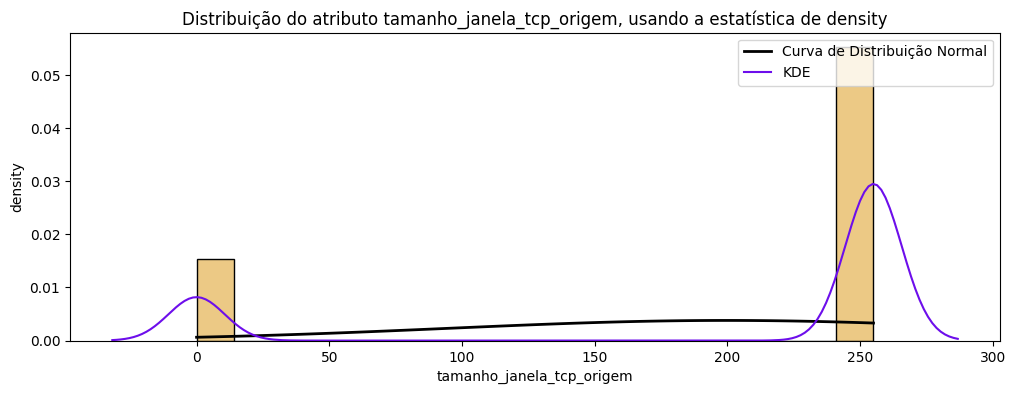

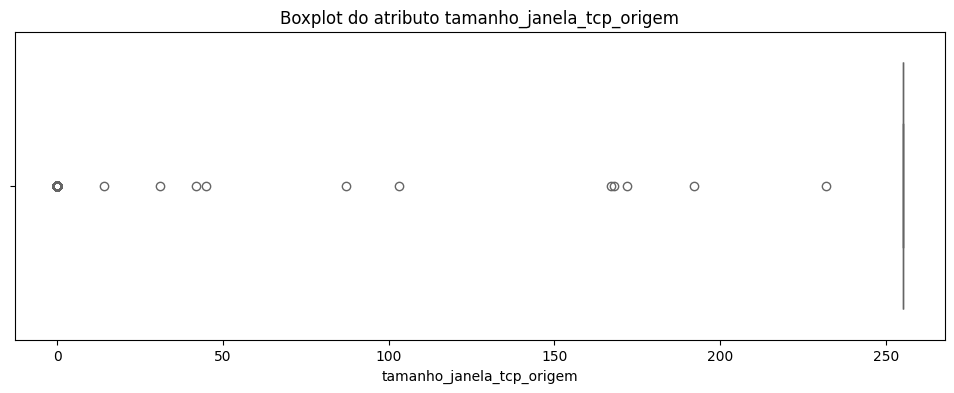






 Análise Básica do atributo tamanho_janela_tcp_origem:

 - No total, há 96822 células e destas, 0 são nulas, 96809 estão repetidas e o total de valores unicos são 13;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 199.63;

 - A mediana é, aproximadamente, 255.00;

 - A moda é, aproximadamente, 255.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 255.00

 - Desvio Padrão: 105.13

 - Coeficiente de Variação: 0.53 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 94.50 a 304.76 (em caso de normalidade).


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 255.00. Isto significa que 25% dos dados da amostra do atributo tamanho_janela_tcp_origem são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 255.00. Isto significa que 50% dos dados da amostra do atributo tamanho_janela_tcp_origem são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil de 7

In [27]:
# Lista com o atributo desejado
coluna_alvo = ['tamanho_janela_tcp_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

A análise do atributo tamanho_janela_tcp_origem apresenta um comportamento mais raro, em comparação aos demais indicadores técnicos, caracterizando-se por uma `distribuição não normal`, concentrada em dois polos: 0 e 255. O `histograma` e o `KDE` revelam dois picos distintos, com uma predominância absoluta do valor 255.00, que atua simultaneamente como a moda, a mediana e todos os três quartis (25%, 50% e 75%). Embora a `Curva Normal` se aproxima mais ao formato de um sino, em comparação a outros atributos, a presença de valores negativos nas regras de ouro (até −115.76) e a natureza discreta dos dados confirmam que a distribuição não é normal.

O `boxplot` deste atributo foge ao padrão, da maioria dos anteriores, ao identificar exclusivamente outliers inferiores. Como o limite inferior calculado coincide com o valor máximo de 255.00, qualquer registro abaixo desse patamar é estatisticamente considerado uma discrepância. Isso resulta em um volume expressivo de 21.72% de outliers inferiores (21.028 registros), espalhados entre 0 e valores próximos ao topo da escala. O `Coeficiente de Variação` de 0.53, sendo inferior a 1, indica uma dispersão moderada.

Os `outliers serão mantidos`, pois o tamanho da janela TCP é um mecanismo vital de controle de fluxo e congestionamento:

- Gerenciamento de Recursos: Valores baixos ou zerados indicam que o receptor está temporariamente sem buffer para processar novos dados, sinalizando gargalos reais.

- Dinâmica de Conexão: Janelas pequenas são comuns em fases de estabelecimento (handshake) ou encerramento de conexão.

- Detecção de Anomalias: No contexto de segurança, manipulações no tamanho da janela podem ser utilizadas para ataques de negação de serviço (como o Sockstress) ou para evadir sistemas de detecção, tornando esses "outliers" peças-chave para o treinamento do seu modelo.

##### 2.18.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

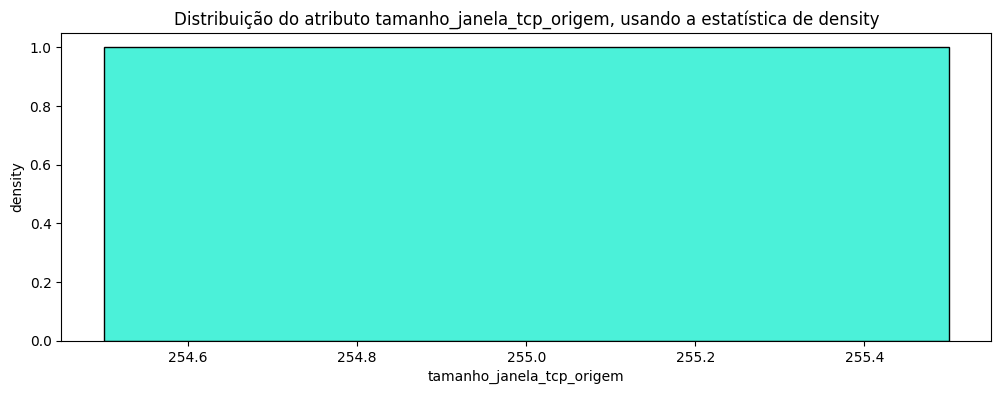

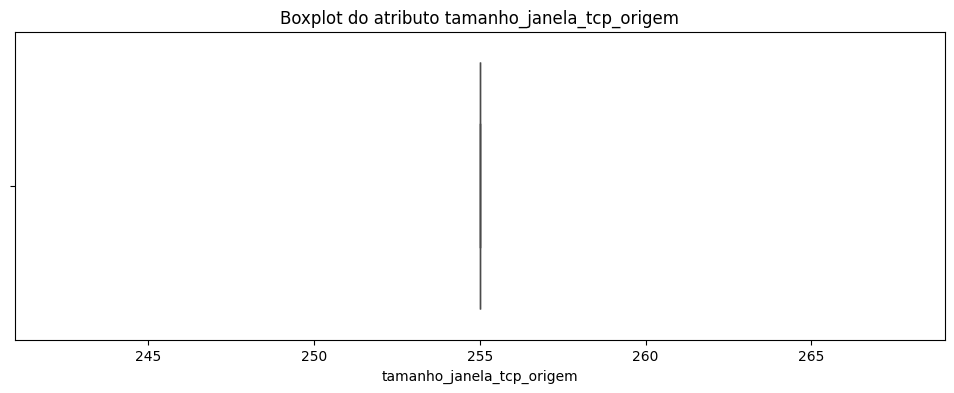




A coluna tamanho_janela_tcp_origem não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo tamanho_janela_tcp_origem:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo tamanho_janela_tcp_origem: 

 - A média aritmética de seus valores é, aproximadamente, 255.00;

 - A mediana é, aproximadamente, 255.00;

 - A moda é, aproximadamente, 255.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 255.00 até 255.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 255.00 a 255.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo tamanho_janela_tcp_origem:

 - 68% da amostra está compreendida entre, aproximadamente, 255.00 e 255.00;

 - 95% da amostra está compreendida entre, aproximadamente, 255.00 e 255.00;

 

In [43]:
coluna_alvo = ['tamanho_janela_tcp_origem']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 até 255.00 e agora é de 255.00 até 255.00.

#### 2.19.  Atributo num_sequencia_tcp_origem
---

Este atributo **não possui** outliers.

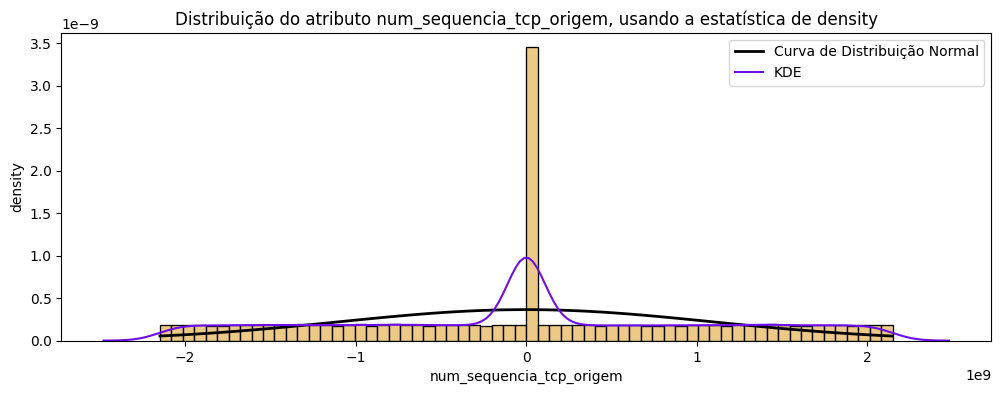

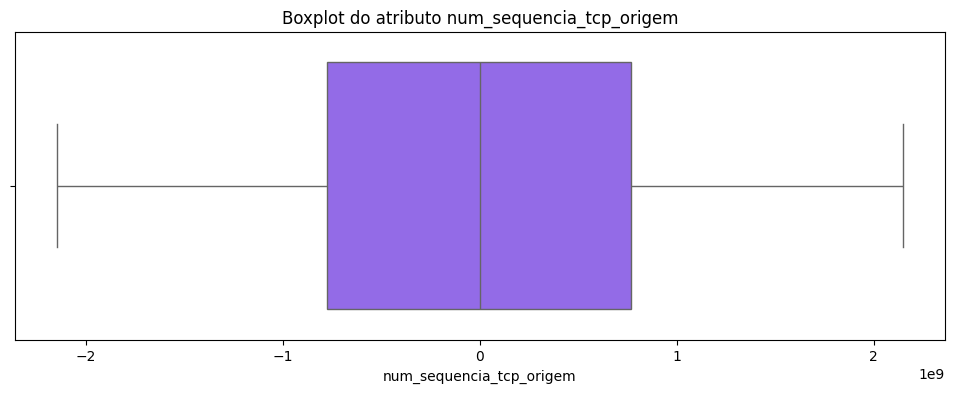






 Análise Básica do atributo num_sequencia_tcp_origem:

 - No total, há 96822 células e destas, 0 são nulas, 21557 estão repetidas e o total de valores unicos são 75265;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, -3099677.55;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de -2147477763.00 até 2147413428.00

 - Desvio Padrão: 1095013585.17

 - Coeficiente de Variação: -353.27 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é -778049723.00. Isto significa que 25% dos dados da amostra do atributo num_sequencia_tcp_origem são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo num_sequencia_tcp_origem são menores ou iguais a esse valor. Equiva

In [28]:
# Lista com o atributo desejado
coluna_alvo = ['num_sequencia_tcp_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

A análise do atributo num_sequencia_tcp_origem apresenta um perfil estatístico especial em seu dataset, caracterizando-se por uma distribuição `não normal` com um centro de massa em 0.00, mas com uma dispersão que abrange quase toda a amplitude permitida pelo protocolo TCP. O `histograma` e o `KDE` revelam um pico extremamente agudo na origem, enquanto os "ombros" da distribuição se estendem de forma equilibrada para ambos os lados. A `Curva Normal`, embora tente esboçar o formato de um sino, aparece muito mais larga e achatada do que a densidade real dos dados, não conseguindo capturar o comportamento do bin central.

Diferente da maioria dos atributos analisados anteriormente, o `boxplot` de num_sequencia_tcp_origem apresenta uma simetria visual notável e é um dos poucos que não registra outliers (0.00% de registros fora dos limites). Enquanto 50% dos dados (a mediana) estão cravados em 0.00, os quartis de 25% (-778049723.00) e 75% (767543791.50) mostram que a outra metade da amostra flutua entre valores muito altos. O alto `Desvio Padrão` de 1095013585.17 resulta em um `Coeficiente de Variação` de -353.27, confirmando que, apesar da aparência simétrica, a dispersão dos números é extrema.

#### 2.20. Atributo num_sequencia_tcp_destino
---

Este atributo **não possui** outliers.

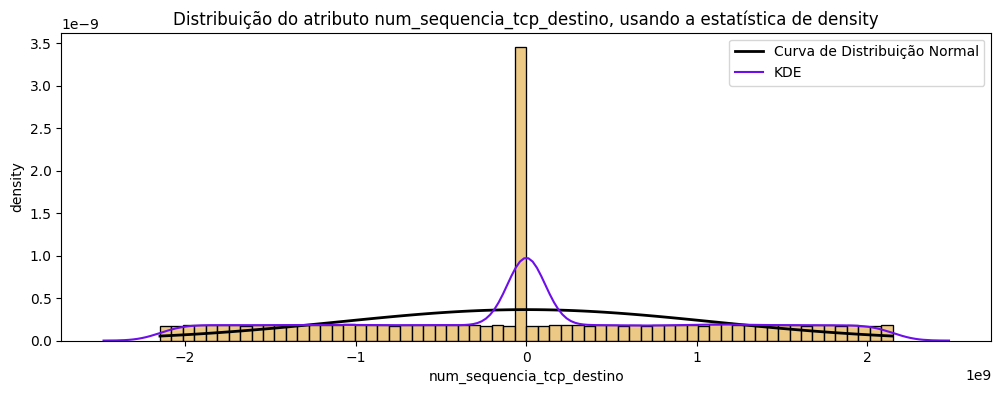

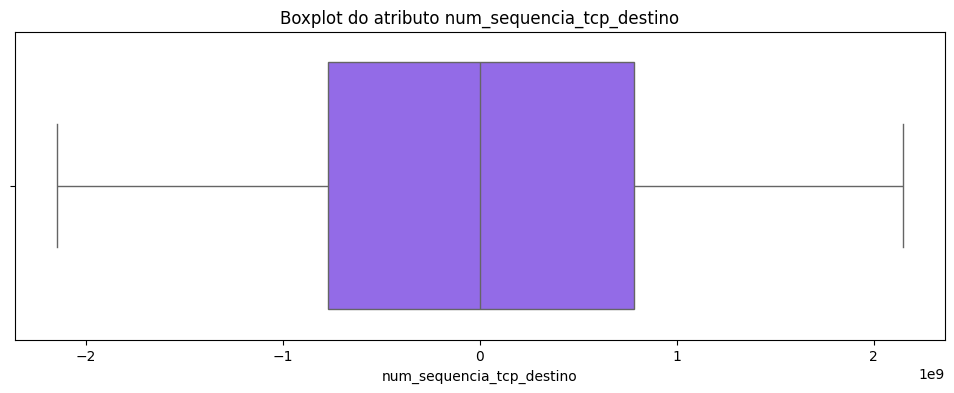






 Análise Básica do atributo num_sequencia_tcp_destino:

 - No total, há 96822 células e destas, 0 são nulas, 21733 estão repetidas e o total de valores unicos são 75089;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 488979.04;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de -2147452874.00 até 2147472407.00

 - Desvio Padrão: 1094723759.63

 - Coeficiente de Variação: 2238.79 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é -773600715.50. Isto significa que 25% dos dados da amostra do atributo num_sequencia_tcp_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo num_sequencia_tcp_destino são menores ou iguais a esse valor. Equiv

In [29]:
# Lista com o atributo desejado
coluna_alvo = ['num_sequencia_tcp_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo é muito parecido com o de origem, apresentando uma distribuição `não normal`. O histograma e o KDE mantêm o pico central agudo no 0, com os "ombros" largos se estendendo pelos valores positivos e negativos. A Curva Normal continua achatada, sendo incapaz de representar a concentração real dos dados, também não acompanhando o bin do 0.

O Boxplot também `não apresenta outliers`, mantendo a simetria visual com a mediana no 0. No entanto, nota-se uma diferença sutil na média aritmética, que aqui é positiva (488.979,04), enquanto na origem era negativa. Isso indica um leve deslocamento no balanço dos números de sequência recebidos em relação aos enviados.

A moda permanece em 0.00, confirmando que o maior volume de pacotes recebidos ainda não iniciou a contagem sequencial ou está em fase de estabelecimento de conexão. 

#### 2.21.  Atributo tamanho_janela_tcp_destino
---

Este atributo **possui** outliers.

##### 2.21.1. Análise com outliers
---

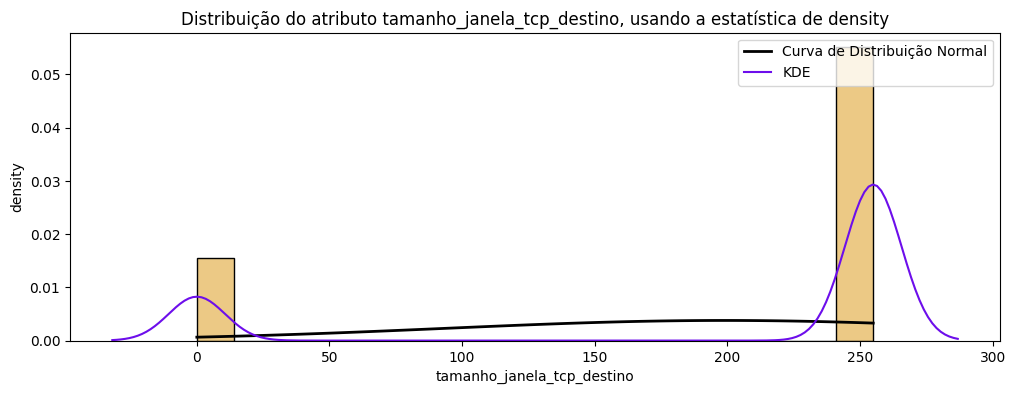

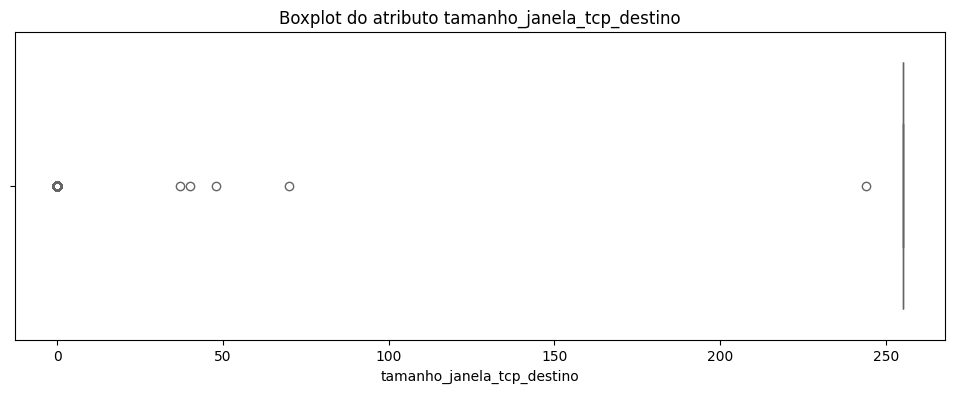






 Análise Básica do atributo tamanho_janela_tcp_destino:

 - No total, há 96822 células e destas, 0 são nulas, 96815 estão repetidas e o total de valores unicos são 7.


 Medidas de Tendência Central do atributo tamanho_janela_tcp_destino: 

 - A média aritmética de seus valores é, aproximadamente, 199.01;

 - A mediana é, aproximadamente, 255.00;

 - A moda é, aproximadamente, 255.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 255.00. Variam em uma faixa de 255.00

 - Desvio Padrão: 105.55

 - Coeficiente de Variação: 0.53 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 93.46 a 304.57 (em caso de normalidade).


 Medidas de Posição (Quartis) do atributo tamanho_janela_tcp_destino:

 - O valor do quartil de 25% é 255.00. Isto significa que 25% dos dados da amostra do atributo tamanho_janela_tcp_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 255.00. Isto significa que 50% dos dados da amostra do atributo

In [45]:
# Lista com o atributo desejado
coluna_alvo = ['tamanho_janela_tcp_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo é muito semelhante ao de origem, possuindo altas concentrações em dois valores principais (0 e 255). Nele, a curva normal também se assemelha um pouco mais com um sino, mas as regras de ouro, a partir de 95% (com intervalo de -12.09 a 410.12), trazem valores negativos impertinentes, confirmando a distribuição não normal dos dados.

O boxplot mantém o padrão diferenciado, apresentando apenas outliers inferiores. Estes representam 21.96% da amostra, um percentual ligeiramente superior ao da origem (21.72%). Como o limite superior, a mediana e todos os quartis estão fixados em 255.00, o gráfico aparece achatado no topo da escala, à direita.

A moda e a mediana terem o mesmo valor, indica que o destino, na maioria das vezes, opera com a janela de recepção em sua capacidade máxima configurada. Os outliers inferiores serão mantidos, pois valores menores ou zerados de janela são fundamentais para identificar o controle de fluxo da rede e possíveis estados de saturação ou ataques que tentam interromper a comunicação entre as pontas.

##### 2.21.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

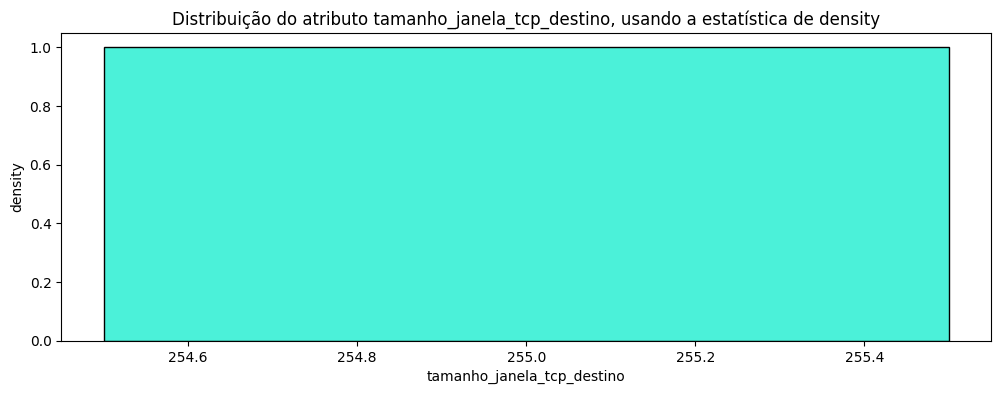

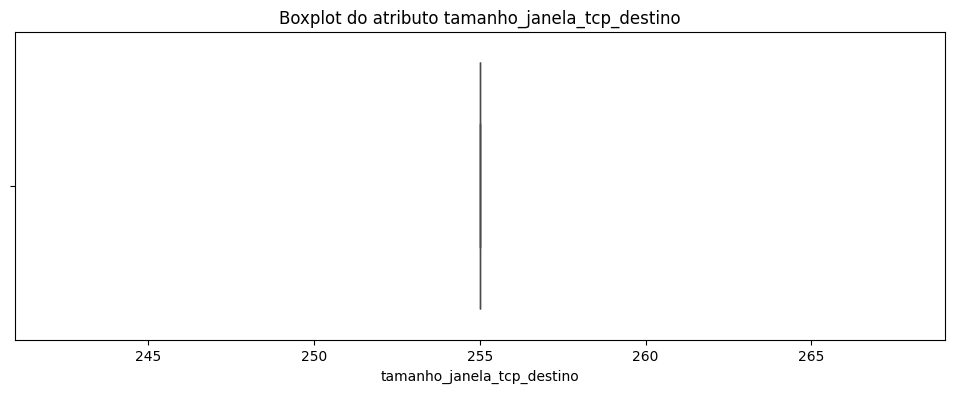




A coluna tamanho_janela_tcp_destino não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo tamanho_janela_tcp_destino:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo tamanho_janela_tcp_destino: 

 - A média aritmética de seus valores é, aproximadamente, 255.00;

 - A mediana é, aproximadamente, 255.00;

 - A moda é, aproximadamente, 255.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 255.00 até 255.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 255.00 a 255.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo tamanho_janela_tcp_destino:

 - 68% da amostra está compreendida entre, aproximadamente, 255.00 e 255.00;

 - 95% da amostra está compreendida entre, aproximadamente, 255.00 e 255.00

In [46]:
coluna_alvo = ['tamanho_janela_tcp_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 até 255.00 e agora é de 255.00 até 255.00.

#### 2.22.  Atributo rtt_handshake_tcp
---

Este atributo **possui** outliers.

##### 2.22.1. Análise com outliers
---

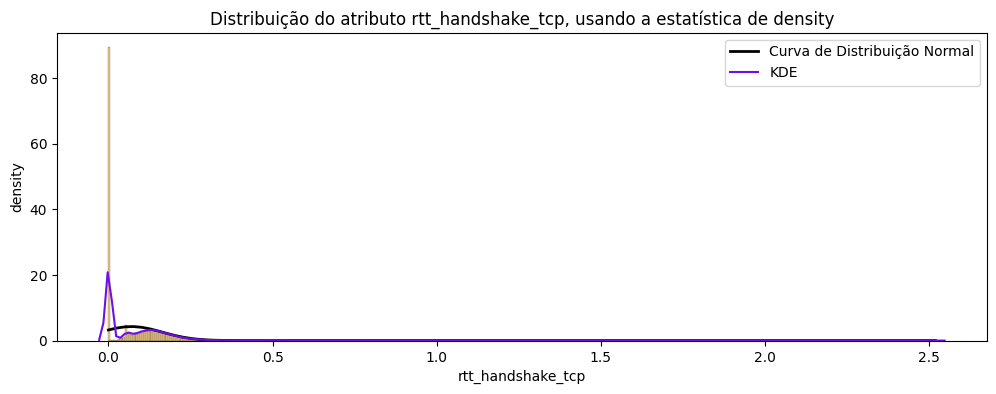

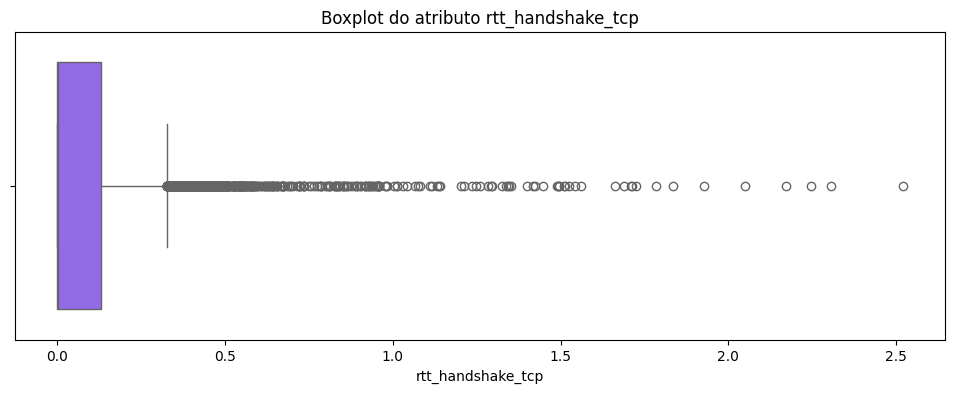






 Análise Básica do atributo rtt_handshake_tcp:

 - No total, há 96822 células e destas, 0 são nulas, 53503 estão repetidas e o total de valores unicos são 43319;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 0.07;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 2.52

 - Desvio Padrão: 0.09

 - Coeficiente de Variação: 1.33 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo rtt_handshake_tcp são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo rtt_handshake_tcp são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil de 75% é 0.13. Isto significa q

In [31]:
# Lista com o atributo desejado
coluna_alvo = ['rtt_handshake_tcp']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo apresenta um comportamento de distribuição não normal, com uma forte concentração de valores próximos a zero e uma cauda longa de outliers. O histograma e o KDE mostram um pico extremamente agudo na moda (0.00), enquanto a Curva Normal aparece achatada e deslocada, não representando a realidade dos dados. As regras de ouro confirmam essa inconsistência ao apresentarem valores negativos (de -0.02 a -0.21) a partir de 68% da amostra.

O boxplot evidencia uma outliers superiores (0.79% do total de registros), que se estendem até o valor máximo de 2.52. A mediana (quartil de 50%) e o quartil de 25% estão ambos em 0.00, indicando que a grande maioria das conexões ocorre de forma quase instantânea ou não registrou tempo de resposta mensurável nesta métrica.

Os outliers serão mantidos, pois o tempo de resposta do handshake TCP (RTT) é um dado real e crítico. Valores elevados indicam latência na negociação da conexão, o que pode ser causado por congestionamento de rede, longa distância física entre os pontos ou tentativas de ataques que sobrecarregam o processo de autenticação.

##### 2.22.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

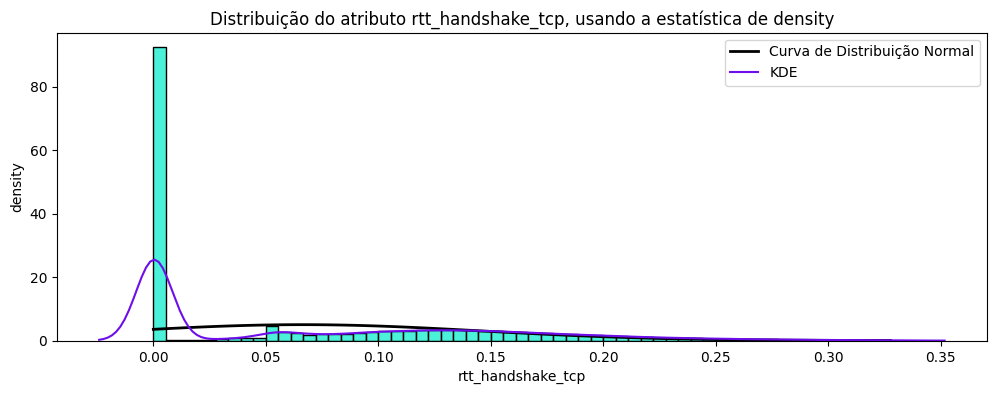

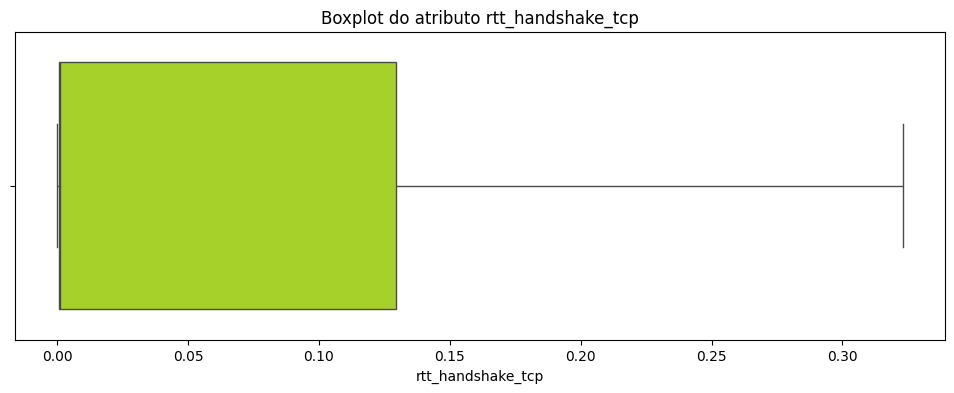






 Análise Básica do atributo rtt_handshake_tcp:

 - No total, há 96053 células e destas, 0 são nulas, 53497 estão repetidas e o total de valores unicos são 42556.


 Medidas de Tendência Central do atributo rtt_handshake_tcp: 

 - A média aritmética de seus valores é, aproximadamente, 0.07;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.33. Variam em uma faixa de 0.33

 - Desvio Padrão: 0.08

 - Coeficiente de Variação: 1.20 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo rtt_handshake_tcp:

 - 68% da amostra está compreendida entre, aproximadamente, -0.01 e 0.15;

 - 95% da amostra está compreendida entre, aproximadamente, -0.09 e 0.23;

 - 99.7% da amostra está compreendida entre, aproximadamente, -0.17 e 0.31.


In [48]:
coluna_alvo = ['rtt_handshake_tcp']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 2.52 e agora é de  0.00 até 0.33.

#### 2.23. Atributo tempo_syn_synack
---

ESte atributo **possui** outliers.

##### 2.23.1. Análise com outliers
---

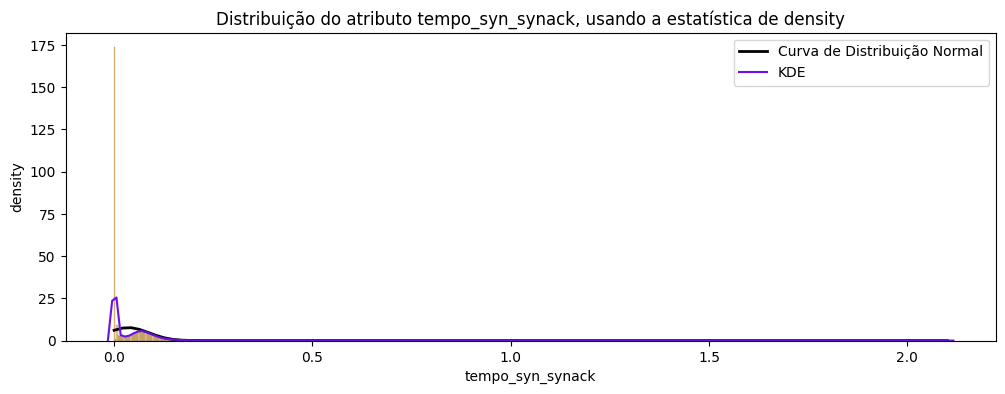

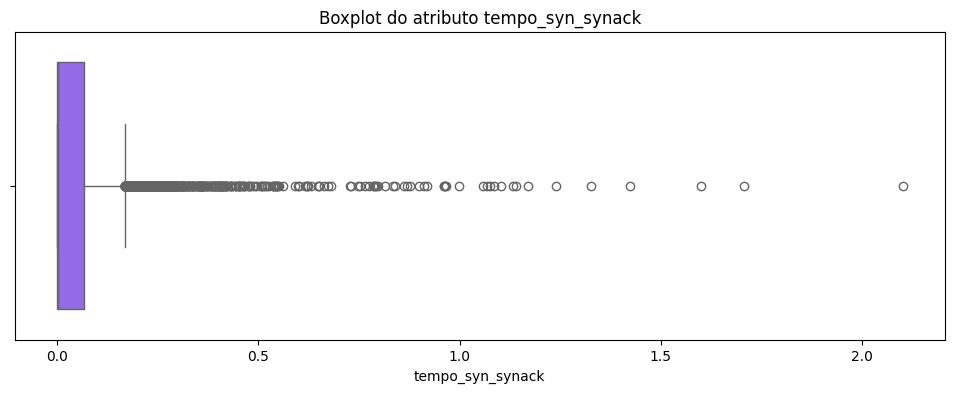






 Análise Básica do atributo tempo_syn_synack:

 - No total, há 96822 células e destas, 0 são nulas, 56680 estão repetidas e o total de valores unicos são 40142.


 Medidas de Tendência Central do atributo tempo_syn_synack: 

 - A média aritmética de seus valores é, aproximadamente, 0.04;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 2.10. Variam em uma faixa de 2.10

 - Desvio Padrão: 0.05

 - Coeficiente de Variação: 1.46 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo tempo_syn_synack:

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo tempo_syn_synack são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo tempo_syn_synack são menores ou iguais a es

In [51]:
# Lista com o atributo desejado
coluna_alvo = ['tempo_syn_synack']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True, limite_x=False)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo apresenta um comportamento de `distribuição não normal`, com uma grande concentração de registros no valor zero. O histograma e o KDE indicam um pico agudo na moda (0.00), enquanto a Curva Normal aparece totalmente achatada e deslocada para a direita, falhando em representar a densidade real dos dados. As regras de ouro confirmam essa discrepância, trazendo valores negativos impertinentes (de -0.06 a -0.31) para as faixas de 68% a 99.7% da amostra.

O boxplot revela uma distribuição assimétrica, onde a mediana e os quartis de 25% e 50% estão fixados em 0.00. O limite superior estatístico é de apenas 0.11. No total, 5.74% dos registros são considerados outliers superiores

Os outliers serão mantidos, pois representam amostras reais de Round Trip Time (RTT) que sofreram variações significativas. Em um contexto de análise de tráfego, esses picos de tempo são fundamentais para identificar gargalos de retransmissão ou instabilidades momentâneas que não são captadas pela média aritmética, que aqui é de apenas 0.04.

##### 2.23.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

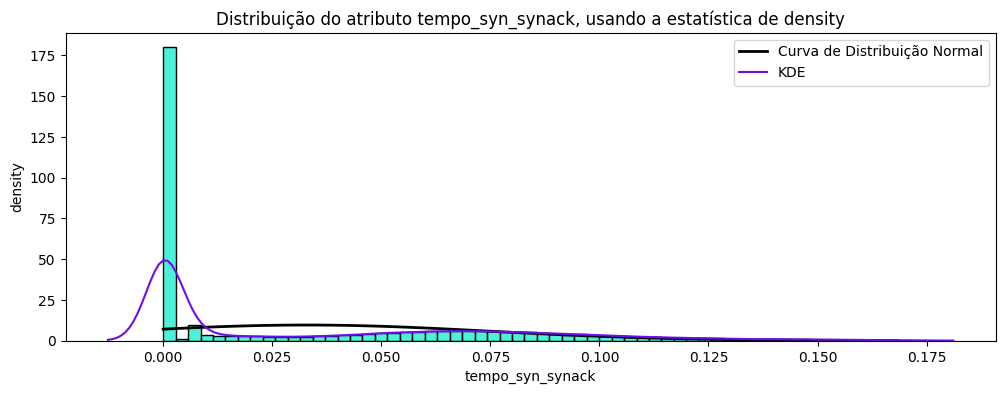

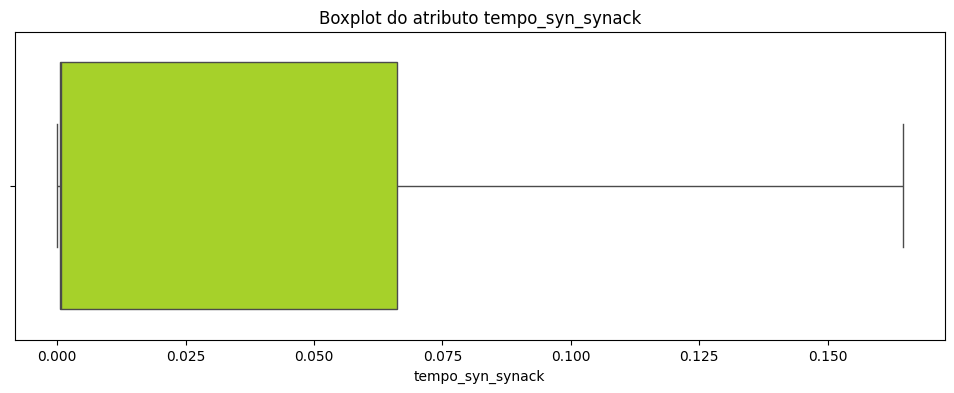






 Análise Básica do atributo tempo_syn_synack:

 - No total, há 95692 células e destas, 0 são nulas, 56664 estão repetidas e o total de valores unicos são 39028.


 Medidas de Tendência Central do atributo tempo_syn_synack: 

 - A média aritmética de seus valores é, aproximadamente, 0.03;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.17. Variam em uma faixa de 0.17

 - Desvio Padrão: 0.04

 - Coeficiente de Variação: 1.27 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo tempo_syn_synack:

 - 68% da amostra está compreendida entre, aproximadamente, -0.01 e 0.07;

 - 95% da amostra está compreendida entre, aproximadamente, -0.05 e 0.12;

 - 99.7% da amostra está compreendida entre, aproximadamente, -0.09 e 0.16.


In [55]:
coluna_alvo = ['tempo_syn_synack']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 2.10 e agora é de 0.00 até 0.17.

#### 2.24. Atributo tempo_synack_ack
---

Este atributo **possui** outliers.

##### 2.24.1. Análise com outliers
---

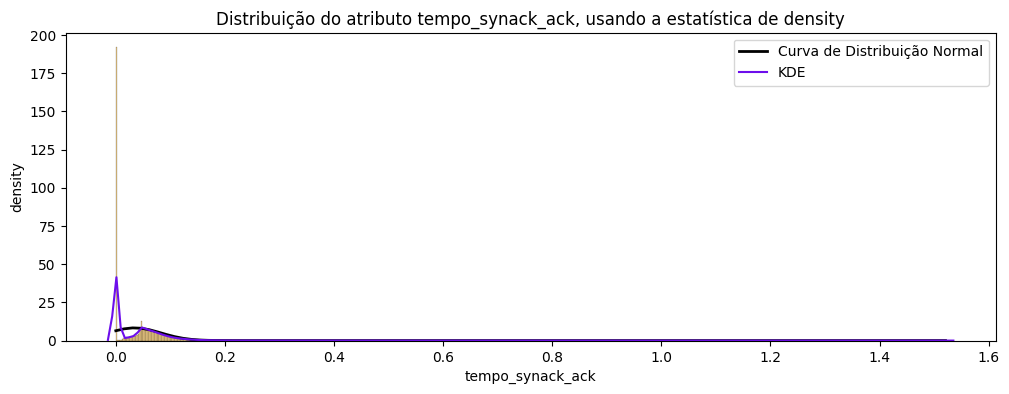

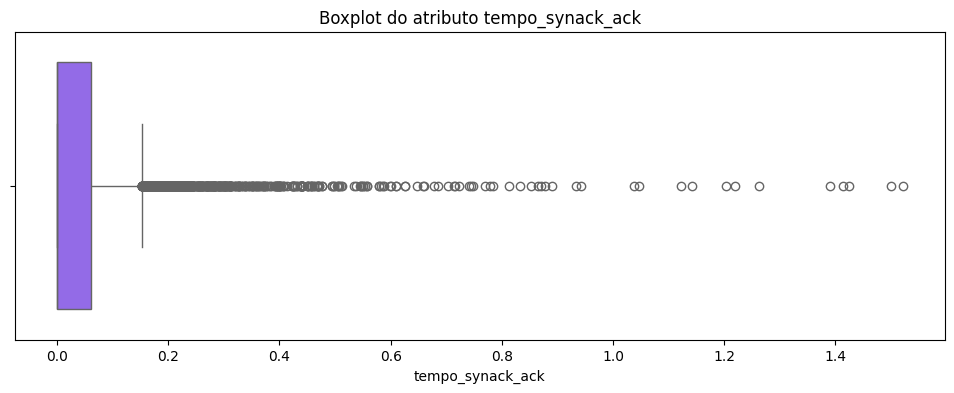






 Análise Básica do atributo tempo_synack_ack:

 - No total, há 96822 células e destas, 0 são nulas, 59114 estão repetidas e o total de valores unicos são 37708.


 Medidas de Tendência Central do atributo tempo_synack_ack: 

 - A média aritmética de seus valores é, aproximadamente, 0.03;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 1.52. Variam em uma faixa de 1.52

 - Desvio Padrão: 0.05

 - Coeficiente de Variação: 1.39 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo tempo_synack_ack:

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo tempo_synack_ack são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo tempo_synack_ack são menores ou iguais a es

In [56]:
# Lista com o atributo desejado
coluna_alvo = ['tempo_synack_ack']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo é muito semelhante ao tempo_syn_synack: apresenta um comportamento de distribuição não normal, com uma concentração massiva de registros em valores próximos a zero. O histograma e o KDE exibem um pico extremamente agudo na moda e mediana, ambas em 0.00, enquanto a Curva Normal aparece totalmente achatada e deslocada para a direita, falhando em representar a densidade real dos dados. As regras de ouro confirmam essa discrepância ao trazerem valores negativos impertinentes (de -0.01 a -0.11) para as faixas.

O boxplot revela uma distribuição assimétrica, onde a mediana e o quartil de 25% estão fixados em 0.00. O limite superior estatístico é baixo (0.15), e 1.35% dos registros (1304 células) são classificados como outliers superiores, estendendo-se até o valor máximo de 1.52. O Coeficiente de Variação de 1.39 reforça a alta dispersão, confirmada pelo desvio padrão (0.05) sendo superior à média (0.03).

Os outliers serão mantidos, pois representam o tempo real decorrido na finalização do handshake TCP. Valores elevados nesta métrica são indicadores fundamentais de latência de rede ou de possíveis anomalias no estabelecimento de conexões, onde o atraso no envio do ACK final pode sinalizar desde gargalos de infraestrutura até tentativas de ataques de negação de serviço.

##### 2.24.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

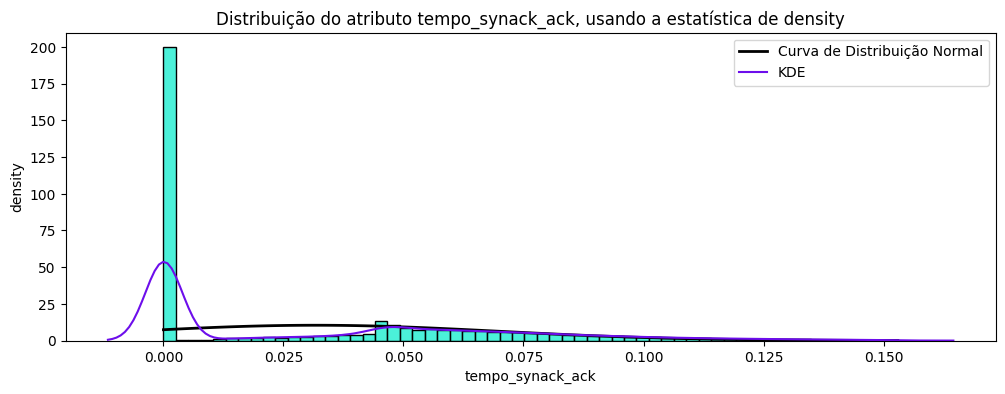

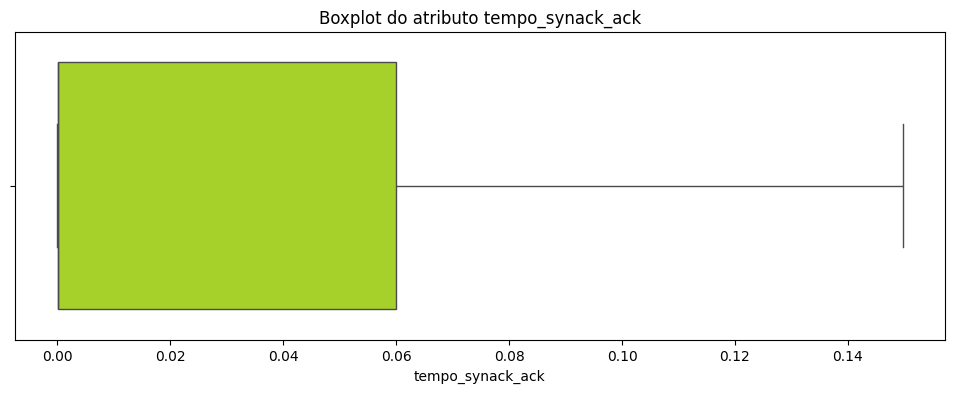






 Análise Básica do atributo tempo_synack_ack:

 - No total, há 95518 células e destas, 0 são nulas, 59092 estão repetidas e o total de valores unicos são 36426.


 Medidas de Tendência Central do atributo tempo_synack_ack: 

 - A média aritmética de seus valores é, aproximadamente, 0.03;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.15. Variam em uma faixa de 0.15

 - Desvio Padrão: 0.04

 - Coeficiente de Variação: 1.20 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Regra de Ouro da Distribuição Normal do atributo tempo_synack_ack:

 - 68% da amostra está compreendida entre, aproximadamente, -0.01 e 0.07;

 - 95% da amostra está compreendida entre, aproximadamente, -0.04 e 0.11;

 - 99.7% da amostra está compreendida entre, aproximadamente, -0.08 e 0.15.


In [59]:
coluna_alvo = ['tempo_synack_ack']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 1.52 e agora é de 0.00 até 0.15.

#### 2.25. Atributo tamanho_medio_pacotes_origem
---

Este atributo **possui** outliers.

##### 2.25.1. Análise com outliers
---

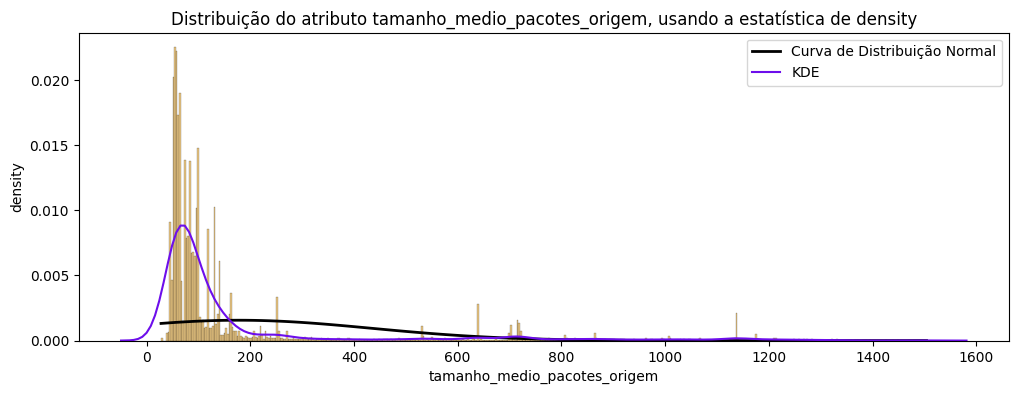

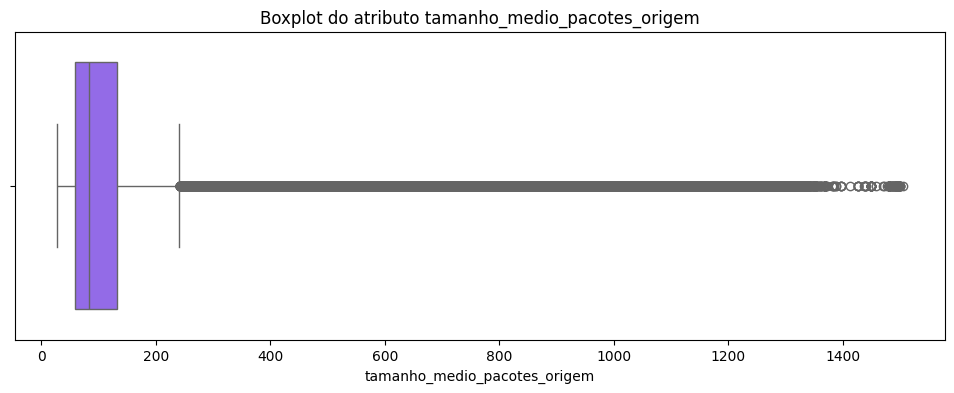




A coluna tamanho_medio_pacotes_origem não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo tamanho_medio_pacotes_origem:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo tamanho_medio_pacotes_origem: 

 - A média aritmética de seus valores é, aproximadamente, 177.63;

 - A mediana é, aproximadamente, 83.00;

 - A moda é, aproximadamente, 56.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 28.00 até 1504.00. Variam em uma faixa de 1476.00

 - Desvio Padrão: 255.29

 - Coeficiente de Variação: 1.44 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo tamanho_medio_pacotes_origem:

 - O valor do quartil de 25% é 59.00. Isto significa que 25% dos dados da amostra do atributo tamanho_medio_pacotes_origem são menores ou iguai

In [60]:
# Lista com o atributo desejado
coluna_alvo = ['tamanho_medio_pacotes_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo apresenta um comportamento de `distribuição não normal`, caracterizado por uma forte assimetria positiva, já que os valores estão distribuídos de forma desequilibrada, em direção aos valores mais altos. O histograma e o KDE exibem um pico agudo na moda (56.00), mas também em valores próximos, enquanto a Curva Normal aparece muito achatada e deslocada para a direita devido à influência dos valores altos. As regras de ouro confirmam essa inconsistência ao apresentarem valores negativos (de -77.67 a -588.25) que não são pertinentes, já que o tamanho de um pacote não pode ser inferior a zero.

O boxplot revela uma das concentrações de valores atípicos mais notáveis do dataset, com o total de outliers superiores correspondendo a 14.87% dos registros (14.400 células). O limite superior estatístico é de 241.50, mas a amplitude se estende até o valor máximo de 1504.00. O Coeficiente de Variação de 1.44 e o desvio padrão (255.29) superior à média (177.63) reforçam a alta dispersão e a presença de forte assimetria nos dados.

Os outliers serão mantidos, pois o tamanho médio dos pacotes é uma métrica real que varia conforme o protocolo e a aplicação utilizada. Valores baixos (próximos à moda de 56) são típicos de mensagens de controle ou pacotes TCP sem carga útil, enquanto os outliers superiores refletem transferências de dados volumosas ou pacotes que atingiram o MTU (Maximum Transmission Unit) da rede, sendo essenciais para distinguir tráfego legítimo de possíveis anomalias.

##### 2.25.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

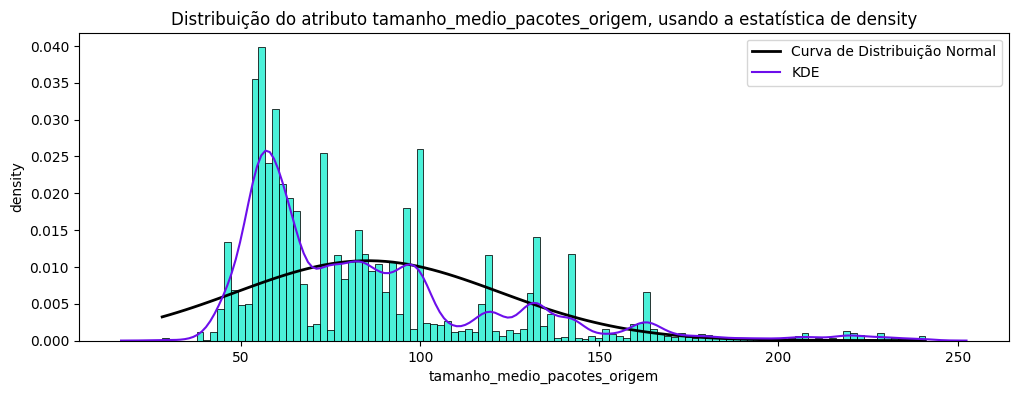

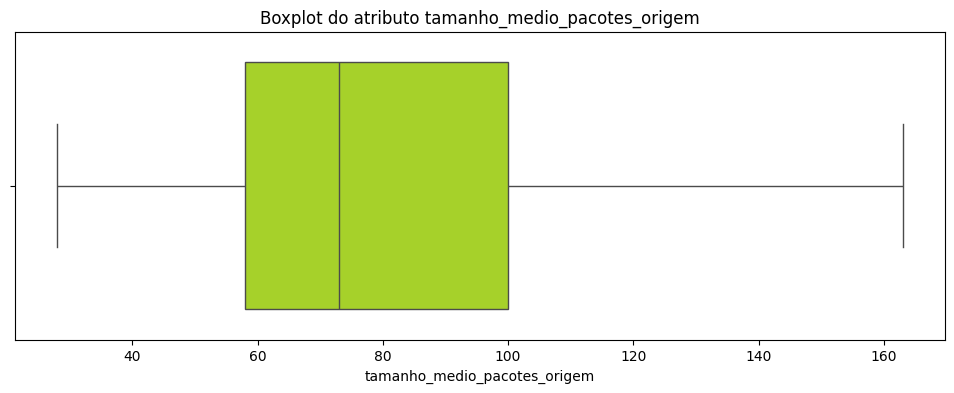




A coluna tamanho_medio_pacotes_origem não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo tamanho_medio_pacotes_origem:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo tamanho_medio_pacotes_origem: 

 - A média aritmética de seus valores é, aproximadamente, 85.39;

 - A mediana é, aproximadamente, 73.00;

 - A moda é, aproximadamente, 56.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 28.00 até 241.00. Variam em uma faixa de 213.00

 - Desvio Padrão: 36.80

 - Coeficiente de Variação: 0.43 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 48.59 a 122.19 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo tamanho_medio_pacotes_origem:

 - 68% da amostra está compreendida entre, aproximadamente, 48.59 e 122.19;

 - 95% da amostra está compreendida entre, aproximadamente, 11.79 e 15

In [61]:
coluna_alvo = ['tamanho_medio_pacotes_origem']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 28.00 até 1504.00 e agora é de 28.00 até 241.00.

#### 2.26. Atributo tamanho_medio_pacotes_destino
---

Este atributo **possui** outliers.

##### 2.26.1 Análise com outliers
---

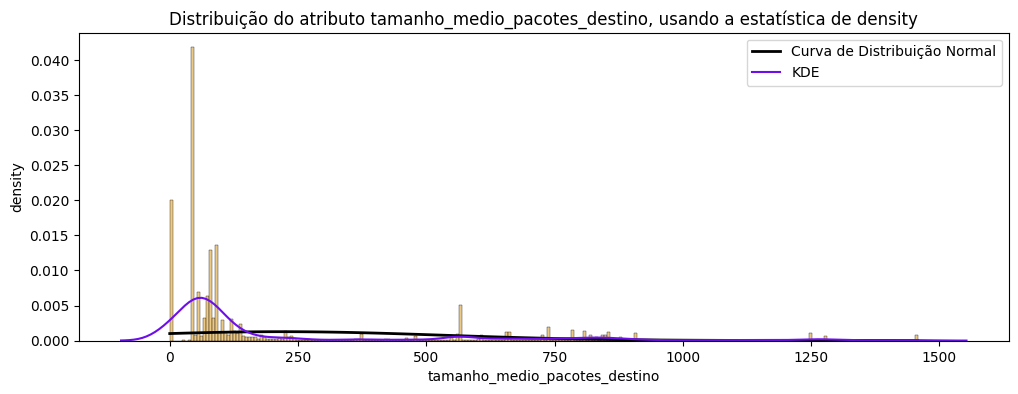

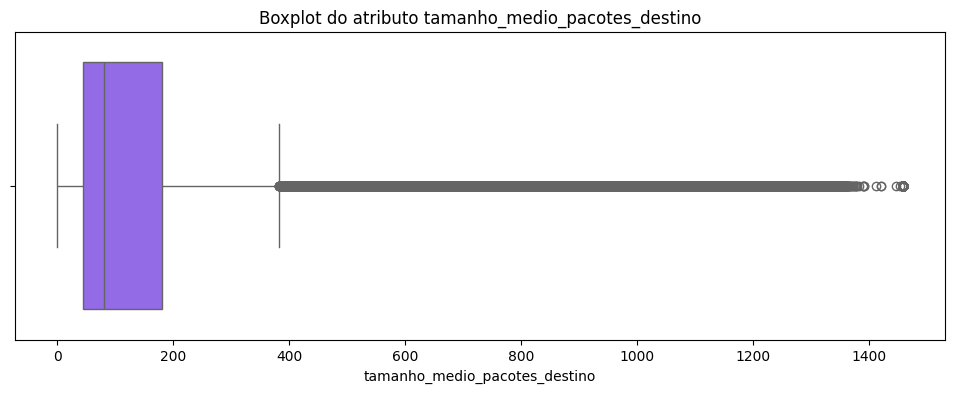






 Análise Básica do atributo tamanho_medio_pacotes_destino:

 - No total, há 96822 células e destas, 0 são nulas, 95494 estão repetidas e o total de valores unicos são 1328.


 Medidas de Tendência Central do atributo tamanho_medio_pacotes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 217.15;

 - A mediana é, aproximadamente, 80.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 1458.00. Variam em uma faixa de 1458.00

 - Desvio Padrão: 314.23

 - Coeficiente de Variação: 1.45 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo tamanho_medio_pacotes_destino:

 - O valor do quartil de 25% é 45.00. Isto significa que 25% dos dados da amostra do atributo tamanho_medio_pacotes_destino são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 80.00. Isto significa que 50% dos dados da

In [62]:
# Lista com o atributo desejado
coluna_alvo = ['tamanho_medio_pacotes_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo apresenta um comportamento de forte assimetria positiva, ainda mais acentuada do que no fluxo de origem. O `histograma` e o `KDE` mostram um pico isolado na moda (0.00), mas também, e em outros ao redor. A `Curva Normal` aparece extremamente achatada e deslocada para a direita devido ao peso dos valores elevados. As regras de ouro confirmam a distribuição não normal, apresentando intervalos negativos (de -97.08 a -725.54) que são logicamente impossíveis para o tamanho de pacotes. Portanto, a `distribuição não é normal`.

O `boxplot` revela a maior concentração de anomalias estatísticas vista até agora, com o total de outliers superiores atingindo 19.88% dos registros (19.247 células). O limite superior estatístico é de 382.50, mas a amplitude se estende até 1458.00. O `Coeficiente de Variação` de 1.45 e o `desvio padrão` (314.23) significativamente superior à média (217.15) reforçam a dispersão extrema dos dados.

Os `outliers serão mantidos`, pois representam o comportamento real de recepção de dados. A moda em 0.00 indica uma quantidade massiva de pacotes de controle vindos do destino (como confirmações de recebimento sem carga útil), enquanto os quase 20% de outliers superiores representam o tráfego de resposta efetivo (downloads ou respostas de serviços). Em análise de segurança, essa distinção é vital para identificar fluxos de comunicação assimétricos que podem indicar exfiltração ou ataques de negação de serviço.

###### 2.26.2. Análise sem outliers
---

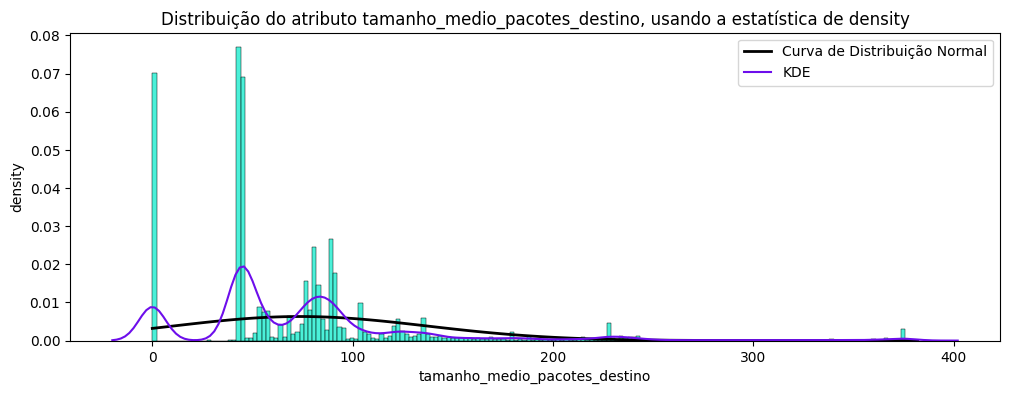

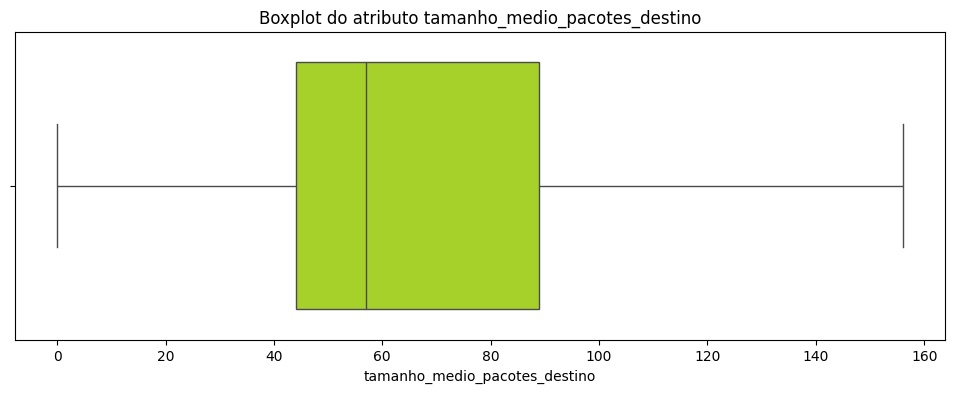






 Análise Básica do atributo tamanho_medio_pacotes_destino:

 - No total, há 77575 células e destas, 0 são nulas, 77231 estão repetidas e o total de valores unicos são 344.


 Medidas de Tendência Central do atributo tamanho_medio_pacotes_destino: 

 - A média aritmética de seus valores é, aproximadamente, 73.81;

 - A mediana é, aproximadamente, 57.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 382.00. Variam em uma faixa de 382.00

 - Desvio Padrão: 63.24

 - Coeficiente de Variação: 0.86 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 10.57 a 137.04 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo tamanho_medio_pacotes_destino:

 - 68% da amostra está compreendida entre, aproximadamente, 10.57 e 137.04;

 - 95% da amostra está compreendida entre, aproximadamente, -52.67 e 200.28;

 - 99.7% da amostra está compreendida entre, aproximadamente, -115.90 e 263.52.


In [63]:
coluna_alvo = ['tamanho_medio_pacotes_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=True, curva_normal=True, kde=True, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** tanto pela curva achatada, parecendo uma reta, quanto pelos valores negativos impossíveis das regras de ouro. A amplitude antes era de 0.00 até 1458.00 e agora é de 0.00 até 382.00.

#### 2.27. Atributo profundidade_transacao_http
---

Este atributo **possui** outliers.

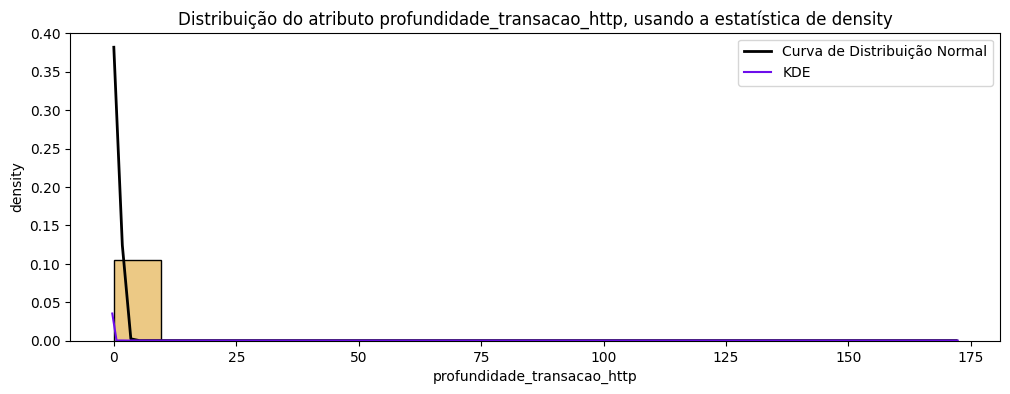

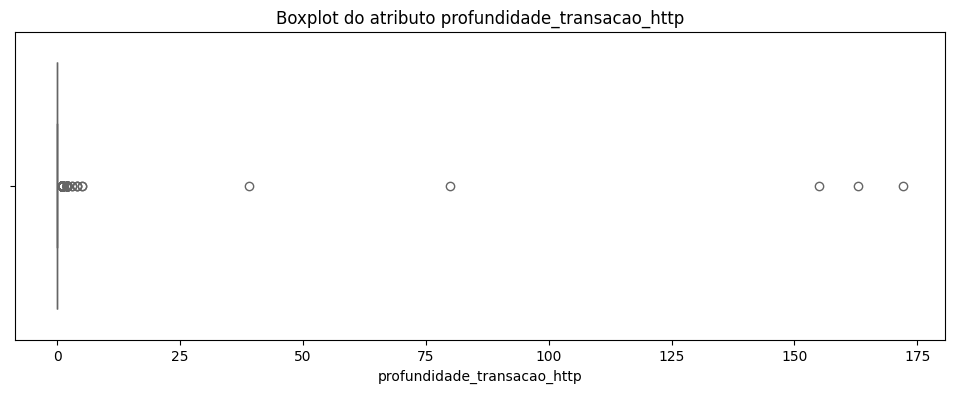






 Análise Básica do atributo profundidade_transacao_http:

 - No total, há 96822 células e destas, 0 são nulas, 96811 estão repetidas e o total de valores unicos são 11.


 Medidas de Tendência Central do atributo profundidade_transacao_http: 

 - A média aritmética de seus valores é, aproximadamente, 0.18;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 172.00. Variam em uma faixa de 172.00

 - Desvio Padrão: 1.03

 - Coeficiente de Variação: 5.56 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo profundidade_transacao_http:

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo profundidade_transacao_http são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atribut

In [64]:
# Lista com o atributo desejado
coluna_alvo = ['profundidade_transacao_http']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O `histograma` e o `KDE` mostram um pico absoluto no valor 0.00, enquanto a `Curva Normal` aparece como uma linha praticamente reta na base do gráfico. As regras de ouro confirmam a `distribuição não normal`, gerando intervalos negativos (entre -0.84 e -2.90), irreais para o contexto.

No `boxplot`, como os quartis de 25%, 50% (mediana) e 75% são todos iguais a 0.00, o "corpo" do boxplot desaparece, restando a linha vertical e a linha de outliers. O limite superior estatístico é calculado como 0.00, o que faz com que qualquer valor acima de zero seja considerado um outlier. No total, 17.77% dos registros (17.203 células) são tratados como outliers superiores, embora a amplitude máxima chegue a 172.00. O `Coeficiente de Variação` de 5.56 é muito alto, indicando uma dispersão alta em relação à média.

Os `outliers serão mantidos`, pois a profundidade de transação HTTP (geralmente ligada ao pipelining) é um indicador técnico valioso. A moda em 0.00 revela que a imensa maioria do tráfego não utiliza transações HTTP encadeadas ou nem sequer é tráfego HTTP. Entretanto, os outliers que representam múltiplas transações simultâneas são fundamentais para identificar comportamentos de aplicações específicas ou tentativas de abusar do protocolo para sobrecarregar servidores ou evadir sistemas de detecção.

##### 2.27.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

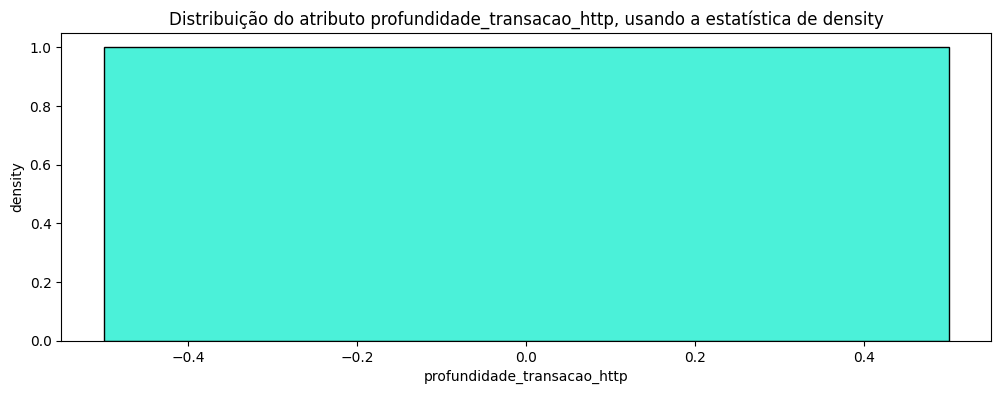

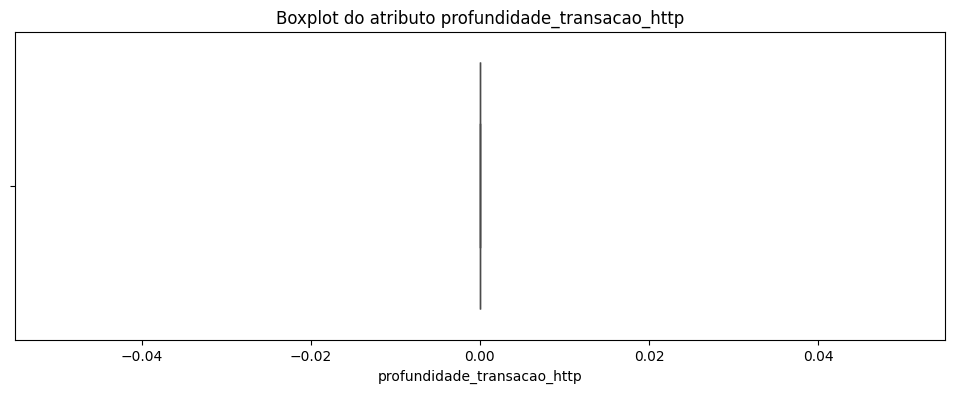






 Análise Básica do atributo profundidade_transacao_http:

 - No total, há 79619 células e destas, 0 são nulas, 79618 estão repetidas e o total de valores unicos são 1.


 Medidas de Tendência Central do atributo profundidade_transacao_http: 

 - A média aritmética de seus valores é, aproximadamente, 0.00;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.00 a 0.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo profundidade_transacao_http:

 - 68% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 95% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 99.7% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00.


In [66]:
coluna_alvo = ['profundidade_transacao_http']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 até 172.00 e agora é de 0.00 até 0.00.

#### 2.28. Atributo tamanho_corpo_resposta_http
---

Este atributo **possui** outliers.

##### 2.28.1. Análise com outliers
---

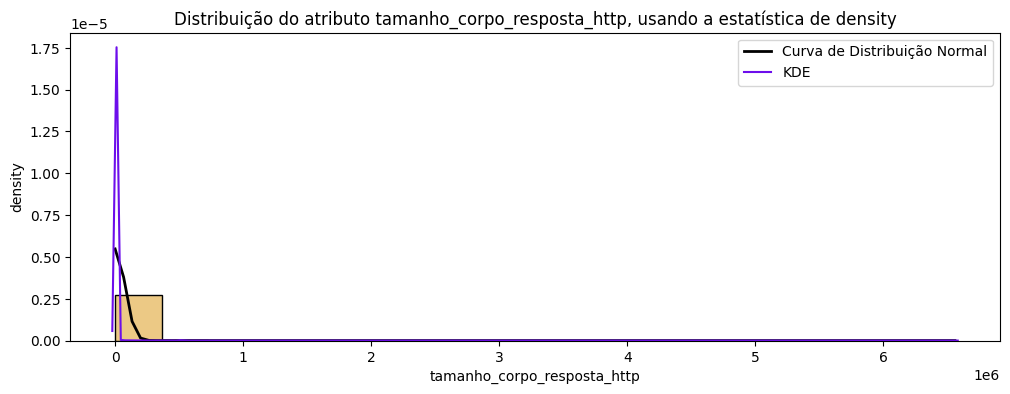

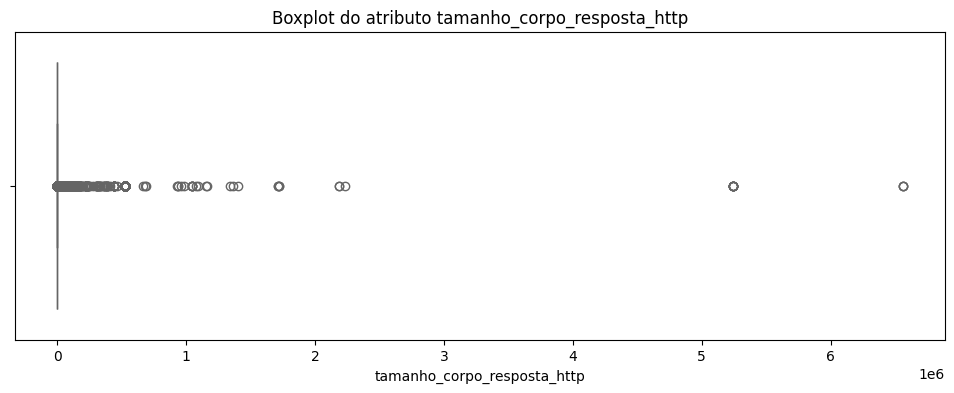






 Análise Básica do atributo tamanho_corpo_resposta_http:

 - No total, há 96822 células e destas, 0 são nulas, 94436 estão repetidas e o total de valores unicos são 2386;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 3824.91;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 6558056.00

 - Desvio Padrão: 72717.63

 - Coeficiente de Variação: 19.01 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo tamanho_corpo_resposta_http são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo tamanho_corpo_resposta_http são menores ou iguais a esse valor. Equivale à mediana;

 - O valor

In [72]:
# Lista com o atributo desejado
coluna_alvo = ['tamanho_corpo_resposta_http']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo apresenta um comportamento assimetria positiva, sendo um caso de `distribuição não normal` do dataset. O `histograma` e o `KDE` mostram um pico absoluto no valor 0.00 (moda), enquanto a `Curva Normal` aparece como uma linha reta na base e mais alta perto da moda, incapaz de lidar com a amplitude dos dados. As regras de ouro falham, gerando intervalos negativos imensos (até -214.327,99) que são fisicamente impossíveis para o tamanho de um corpo de resposta.

O `boxplot` exibe a característica de compressão, como visto em alguns atributos do dataset: como os quartis de 25%, 50% (mediana) e 75% são todos iguais a 0.00, o corpo do gráfico inexiste, restando apenas uma linha vertical e outra densa linha de outliers superiores. Qualquer valor acima de zero é considerado um outlier estatístico, totalizando 11.14% dos registros (10.787 células). A `amplitude` é muito grande, indo de 0.00 até 6.558.056,00 (aprox. 6.5 MB). O `Coeficiente de Variação` de 19.01 é um dos maiores registrados, com um `desvio padrão` (72.717,63) muito maior que a `média aritmética` (3.824,91), comprovando mais uma vez a assimetria e dispersão.

Os `outliers serão mantidos`, pois o tamanho do corpo da resposta HTTP é uma das métricas mais importantes para segurança. A moda em 0.00 indica que a maioria das interações não possui corpo (como erros 404, redirects ou pacotes de controle). No entanto, os outliers podem representar o download de arquivos, imagens e scripts. Manter esses valores de até 6.5 MB é vital para detectar comportamentos de exfiltração de dados ou o tráfego de malwares que utilizam o protocolo HTTP para se propagar pela rede.

##### 2.28.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

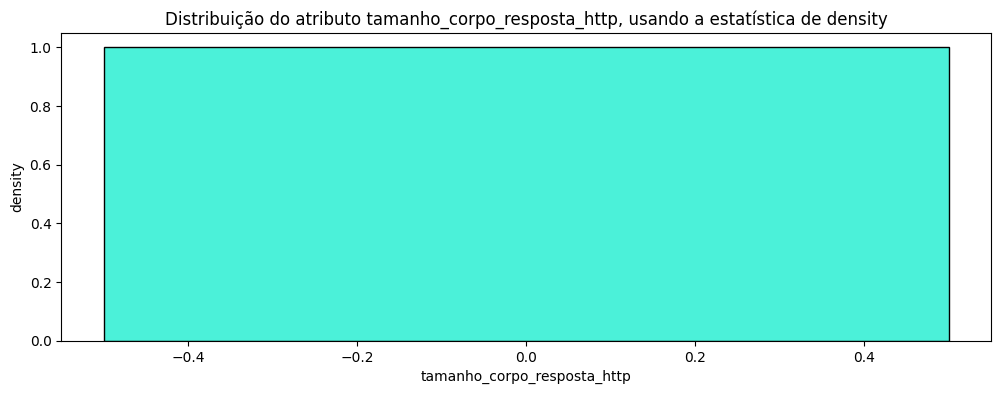

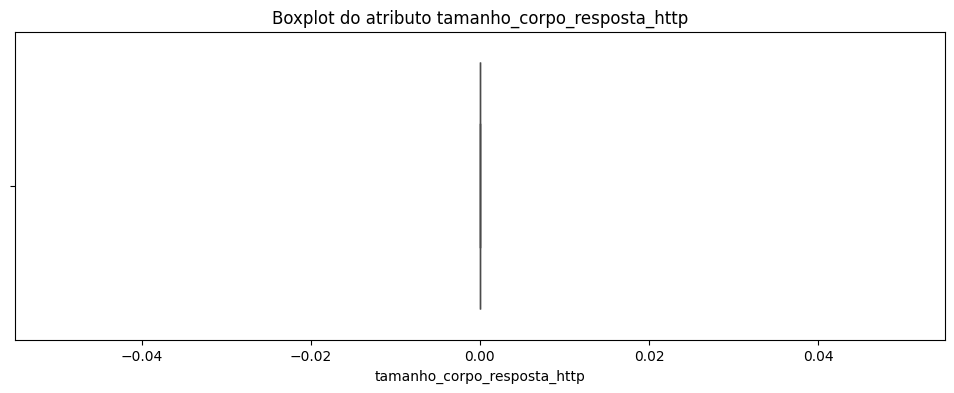






 Análise Básica do atributo tamanho_corpo_resposta_http:

 - No total, há 86035 células e destas, 0 são nulas, 86034 estão repetidas e o total de valores unicos são 1.


 Medidas de Tendência Central do atributo tamanho_corpo_resposta_http: 

 - A média aritmética de seus valores é, aproximadamente, 0.00;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.00 a 0.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo tamanho_corpo_resposta_http:

 - 68% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 95% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 99.7% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00.


In [67]:
coluna_alvo = ['tamanho_corpo_resposta_http']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 até 6558056.00 e agora é de 0.00 até 0.00.

#### 2.29. Atributo conexoes_recentes_ip_porta_destino
---

Este atributo **possui** outliers.

##### 2.29.1. Análise com outliers
---

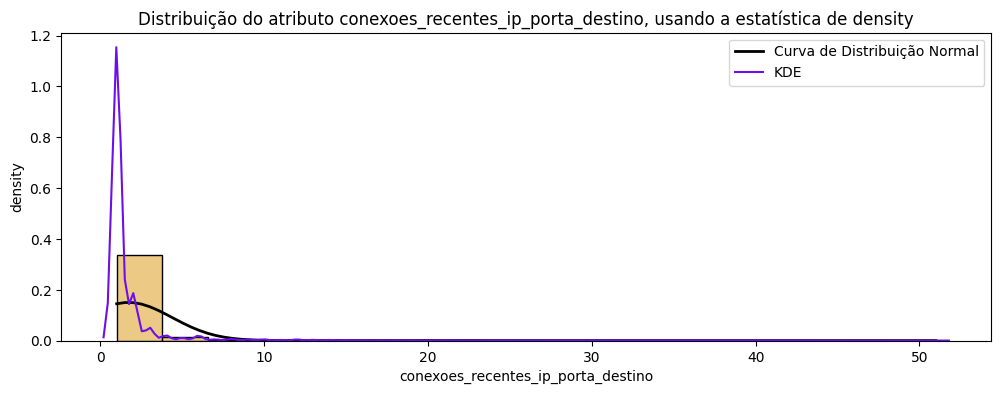

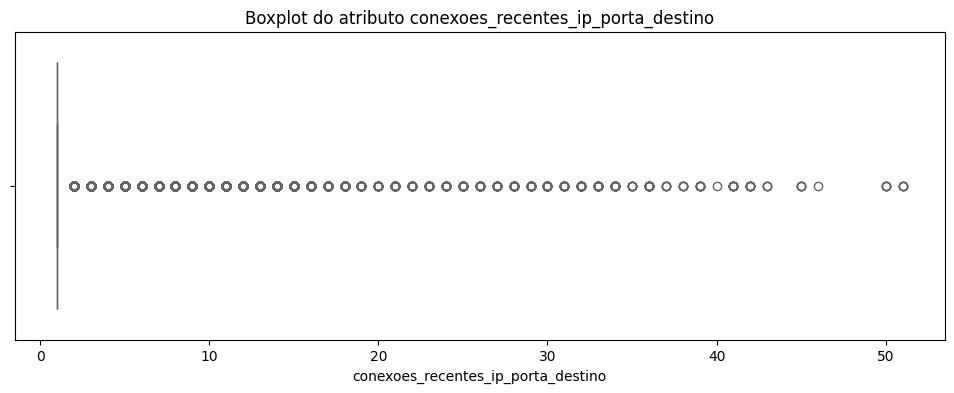




A coluna conexoes_recentes_ip_porta_destino não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo conexoes_recentes_ip_porta_destino:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo conexoes_recentes_ip_porta_destino: 

 - A média aritmética de seus valores é, aproximadamente, 1.72;

 - A mediana é, aproximadamente, 1.00;

 - A moda é, aproximadamente, 1.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 1.00 até 51.00. Variam em uma faixa de 50.00

 - Desvio Padrão: 2.66

 - Coeficiente de Variação: 1.55 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo conexoes_recentes_ip_porta_destino:

 - O valor do quartil de 25% é 1.00. Isto significa que 25% dos dados da amostra do atributo conexoes_recentes_ip_porta_destino sã

In [68]:
# Lista com o atributo desejado
coluna_alvo = ['conexoes_recentes_ip_porta_destino']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo apresenta um comportamento de forte concentração, com uma `distribuição não normal`. O `histograma` e o `KDE` revelam um pico absoluto no valor 1.00, que atua simultaneamente como moda e todos os quartis (25% a 75%). A `Curva Normal` aparece totalmente achatada e deslocada, com uma pequena formação que remete a um sino perto da pico, enquanto as regras de ouro geram intervalos negativos (até -6.25) que não possuem sentido lógico para uma contagem de conexões.

O `boxplot` exibe, mais uma vez, a característica de compressão, já que os quartis possuem o mesmo valor (1.0). Resta apenas a linha de outliers superiores e a linha vertical dos quartis. Como o limite superior estatístico é calculado em 1.00, qualquer valor acima deste é classificado como outlier. No total, 22.34% dos registros (21.633 células) são considerados outliers, estendendo-se por uma amplitude que chega a 51.00. O `Coeficiente de Variação` de 1.55 e o `desvio padrão` (2.66) superior à média (1.72) confirmam a alta dispersão e a assimetria positiva dos dados.

Os `outliers serão mantidos`, pois o número de conexões recentes para um mesmo IP e porta de destino é um indicador crítico de segurança. A predominância do valor 1.00 indica um comportamento de conexão padrão e isolado. Entretanto, os outliers que chegam a 51 conexões simultâneas são fundamentais para identificar atividades suspeitas, como varreduras de portas (port scanning), ataques de força bruta ou comportamentos de propagação de rede que destoam do tráfego convencional.

##### 2.29.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

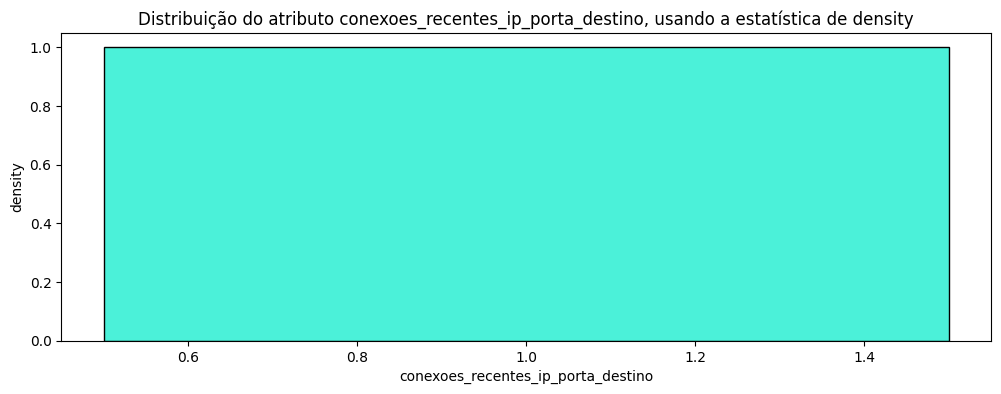

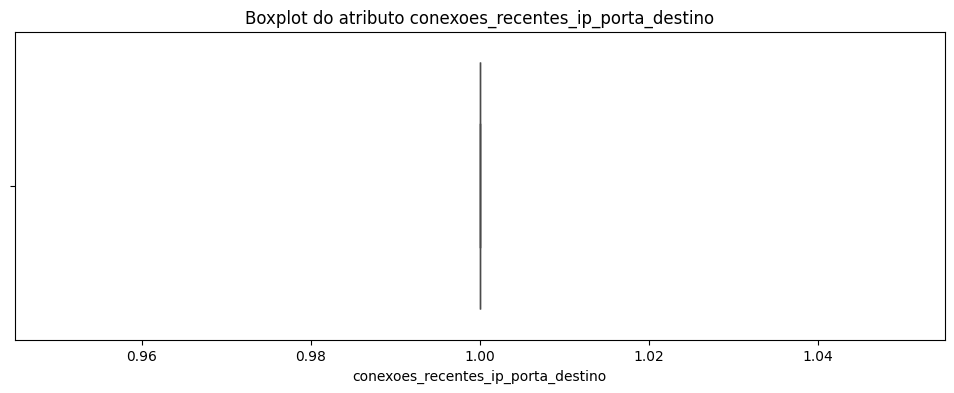




A coluna conexoes_recentes_ip_porta_destino não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo conexoes_recentes_ip_porta_destino:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo conexoes_recentes_ip_porta_destino: 

 - A média aritmética de seus valores é, aproximadamente, 1.00;

 - A mediana é, aproximadamente, 1.00;

 - A moda é, aproximadamente, 1.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 1.00 até 1.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 1.00 a 1.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo conexoes_recentes_ip_porta_destino:

 - 68% da amostra está compreendida entre, aproximadamente, 1.00 e 1.00;

 - 95% da amostra está compreendida entre, aproximadamente, 1

In [69]:
coluna_alvo = ['conexoes_recentes_ip_porta_destino']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 1.00 até 51.00 e agora é de 1.00 até 1.00.

#### 2.30. Atributo conexoes_recentes_ip_porta_origem
---

Este atributo **possui** outliers.

##### 2.30.1. Análise com outliers
---

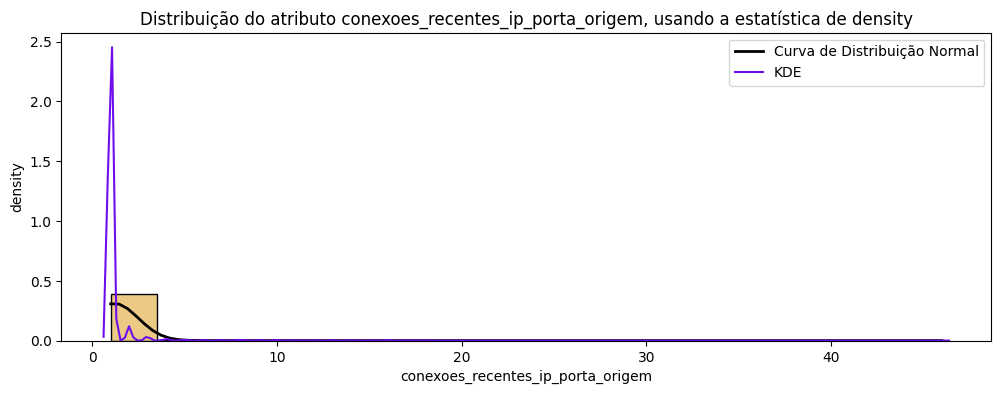

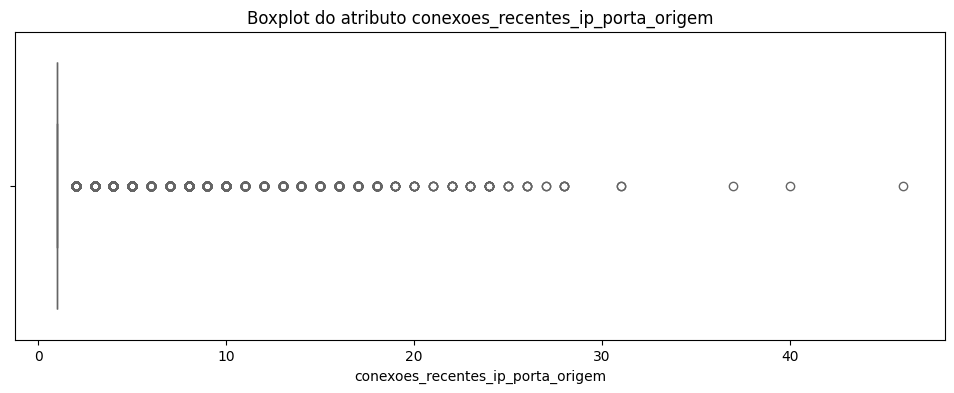




A coluna conexoes_recentes_ip_porta_origem não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo conexoes_recentes_ip_porta_origem:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo conexoes_recentes_ip_porta_origem: 

 - A média aritmética de seus valores é, aproximadamente, 1.21;

 - A mediana é, aproximadamente, 1.00;

 - A moda é, aproximadamente, 1.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 1.00 até 46.00. Variam em uma faixa de 45.00

 - Desvio Padrão: 1.28

 - Coeficiente de Variação: 1.06 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo conexoes_recentes_ip_porta_origem:

 - O valor do quartil de 25% é 1.00. Isto significa que 25% dos dados da amostra do atributo conexoes_recentes_ip_porta_origem são men

In [70]:
# Lista com o atributo desejado
coluna_alvo = ['conexoes_recentes_ip_porta_origem']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo conexoes_recentes_ip_porta_origem apresenta um comportamento de forte assimetria positiva, característico de uma `distribuição não normal`. O `histograma` e o `KDE` revelam um pico absoluto no valor 1.00, que concentra a moda, a mediana e todos os quartis da amostra. A `Curva Normal` aparece achatada e deslocada, enquanto as regras de ouro geram intervalos negativos (até -2.64) que são logicamente impossíveis para uma contagem de conexões.

O `boxplot` exibe o fenômeno de compressão, onde o corpo do gráfico desaparece devido à igualdade entre os quartis de 25%, 50% e 75%. Como o limite superior estatístico é calculado em 1.00, qualquer valor acima deste é classificado como outlier. No total, 6.91% dos registros (6.690 células) são considerados outliers superiores, alcançando uma amplitude máxima de 46.00. O `Coeficiente de Variação` de 1.06 e o `desvio padrão` (1.28) superior à média (1.21) confirmam a alta dispersão dos dados.

Os `outliers serão mantidos`, pois o número de conexões recentes originadas de um mesmo IP e porta é um indicador vital para a detecção de anomalias. Enquanto o valor 1.00 representa o comportamento padrão de conexões isoladas, os valores elevados (até 46) podem sinalizar atividades suspeitas, como tentativas de negação de serviço (DoS), exfiltração de dados ou comportamentos automatizados de scripts que divergem do tráfego legítimo.

##### 2.30.2. Análise sem outliers
---

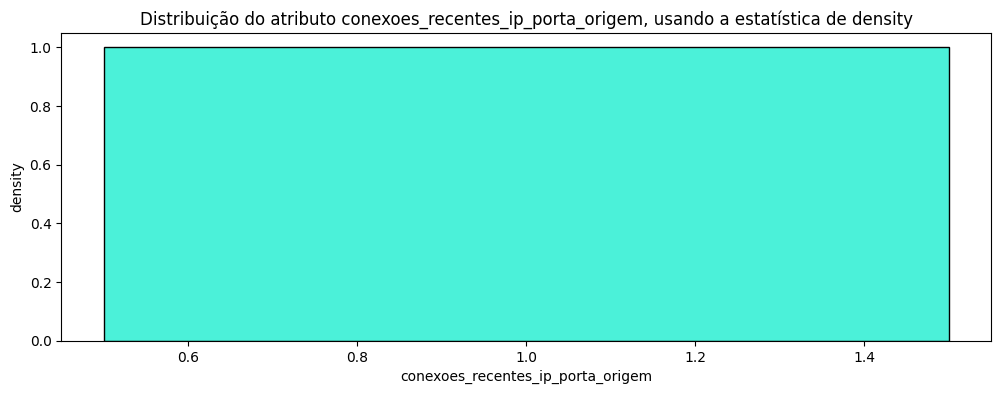

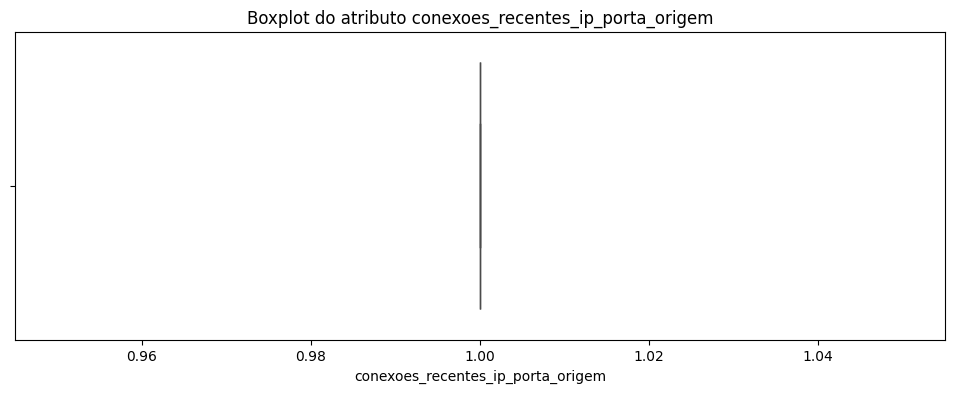




A coluna conexoes_recentes_ip_porta_origem não foi encontrada. Favor digitar uma coluna válida.


 Análise Básica do atributo conexoes_recentes_ip_porta_origem:

 - No total, há None células e destas, None são nulas, None estão repetidas e o total de valores unicos são None.


 Medidas de Tendência Central do atributo conexoes_recentes_ip_porta_origem: 

 - A média aritmética de seus valores é, aproximadamente, 1.00;

 - A mediana é, aproximadamente, 1.00;

 - A moda é, aproximadamente, 1.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 1.00 até 1.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 1.00 a 1.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo conexoes_recentes_ip_porta_origem:

 - 68% da amostra está compreendida entre, aproximadamente, 1.00 e 1.00;

 - 95% da amostra está compreendida entre, aproximadamente, 1.00 

In [72]:
coluna_alvo = ['conexoes_recentes_ip_porta_origem']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 1.00 até 46.00 e agora é de 1.00 até 1.00.

#### 2.31. Atributo ftp_autenticada
---

Este atributo **possui** outliers.

##### 2.31.1. Análise com outliers
---

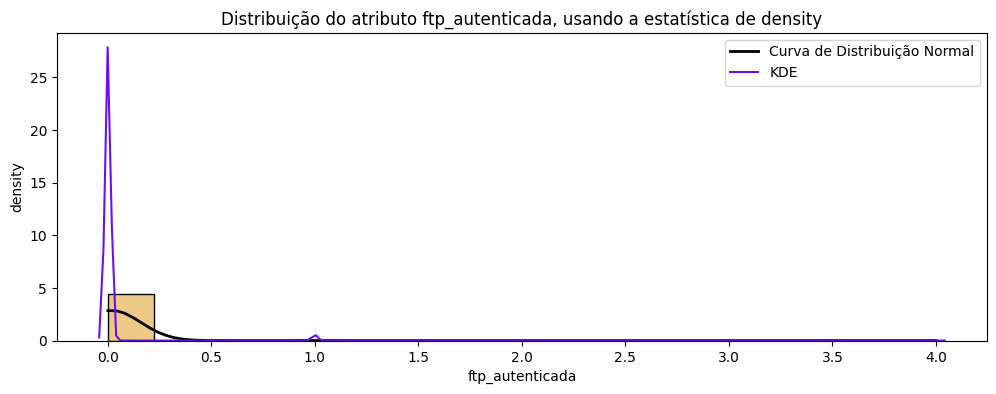

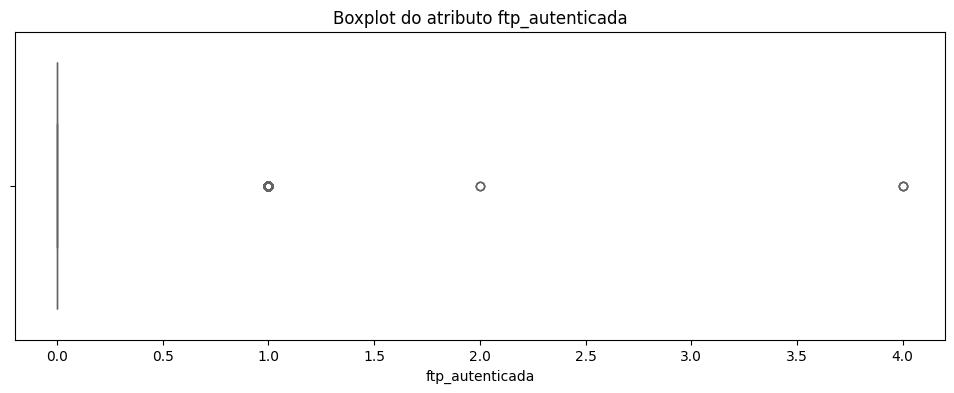






 Análise Básica do atributo ftp_autenticada:

 - No total, há 96822 células e destas, 0 são nulas, 96818 estão repetidas e o total de valores unicos são 4.


 Medidas de Tendência Central do atributo ftp_autenticada: 

 - A média aritmética de seus valores é, aproximadamente, 0.02;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 4.00. Variam em uma faixa de 4.00

 - Desvio Padrão: 0.14

 - Coeficiente de Variação: 7.25 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo ftp_autenticada:

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo ftp_autenticada são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo ftp_autenticada são menores ou iguais a esse valor.

In [73]:
# Lista com o atributo desejado
coluna_alvo = ['ftp_autenticada']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

Este atributo apresenta um comportamento de concentração, já que os outliers são 1.90% do total e o limite superior é 0. A `distribuição não é normal`. O `histograma` exibe um pico absoluto no valor 0.00, onde estão concentrados 98.1% dos registros, que atua como moda, mediana e todos os quartis (25% a 75%). A `Curva Normal` é incapaz de representar os dados, e as regras de ouro falham ao sugerir valores negativos para uma contagem de eventos.

O `boxplot` apresenta a característica de compressão movamente. O `Coeficiente de Variação` de 7.25 é bem alto, refletindo que o `desvio padrão` (0.14) é sete vezes maior que a média (0.02).

Os `outliers serão mantidos`, pois a autenticação FTP é um evento binário ou de baixa frequência neste dataset. A predominância de 0.00 indica que a maioria do tráfego não envolve sessões FTP autenticadas. Entretanto, os outliers (valores até 4.00) são fundamentais para identificar acessos a servidores de arquivos, sendo pontos de interesse para auditoria e detecção de possíveis acessos não autorizados ou movimentação de dados.

##### 2.31.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

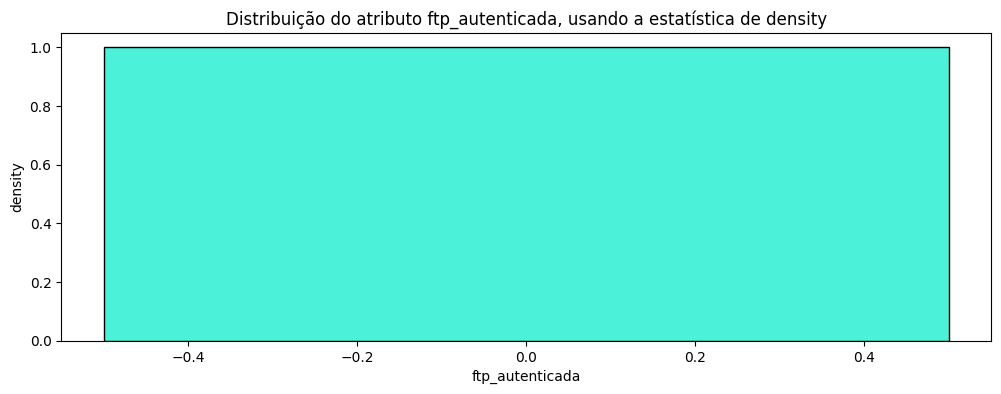

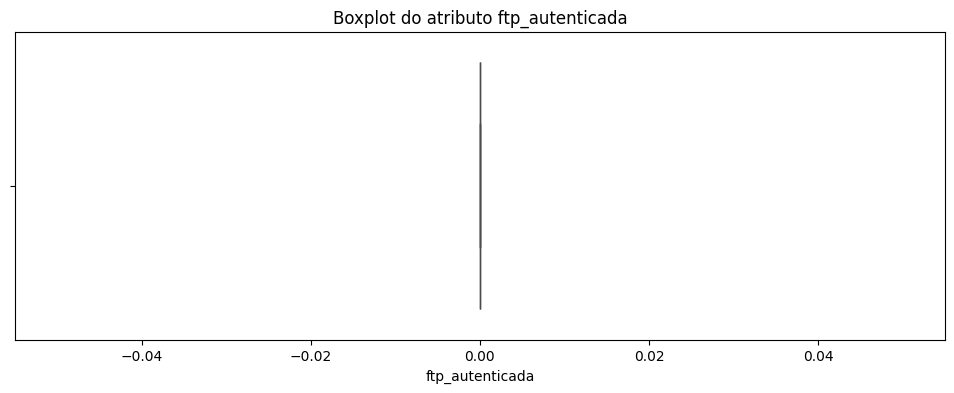






 Análise Básica do atributo ftp_autenticada:

 - No total, há 94978 células e destas, 0 são nulas, 94977 estão repetidas e o total de valores unicos são 1.


 Medidas de Tendência Central do atributo ftp_autenticada: 

 - A média aritmética de seus valores é, aproximadamente, 0.00;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.00 a 0.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo ftp_autenticada:

 - 68% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 95% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 99.7% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00.


In [74]:
coluna_alvo = ['ftp_autenticada']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 até 4.00 e agora é de 0.00 até 0.00.

#### 2.32. Atributo num_comandos_ftp
---

Este atributo **possui** outliers.

##### 2.32.1. Análise com outliers
---

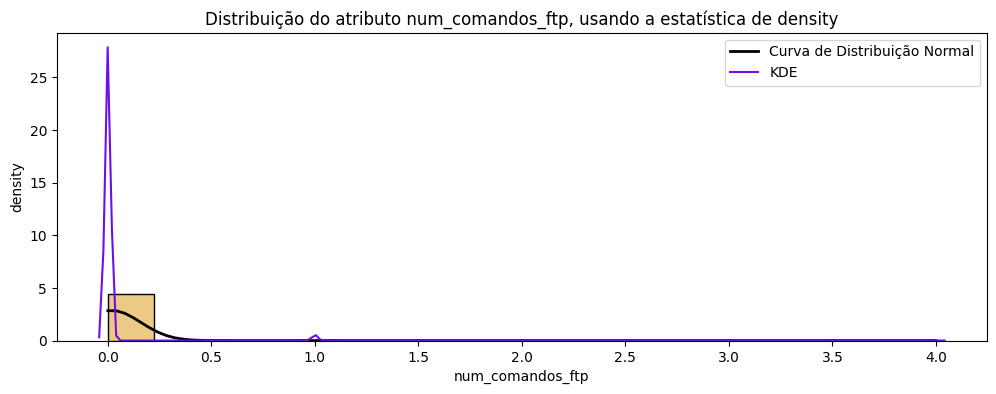

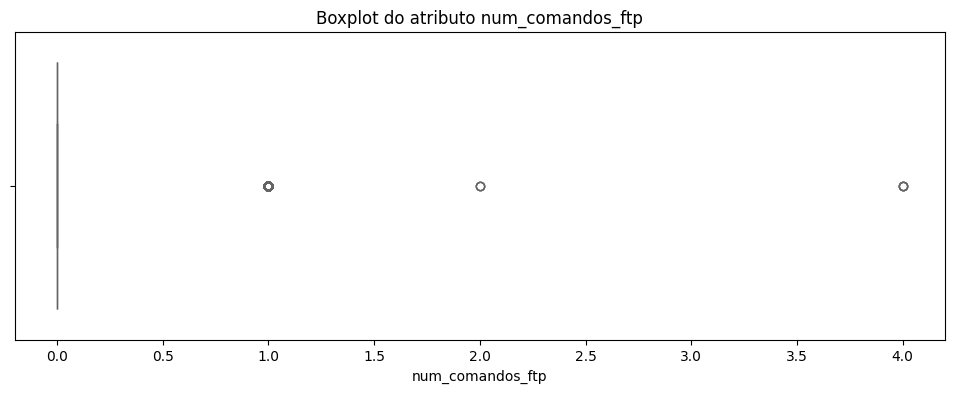






 Análise Básica do atributo num_comandos_ftp:

 - No total, há 96822 células e destas, 0 são nulas, 96818 estão repetidas e o total de valores unicos são 4;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 0.02;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 4.00

 - Desvio Padrão: 0.14

 - Coeficiente de Variação: 7.25 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo num_comandos_ftp são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo num_comandos_ftp são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil de 75% é 0.00. Isto significa que 75% 

In [42]:
# Lista com o atributo desejado
coluna_alvo = ['num_comandos_ftp']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo num_comandos_ftp tem muitas semelhanças com o atributo ftp_autenticada. Apresenta um comportamento de extrema concentração, caracterizando uma `distribuição não normal` com forte assimetria positiva, envolvendo valores relativos a outliers próximos. O `histograma` e o `KDE` mostram um pico absoluto no valor 0.00, como no atributo anterior. A `Curva Normal` é incapaz de representar a realidade dos dados, e a aplicação das regras de ouro gera intervalos negativos (até -0.40) que são desprovidos de sentido lógico para uma contagem de comandos.

O `boxplot` também exibe o fenômeno de compressão. No total, 1.90% dos registros (1.844 células) são considerados outliers, alcançando uma amplitude de até 4.00. O `Coeficiente de Variação` de 7.25 é extremamente elevado, evidenciando que o `desvio padrão` (0.14) é sete vezes superior à média aritmética (0.02), o que comprova a grande dispersão.

Os `outliers serão mantidos`, pois o número de comandos FTP é um indicador fundamental de atividade em servidores de arquivos. A predominância de zeros indica que a grande maioria das interações no dataset não utiliza o protocolo FTP. Entretanto, a presença de até 4 comandos em uma única sessão é um rastro digital valioso para auditorias de segurança, permitindo monitorar a interação com arquivos e detectar possíveis tentativas de transferência de dados ou manipulação de diretórios em sistemas remotos.

##### 2.32.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

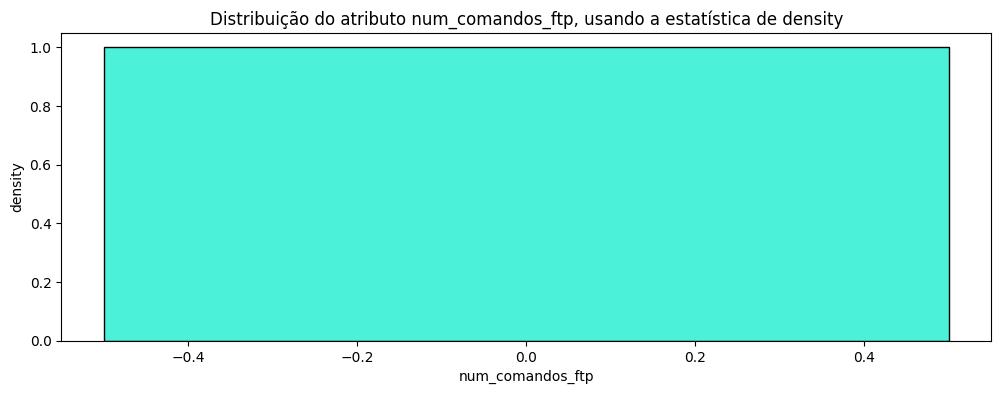

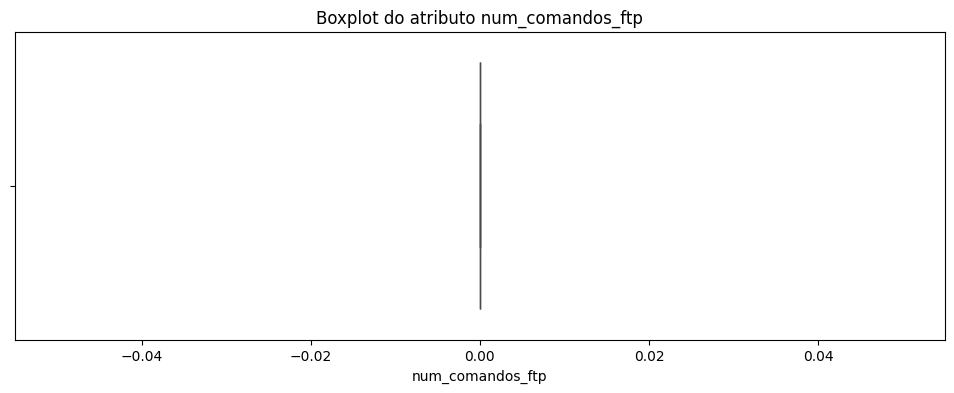






 Análise Básica do atributo num_comandos_ftp:

 - No total, há 94978 células e destas, 0 são nulas, 94977 estão repetidas e o total de valores unicos são 1.


 Medidas de Tendência Central do atributo num_comandos_ftp: 

 - A média aritmética de seus valores é, aproximadamente, 0.00;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.00 a 0.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo num_comandos_ftp:

 - 68% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 95% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 99.7% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00.


In [75]:
coluna_alvo = ['num_comandos_ftp']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 até 4.00 e agora é de 0.00 até 0.00.

#### 2.33. Atributo num_metodos_http
---

Este atributo **possui** outliers.

##### 2.33.1. Análise com outliers
---

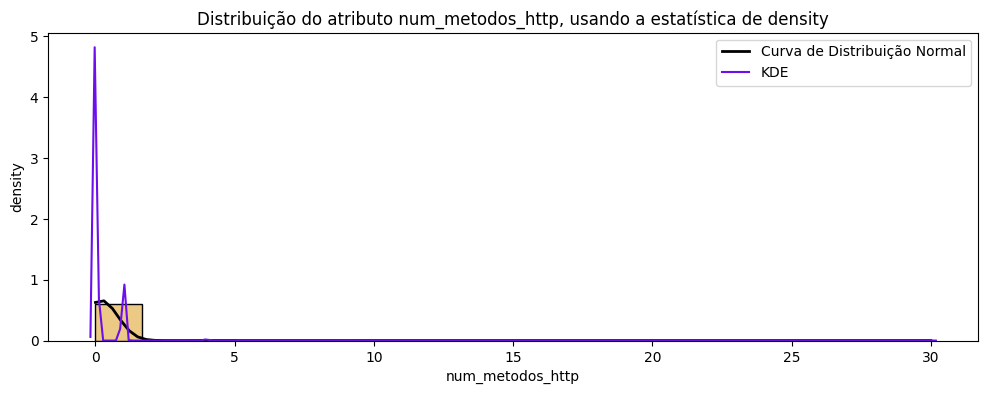

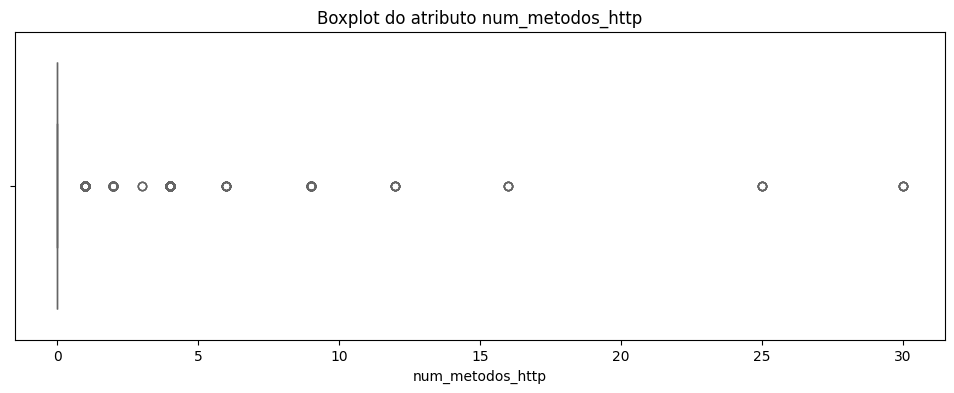






 Análise Básica do atributo num_metodos_http:

 - No total, há 96822 células e destas, 0 são nulas, 96811 estão repetidas e o total de valores unicos são 11.


 Medidas de Tendência Central do atributo num_metodos_http: 

 - A média aritmética de seus valores é, aproximadamente, 0.20;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 30.00. Variam em uma faixa de 30.00

 - Desvio Padrão: 0.60

 - Coeficiente de Variação: 3.00 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis) do atributo num_metodos_http:

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo num_metodos_http são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo num_metodos_http são menores ou iguais a ess

In [76]:
# Lista com o atributo desejado
coluna_alvo = ['num_metodos_http']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    pg.gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    pg.gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo num_metodos_http apresenta um comportamento de forte assimetria positiva, característico de uma `distribuição não normal`. O `histograma` e o `KDE` revelam um pico absoluto no valor 0.00, que concentra a moda, a mediana e todos os quartis (25%, 50% e 75%). A `Curva Normal` aparece totalmente achatada, enquanto a aplicação das regras de ouro gera intervalos negativos (até -1.61) que não possuem aplicação prática para uma contagem de métodos.

O `boxplot` está comprimido. Como o limite superior estatístico também é calculado em 0.00, qualquer registro que apresente ao menos um método HTTP é classificado como outlier superior. No total, 17.77% dos registros (17.203 células) são considerados outliers, alcançando uma amplitude de até 30.00. O `Coeficiente de Variação` de 3.00 confirma que o `desvio padrão` (0.60) é três vezes superior à média aritmética (0.20), evidenciando a grande dispersão.

Os `outliers serão mantidos`, pois o número de métodos HTTP em um fluxo é um indicador técnico valioso. A predominância de zeros indica que a maioria do tráfego capturado não utiliza o protocolo HTTP. Entretanto, os outliers que representam múltiplas chamadas de métodos (como GET, POST, HEAD) dentro de uma mesma conexão são fundamentais para identificar comportamentos de aplicações web, podendo sinalizar desde um uso legítimo e intenso de APIs até tentativas de enumeração de diretórios ou ataques de negação de serviço na camada de aplicação.

##### 2.33.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

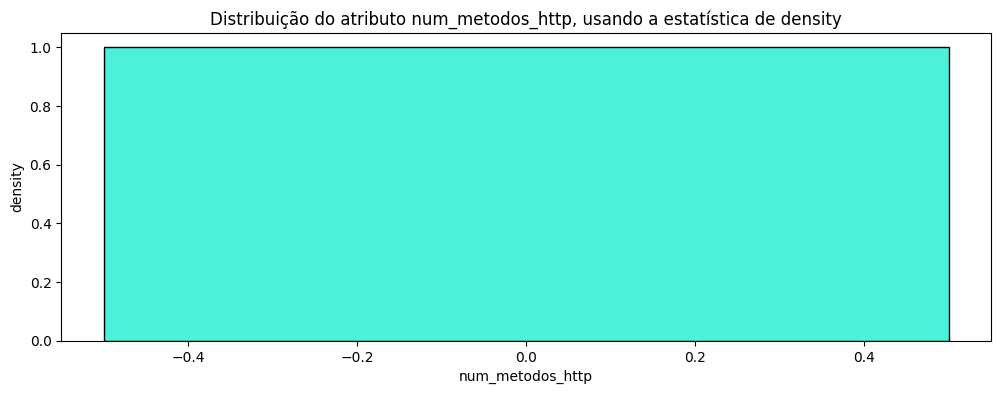

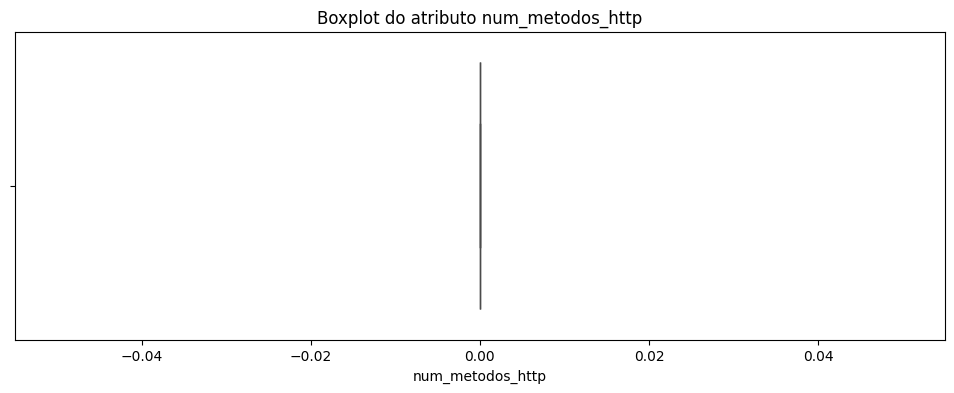






 Análise Básica do atributo num_metodos_http:

 - No total, há 79619 células e destas, 0 são nulas, 79618 estão repetidas e o total de valores unicos são 1.


 Medidas de Tendência Central do atributo num_metodos_http: 

 - A média aritmética de seus valores é, aproximadamente, 0.00;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.00 a 0.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo num_metodos_http:

 - 68% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 95% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 99.7% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00.


In [77]:
coluna_alvo = ['num_metodos_http']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 até 30.00 e agora é de 0.00 até 0.00.

#### 2.34. Atributo ip_porta_origem_destino_iguais
---

Este atributo **possui** outliers.

##### 2.34.1. Análise com outliers
---

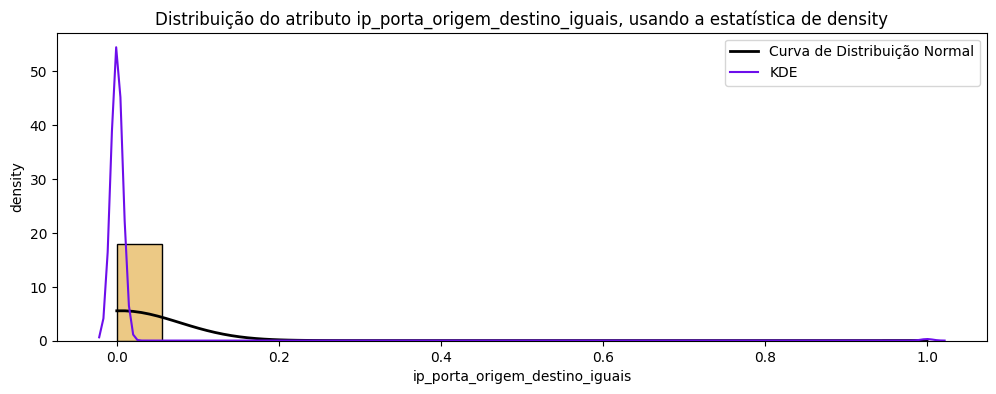

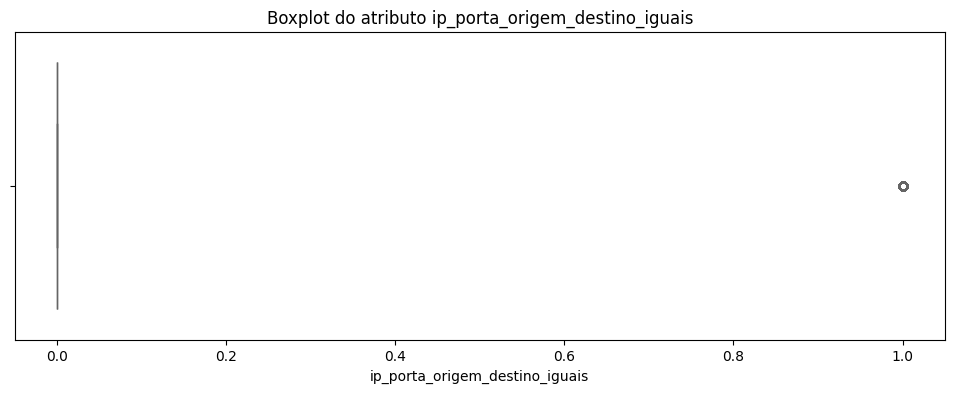






 Análise Básica do atributo ip_porta_origem_destino_iguais:

 - No total, há 96822 células e destas, 0 são nulas, 96820 estão repetidas e o total de valores unicos são 2;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 0.01;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 1.00

 - Desvio Padrão: 0.07

 - Coeficiente de Variação: 13.82 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo ip_porta_origem_destino_iguais são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo ip_porta_origem_destino_iguais são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do qua

In [44]:
# Lista com o atributo desejado
coluna_alvo = ['ip_porta_origem_destino_iguais']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo ip_porta_origem_destino_iguais apresenta um comportamento de extrema concentração, caracterizando uma `distribuição não normal`. O `histograma` e o `KDE` revelam um pico absoluto no valor 0.00, que concentra a moda, a mediana e todos os quartis (25%, 50% e 75%). A `Curva Normal` aparece como uma linha praticamente reta na base, e as regras de ouro falham ao sugerir intervalos negativos (até -0.21) para uma variável booleana/binária.

O `boxplot` está comprimido. Como o limite superior estatístico também é calculado em 0.00, qualquer registro que apresente o valor 1.00 é tecnicamente um outlier superior. No total, apenas 0.52% dos registros (504 células) são considerados outliers. O `Coeficiente de Variação` de 13.82 é um dos mais altos do dataset, evidenciando que o `desvio padrão` (0.07) é 7 vezes superior à média aritmética (0.01), o que comprova a dispersão extrema.

Os `outliers serão mantidos`, pois o fato de o IP e a porta de origem serem iguais aos de destino é um dos indicadores mais críticos em segurança de redes. Em condições normais, esse valor deve ser 0.00. Quando o valor é 1.00, pode indicar a ocorrência de um Land Attack, um tipo de ataque de negação de serviço onde o atacante forja um pacote com o endereço da própria vítima como origem e destino, fazendo com que o sistema entre em um loop infinito de respostas a si mesmo, exaurindo seus recursos.

##### 2.34.2. Análise sem outliers
---

Exclusão dos outliers e geração de gráficos e métricas:

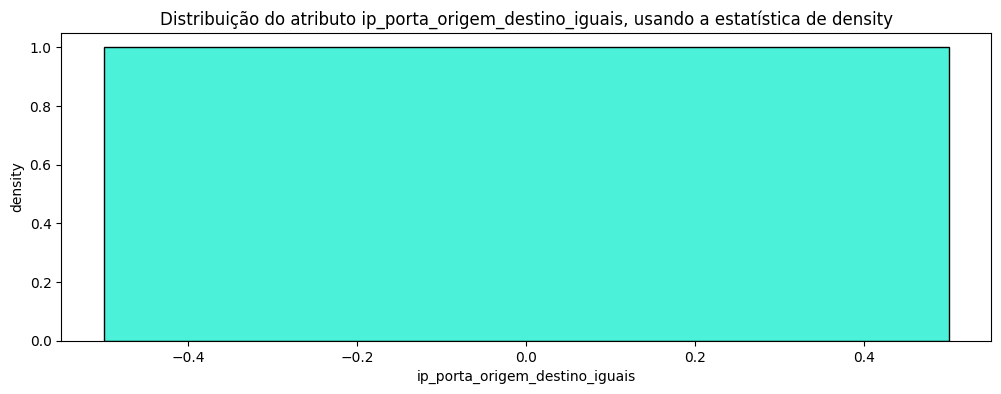

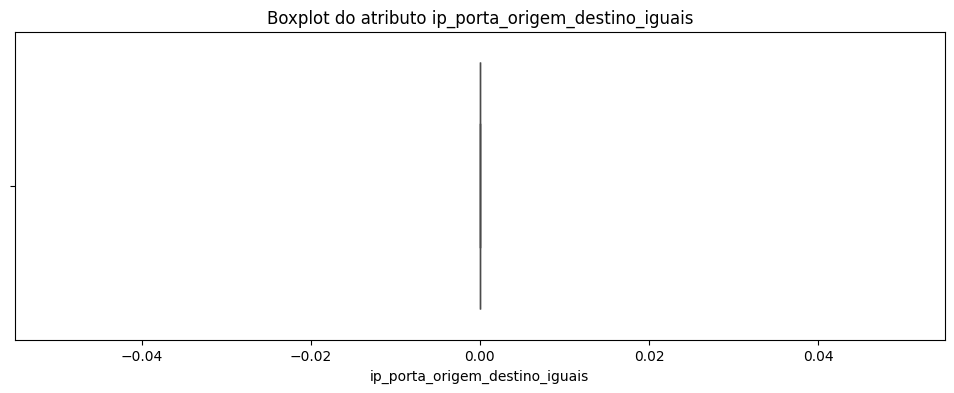






 Análise Básica do atributo ip_porta_origem_destino_iguais:

 - No total, há 96318 células e destas, 0 são nulas, 96317 estão repetidas e o total de valores unicos são 1.


 Medidas de Tendência Central do atributo ip_porta_origem_destino_iguais: 

 - A média aritmética de seus valores é, aproximadamente, 0.00;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 0.00. Variam em uma faixa de 0.00

 - Desvio Padrão: 0.00

 - Coeficiente de Variação: 0.00 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 0.00 a 0.00 (em caso de normalidade).


 Regra de Ouro da Distribuição Normal do atributo ip_porta_origem_destino_iguais:

 - 68% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 95% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00;

 - 99.7% da amostra está compreendida entre, aproximadamente, 0.00 e 0.00.


In [78]:
coluna_alvo = ['ip_porta_origem_destino_iguais']
for col in coluna_alvo:
    _,_,_,limite_inferior, limite_superior,_,_,_,_ = pm.gerar_valor_outliers(df, col)
    df_visualizacao = pp.drop_outlier(df, col, limite_inferior, limite_superior)
    df_visualizacao[(df_visualizacao[col] > limite_superior) | (df_visualizacao[col] < limite_inferior)].shape[0]

for col in coluna_alvo:
        pg.gerar_histograma(df_visualizacao,col, legenda=False, curva_normal=False, kde=False, limite_x=False, cor='#0EEDCD')
        pg.gerar_boxplot(df_visualizacao,col, showfliers=False, cor='#B3ED0E')
        for funcao in medidas_sem_outlier:
            funcao(df_visualizacao,col)

A visualização sem outliers permitiu uma visão mais limpa dos gráficos. Esta confirma que a **distribuição não é normal** mesmo tendo confirmadade com as Regras de Ouro já que possui apenas um bin. A amplitude antes era de 0.00 até 1.00 e agora é de 0.00 até 0.00.

#### 2.35. Atributo categoria_ataque
---

Este atributo **não possui** outliers.

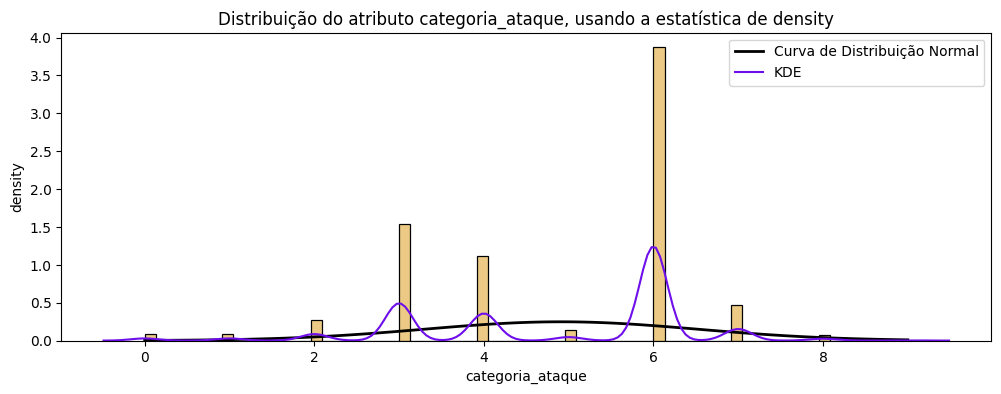

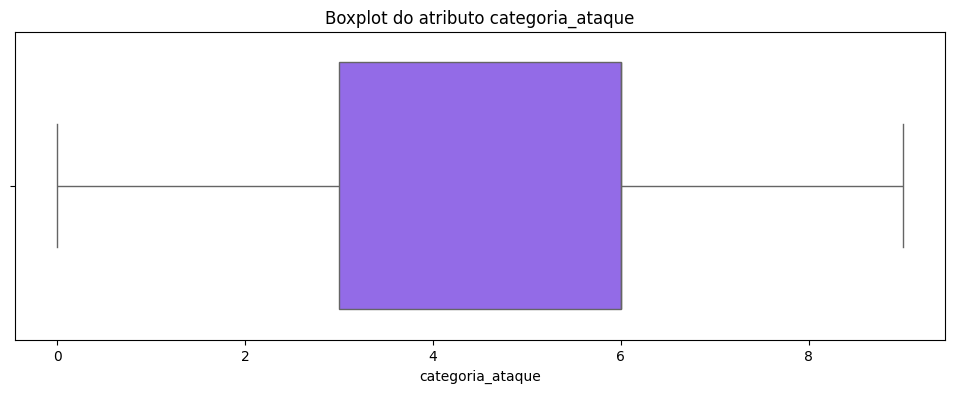






 Análise Básica do atributo categoria_ataque:

 - No total, há 96822 células e destas, 0 são nulas, 96812 estão repetidas e o total de valores unicos são 10;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 4.91;

 - A mediana é, aproximadamente, 6.00;

 - A moda é, aproximadamente, 6.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 9.00

 - Desvio Padrão: 1.61

 - Coeficiente de Variação: 0.33 (Valores > 1 indicam alta dispersão)
Os valores concentram-se num intervalo de 3.30 a 6.52 (em caso de normalidade).


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 3.00. Isto significa que 25% dos dados da amostra do atributo categoria_ataque são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 6.00. Isto significa que 50% dos dados da amostra do atributo categoria_ataque são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil de 75% é 6.00. Isto significa que 75% dos dados 

In [45]:
# Lista com o atributo desejado
coluna_alvo = ['categoria_ataque']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O atributo categoria_ataque apresenta um comportamento distinto dos demais analisados, por ser visivelmente categórico, mas ainda há uma `distribuição não normal` dos dados, já que a `Curva Normal` não acompanha a evolução dos bins. As regras de ouro falham somente ao final em 99.7% da amostra, onde aponta o valor de 9.73, que é maior que o máximo de 9.00. No `histograma` e no `KDE`, observa-se diversos picos de densidade, com destaque absoluto para o valor 6.00 (moda e mediana), indicando que os dados estão agrupados em categorias específicas bem definidas.

Diferente dos atributos técnicos de rede, o `boxplot` aqui possui um "corpo" robusto, com a caixa estendendo-se do valor 3.00 (25%) ao 6.00 (75%). `Não foram detectados outliers` (0,00%), pois todos os valores da amostra (de 0.00 a 9.00) estão contidos dentro dos limites estatísticos calculados (limite superior de 10.50). O `Coeficiente de Variação` de 0.33 é baixo, indicando que, apesar da natureza categórica, existe uma concentração previsível em torno da média aritmética (4.91).

#### 2.36. Atributo label
---

Este atributo **não possui** outliers.

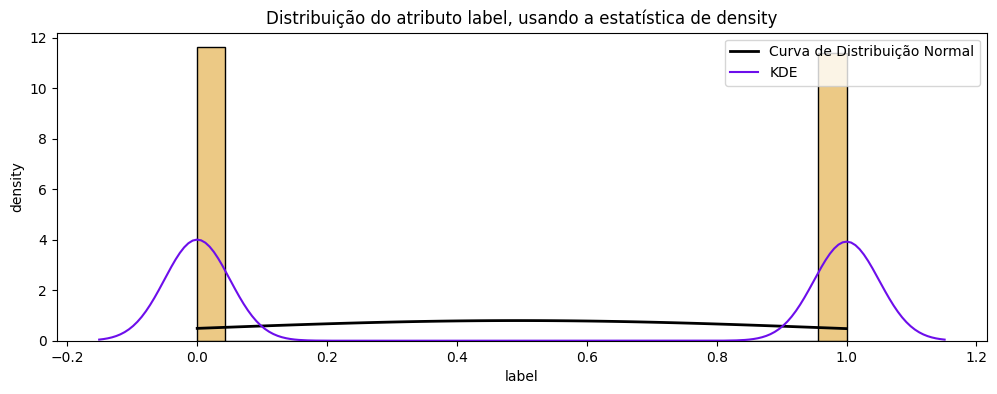

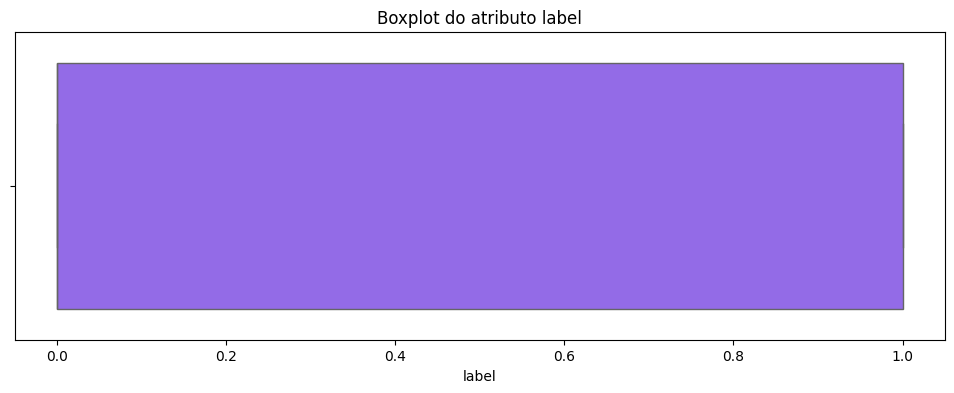






 Análise Básica do atributo label:

 - No total, há 96822 células e destas, 0 são nulas, 96820 estão repetidas e o total de valores unicos são 2;


 Medidas de Tendência Central: 

 - A média aritmética de seus valores é, aproximadamente, 0.50;

 - A mediana é, aproximadamente, 0.00;

 - A moda é, aproximadamente, 0.00;


 Medidas de Dispersão e Amplitude

 - Amplitude: de 0.00 até 1.00

 - Desvio Padrão: 0.50

 - Coeficiente de Variação: 1.01 (Valores > 1 indicam alta dispersão)
Nota: O desvio padrão é superior à média, confirmando a presença de outliers e assimetria.


 Medidas de Posição (Quartis):

 - O valor do quartil de 25% é 0.00. Isto significa que 25% dos dados da amostra do atributo label são menores ou iguais a esse valor;

 - O valor do quartil de 50% é 0.00. Isto significa que 50% dos dados da amostra do atributo label são menores ou iguais a esse valor. Equivale à mediana;

 - O valor do quartil de 75% é 1.00. Isto significa que 75% dos dados da amostra do atributo 

In [46]:
# Lista com o atributo desejado
coluna_alvo = ['label']

# Iteração sobre a lista coluna_alvo gerando o Histograma e Boxplot
for col in coluna_alvo:
    gerar_histograma(df,col, legenda=True, curva_normal=True, kde=True)
    gerar_boxplot(df,col)
    # Iteração sobre a lista funcoes_medidas gerando os textos de medidas do atributo
    for funcao in funcoes_medidas:
        funcao(df,col)

O `histograma` e o `KDE` mostram dois picos de densidade absolutos nos valores 0.00 e 1.00. A `Curva Normal` aparece quase plana no centro, sendo incapaz de representar a realidade dos dados, já que a maior parte da amostra está nas extremidades e não em torno da média aritmética (0.50). As regras de ouro geram intervalos que extrapolam os limites físicos da variável (indo de -1.00 a 1.99), o que reforça a `inadequação do modelo normal` para este caso.

O `boxplot` exibe um corpo que preenche quase toda a amplitude do gráfico, estendendo-se do primeiro quartil (0.00) ao terceiro quartil (1.00). `Não foram detectados outliers` (0.00%), pois os limites estatísticos calculados (-1.50 a 2.50) englobam totalmente os valores reais da amostra. O Coeficiente de Variação de 1.01 e o desvio padrão (0.50) confirmam a alta dispersão, resultante da separação clara entre as duas categorias existentes.

### 3 - t-SNE para atributos categóricos
---

#### 3.2. Visualização do t-SNE
---

Para todos os atributos categóricos, será disponibilizado uma imagem que contém os nomes de suas categorias antes do encoding, para maior entendimento.

#### 3.3. Atributo categoria_ataque
---

- Categorias antes do encoding:

<div style="text-align: center;">
  <img src="../imagens/ataque_categorias.png" width="400">
</div>

- Categorias depois do encoding:

In [48]:
df['categoria_ataque'].value_counts()

categoria_ataque
6.0    48894
3.0    19360
4.0    14082
7.0     6000
2.0     3369
5.0     1800
1.0     1121
0.0     1119
8.0      954
9.0      123
Name: count, dtype: int64

- Geração do t-SNE:

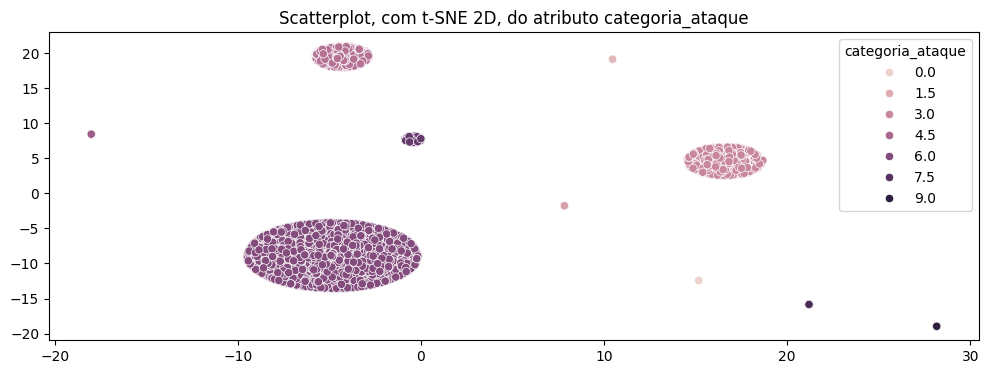

<Axes: title={'center': 'Scatterplot, com t-SNE 2D, do atributo categoria_ataque'}>

In [26]:
pg.gerar_scatterplot(df, nome_col='categoria_ataque',tsne2d=True)

O `t-SNE` do atributo `categoria_ataque` mostra de forma muito clara o desbalanceamento de classes. Há grandes grupos se formando, enquanto outros menores ficam espalhados. Além disso, há ataques que possuem tão poucas ocorrências, como `Worms` que acabam não aparecendo no gráfico ou até "escondidas" dentro de clusters.

Há, ataques que se distanciam muito dos clusters maiores, o que pode fazer com que sejam mais fáceis de serem compreendidos e classificados pelo modelo de Machine Learning, por serem características únicas e não se confundirem com as demais, mais agrupadas.

#### 3.4. Atributo servico_conexao
---

- Categorias antes do encoding:

<div style="text-align: center;">
  <img src="../imagens/servico_categorias.png" width="400">
</div>

- Categoria depois do encoding:

In [32]:
df['servico_conexao'].value_counts()

servico_conexao
0.0     57971
5.0     18090
2.0      7181
9.0      5023
4.0      3282
3.0      2687
11.0     1295
7.0      1104
12.0       56
1.0        51
10.0       45
6.0        25
8.0        12
Name: count, dtype: int64

- Geração do t-SNE:

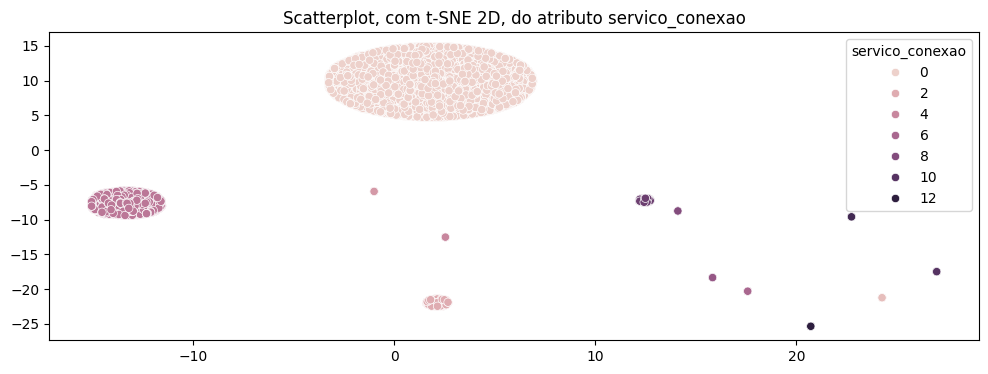

<Axes: title={'center': 'Scatterplot, com t-SNE 2D, do atributo servico_conexao'}>

In [27]:
pg.gerar_scatterplot(df, nome_col='servico_conexao',tsne2d=True)

O `t-SNE` do atributo `servico_conexao` mostra de forma muito clara o desbalanceamento de classes, de forma mais clara que o atributo `categoria_ataque`, já que há um cluster muito grande e outros muito menores. 

Há grandes espalhamentos de grupos menores. Além disso, há ataques que possuem tão poucas ocorrências, como `Radius` e `IRC` que acabam não aparecendo no gráfico ou até "escondidas" dentro de clusters.

Da mesma forma, há serviços de conexão que se distanciam muito dos clusters maiores, o que pode fazer com que sejam mais fáceis de serem compreendidos e classificados pelo modelo de Machine Learning, por serem características únicas e não se confundirem com as demais, mais agrupadas.

#### 3.5. Atributo estado_conexao
---

- Categorias antes do encoding:

<div style="text-align: center;">
  <img src="../imagens/estado_categorias.png" width="400">
</div>

- Categorias depois do encoding:

In [51]:
df['estado_conexao'].value_counts()

estado_conexao
2.0    74345
0.0    10976
3.0    10812
5.0      594
6.0       83
1.0        9
4.0        1
7.0        1
8.0        1
Name: count, dtype: int64

- Geração do t-SNE:

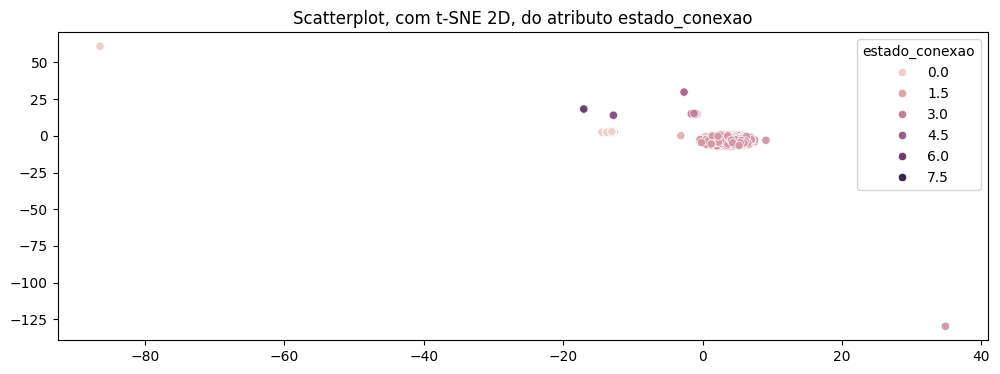

<Axes: title={'center': 'Scatterplot, com t-SNE 2D, do atributo estado_conexao'}>

In [28]:
pg.gerar_scatterplot(df, nome_col='estado_conexao',tsne2d=True)

O `t-SNE` do atributo `estado_conexao` mostra desbalanceamento de classes, mas é diferente dos anteriores já que, mesmo havendo concentrações em clusters ligeiramente maiores, há um espalhamento menor. Isso mostra claramente a proximidade entre as classes e sugere que é um atributo mais `padronizado`, com menor `variância`.

Também há classes com poucas ocorrências, como `NO`, `URN` e `PAR`, podendo essas não aparecer no gráfico ou até se "escondider" dentro dos clusters mairoes.

Da mesma forma, os ataques estados de conexão se distanciam dos clusters maiores, mesmo sendo menos espalhados, em comparação com os atributos anteriores, podem estar mais fáceis de serem compreendidos e classificados pelo modelo de Machine Learning, por serem características únicas e não se confundirem com as demais, mais agrupadas.

#### 3.6. Atributo protocolo_rede
---

- Categorias antes do enconding:

<div style="display: flex; justify-content: center; gap: 20px;">
  <img src="../imagens/protocolo_categorias_head.png" width="400">
  <img src="../imagens/protocolo_categoria_tail.png" width="400">
</div>

- Categoria depois do encoding:

In [36]:
dict(df['protocolo_rede'].value_counts())

{113.0: np.int64(75805),
 119.0: np.int64(15238),
 78.0: np.int64(769),
 6.0: np.int64(591),
 120.0: np.int64(350),
 97.0: np.int64(305),
 3.0: np.int64(61),
 32.0: np.int64(60),
 110.0: np.int64(57),
 111.0: np.int64(57),
 90.0: np.int64(56),
 80.0: np.int64(51),
 71.0: np.int64(48),
 100.0: np.int64(46),
 52.0: np.int64(45),
 20.0: np.int64(31),
 72.0: np.int64(31),
 15.0: np.int64(31),
 68.0: np.int64(31),
 0.0: np.int64(31),
 40.0: np.int64(31),
 127.0: np.int64(31),
 124.0: np.int64(31),
 22.0: np.int64(31),
 24.0: np.int64(31),
 31.0: np.int64(31),
 132.0: np.int64(31),
 92.0: np.int64(31),
 28.0: np.int64(31),
 46.0: np.int64(31),
 54.0: np.int64(31),
 104.0: np.int64(31),
 47.0: np.int64(31),
 10.0: np.int64(31),
 112.0: np.int64(31),
 2.0: np.int64(31),
 95.0: np.int64(31),
 27.0: np.int64(31),
 14.0: np.int64(31),
 125.0: np.int64(31),
 35.0: np.int64(31),
 63.0: np.int64(31),
 102.0: np.int64(31),
 29.0: np.int64(31),
 85.0: np.int64(31),
 106.0: np.int64(31),
 67.0: np.int6

- Geração do t-SNE:

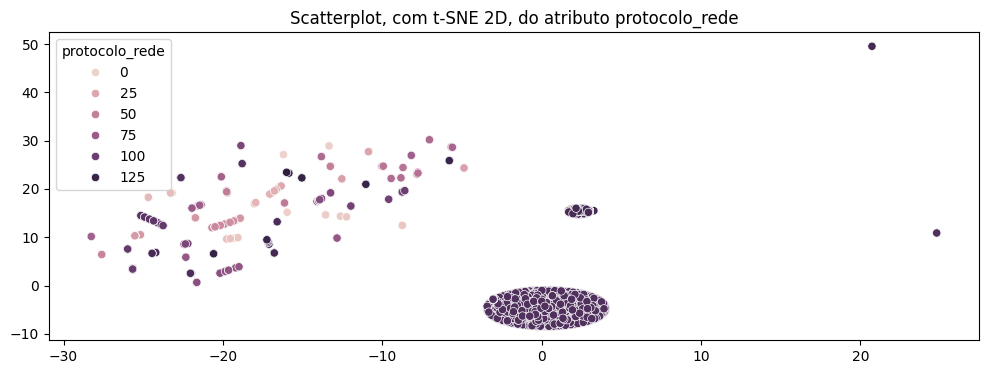

<Axes: title={'center': 'Scatterplot, com t-SNE 2D, do atributo protocolo_rede'}>

In [29]:
pg.gerar_scatterplot(df, nome_col='protocolo_rede',tsne2d=True)

O `t-SNE` do atributo `protocolo_rede` mostra desbalanceamento de classes de forma muito clara, mas é diferente dos anteriores já que, mesmo havendo concentrações em clusters muito maiores, há um espalhamento maior, onde nos pontos `-30` a `-5`, aproximadamente, há uma aglomerado de protocolos diferentes, que formam clusters muito pequenos, enquanto no centr, há um cluster desproporcional. Isso mostra claramente uma "setorização" do gráfico, onde do centro à esquerda está bem populado e à direita, está muito menos. Sugere que não é um atributo tão `padronizado` e com menor `variância` como de `estado_conexao`.

Também há classes com poucas ocorrências, como `RTP`, `ICMP` e `IGP`, podendo essas não aparecer no gráfico ou até se "escondider" dentro dos clusters mairoes.

Da mesma forma, os protocolos que se distanciam dos clusters maiores, mesmo sendo menos espalhados, em comparação com os atributos anteriores, podem estar mais fáceis de serem compreendidos e classificados pelo modelo de Machine Learning, por serem características únicas e não se confundirem com as demais, mais agrupadas. Contudo, a aglomeração à esquerda pode ser um desafio para o modelo, já que estão bem próximos uns dos outros.

### 4 - Conclusões das análises
---

Após as análises dos atributos, conclui-se que:

1. `Distribuição e Normalidade`: Confirmou-se que os atributos do dataset **não** seguem uma `distribuição normal`. O uso recorrente das `Regras de Ouro`revelou intervalos com valores negativos fisicamente impossíveis e `Curvas de Distribuição Normal` severamente achatadas em relação à `densidade real (KDE)`. Portanto, para identificar relações entre as variáveis, será utilizada a `Matriz de Correlação de Spearman`, que é mais robusta para dados não lineares e não normais. Isso foi confirmado pelos `histogramas`, curvas normais e KDEs utilizados sem outliers com o `df_visualização`. Este mostrou também, que alguns atributos se concentram de forma muita clara em um único bin.

2. `Identificação de Outliers`: Embora atributos como o `num_sequencia_tcp_origem` não tenham apresentado outliers, a maioria das variáveis de tráfego (como carga_destino, jitter e pacotes_perdidos) exibiu uma presença significativa de valores discrepantes.

3. `Decisão de Manutenção`: Optou-se pela manutenção integral dos outliers. No domínio da cibersegurança e análise de redes, esses valores extremos não são erros, mas sim assinaturas críticas de comportamentos anômalos, picos de instabilidade ou ataques reais.

4. `Desbalanceamento de Classes`: os `Scatterplots` com `t-SNE 2D` mostraram que as classes categóricas estão todas desbalanceadas, cada uma a sua forma. Algumas mostram um maior espalhamento de valores e outras menor, mas é possível ver clusters mais agrupados em todas. É possível perceber que certas classes, possuem uma densidade menor, e por isso, podem não aparecer no gráfico ou estarem invisíveis dentro de um cluster.   

### 5 - Normalização de Features
---

As análises dos atributos, indicaram variações de valores muito bruscas entre eles. Para isso, opta-se por realizar a `Normalização das Features`. O método de escalonamento escolhido foi o `Robust Scaler`, por ser resistente aos `Outliers`, que foram preservados, presentes na maioria dos atributos e a `Distribuição Não Normal`, presentes em todos.

In [24]:
escalonador = RobustScaler()

# Lista que contém os atributos categóricos e/ou com poucos valores únicos
atr_nao_categoricos = df.drop(columns=['protocolo_rede','tamanho_janela_tcp_origem', 'servico_conexao','estado_conexao','categoria_ataque'])

for col in atr_nao_categoricos:
    _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(df, col)
    print(f'\n\nAtributo {col.upper()}:\n')
    print(f'O atributo {col} possui amplitude entre {valor_min} e {valor_max} e magnitude {faixa} antes da Normalização com RobustScaler.\n')
    
    normalizacao = pp.normalizar_feature_rs(df, col, escalonador, div_max=True)
    df[col] = normalizacao
    
    _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(df, col)
    print(f'O atributo {col} foi normalizado. Sua amplitude atual está entre {valor_min} e {valor_max} e sua magnitude, em {faixa}.\n')



Atributo DURACAO_CONEXAO_SEG:

O atributo duracao_conexao_seg possui amplitude entre 0.0 e 59.9999885559082 e magnitude 59.9999885559082 antes da Normalização com RobustScaler.

O atributo duracao_conexao_seg foi normalizado. Sua amplitude atual está entre -0.007463771721579172 e 1.0 e sua magnitude, em 1.007463771721579.



Atributo NUM_PACOTES_ORIGEM:

O atributo num_pacotes_origem possui amplitude entre 1 e 9616 e magnitude 9615 antes da Normalização com RobustScaler.

O atributo num_pacotes_origem foi normalizado. Sua amplitude atual está entre -0.0009369144284821987 e 1.0 e sua magnitude, em 1.000936914428482.



Atributo NUM_PACOTES_DESTINO:

O atributo num_pacotes_destino possui amplitude entre 0 e 10974 e magnitude 10974 antes da Normalização com RobustScaler.

O atributo num_pacotes_destino foi normalizado. Sua amplitude atual está entre -0.0007295276308590188 e 1.0 e sua magnitude, em 1.000729527630859.



Atributo TOTAL_BYTES_ORIGEM:

O atributo total_bytes_origem possui a

### 6 - Matriz de Correlação de Spearman
---

A `Matriz de Correlação de Spearman` é relevante, sobretudo, para indicar o como as `features` se comportam perante ao `target`. É indicada para um cenário em que a distribuição de `dados não é normal`. 

Nela são apresentados números de -1 a 1, onde se vê as correlações positiva (x > 0), negativa (0 < x) e neutras (x = 0).

Há a possibilidade de se perceber:

 - se ao aumentar o valor de um atributo, o outro também aumenta e se diminuir um, ambos diminuem (`correlação positiva`);
 - se diminuir o valor de um, aumenta o do outro e vice-versa (`correlação negativa`);
 - a variação de um não afeta o outro (`correlação neutra`).

#### 6.1. Divisão do df em duas partes para facilitar a visualização da matriz
---

In [25]:
colunas = df.columns.to_list()

targets = colunas[-2:]

metade = len(colunas) // 2

colunas_parte1 = colunas[:metade] + targets
colunas_parte2 = colunas[metade:]

#### 6.2. Matriz de Correlação da primeira metade das coluna
---

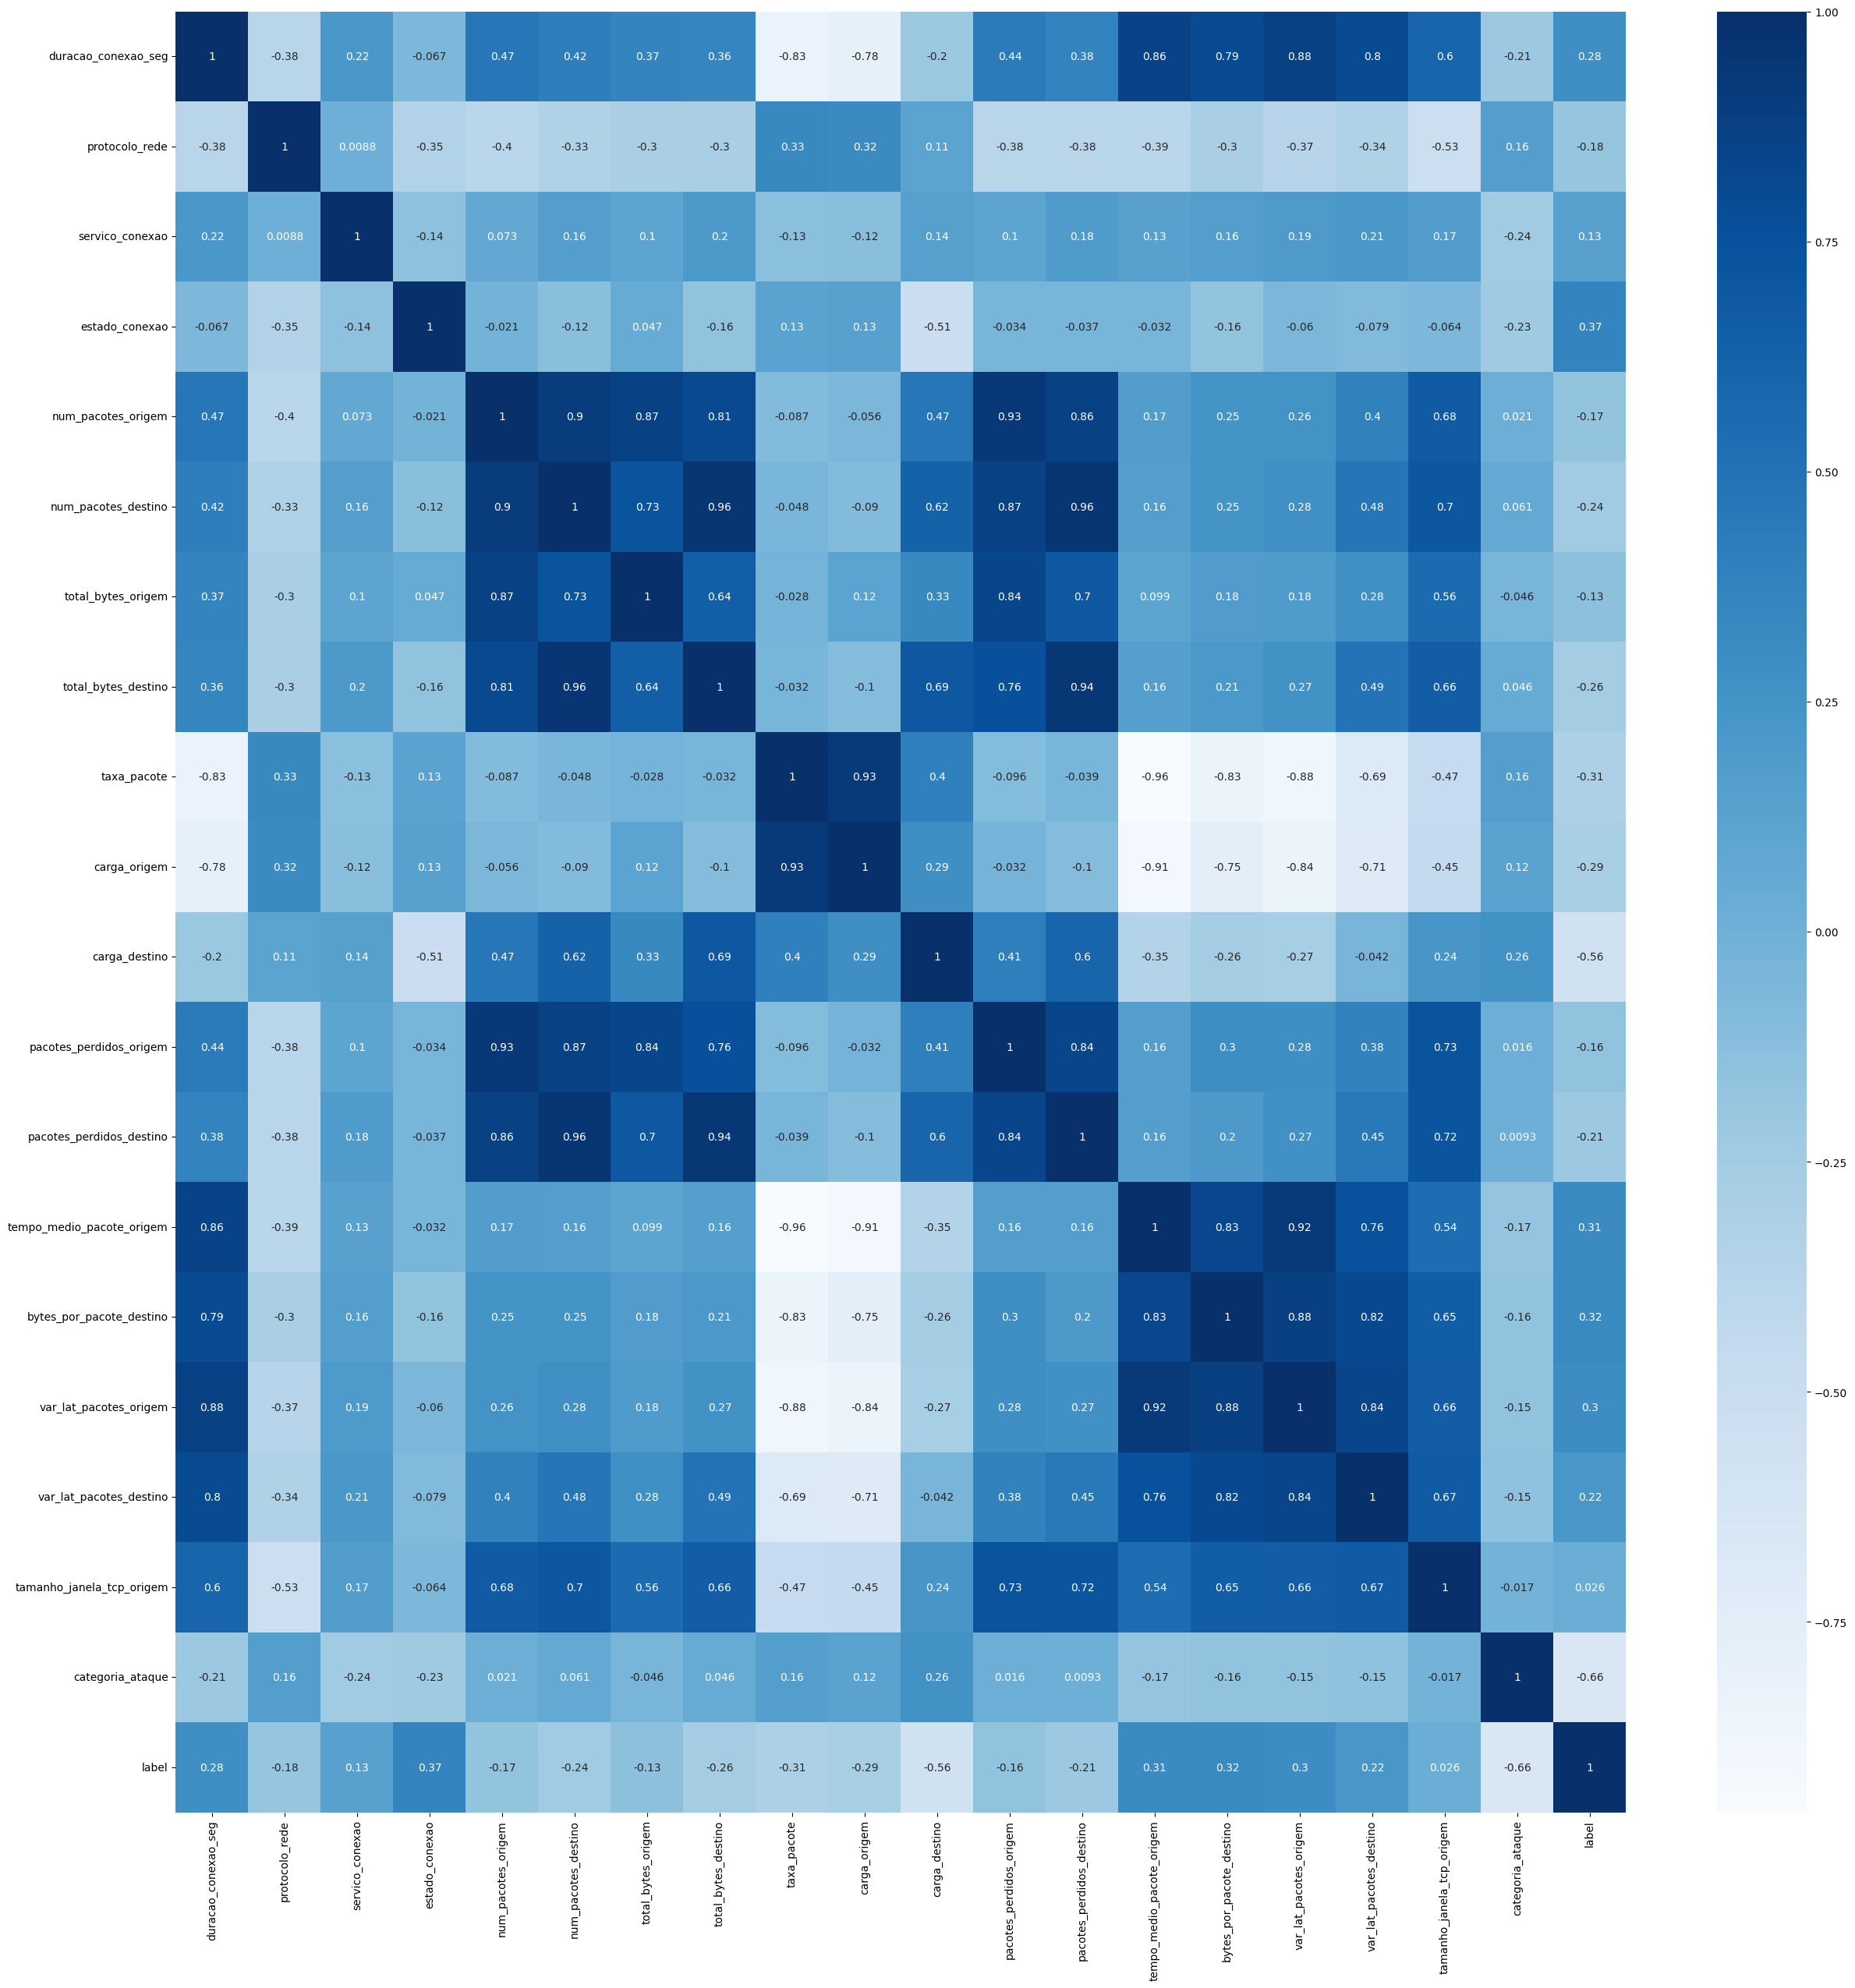

In [26]:
matriz_correlacao = df[colunas_parte1].corr(method='spearman')

plt.figure(figsize=(30,30))

sns.heatmap(matriz_correlacao, annot=True, cmap='Blues')

plt.show()

#### 6.3. Matriz de Correlarção da segunda metade das coluna
---

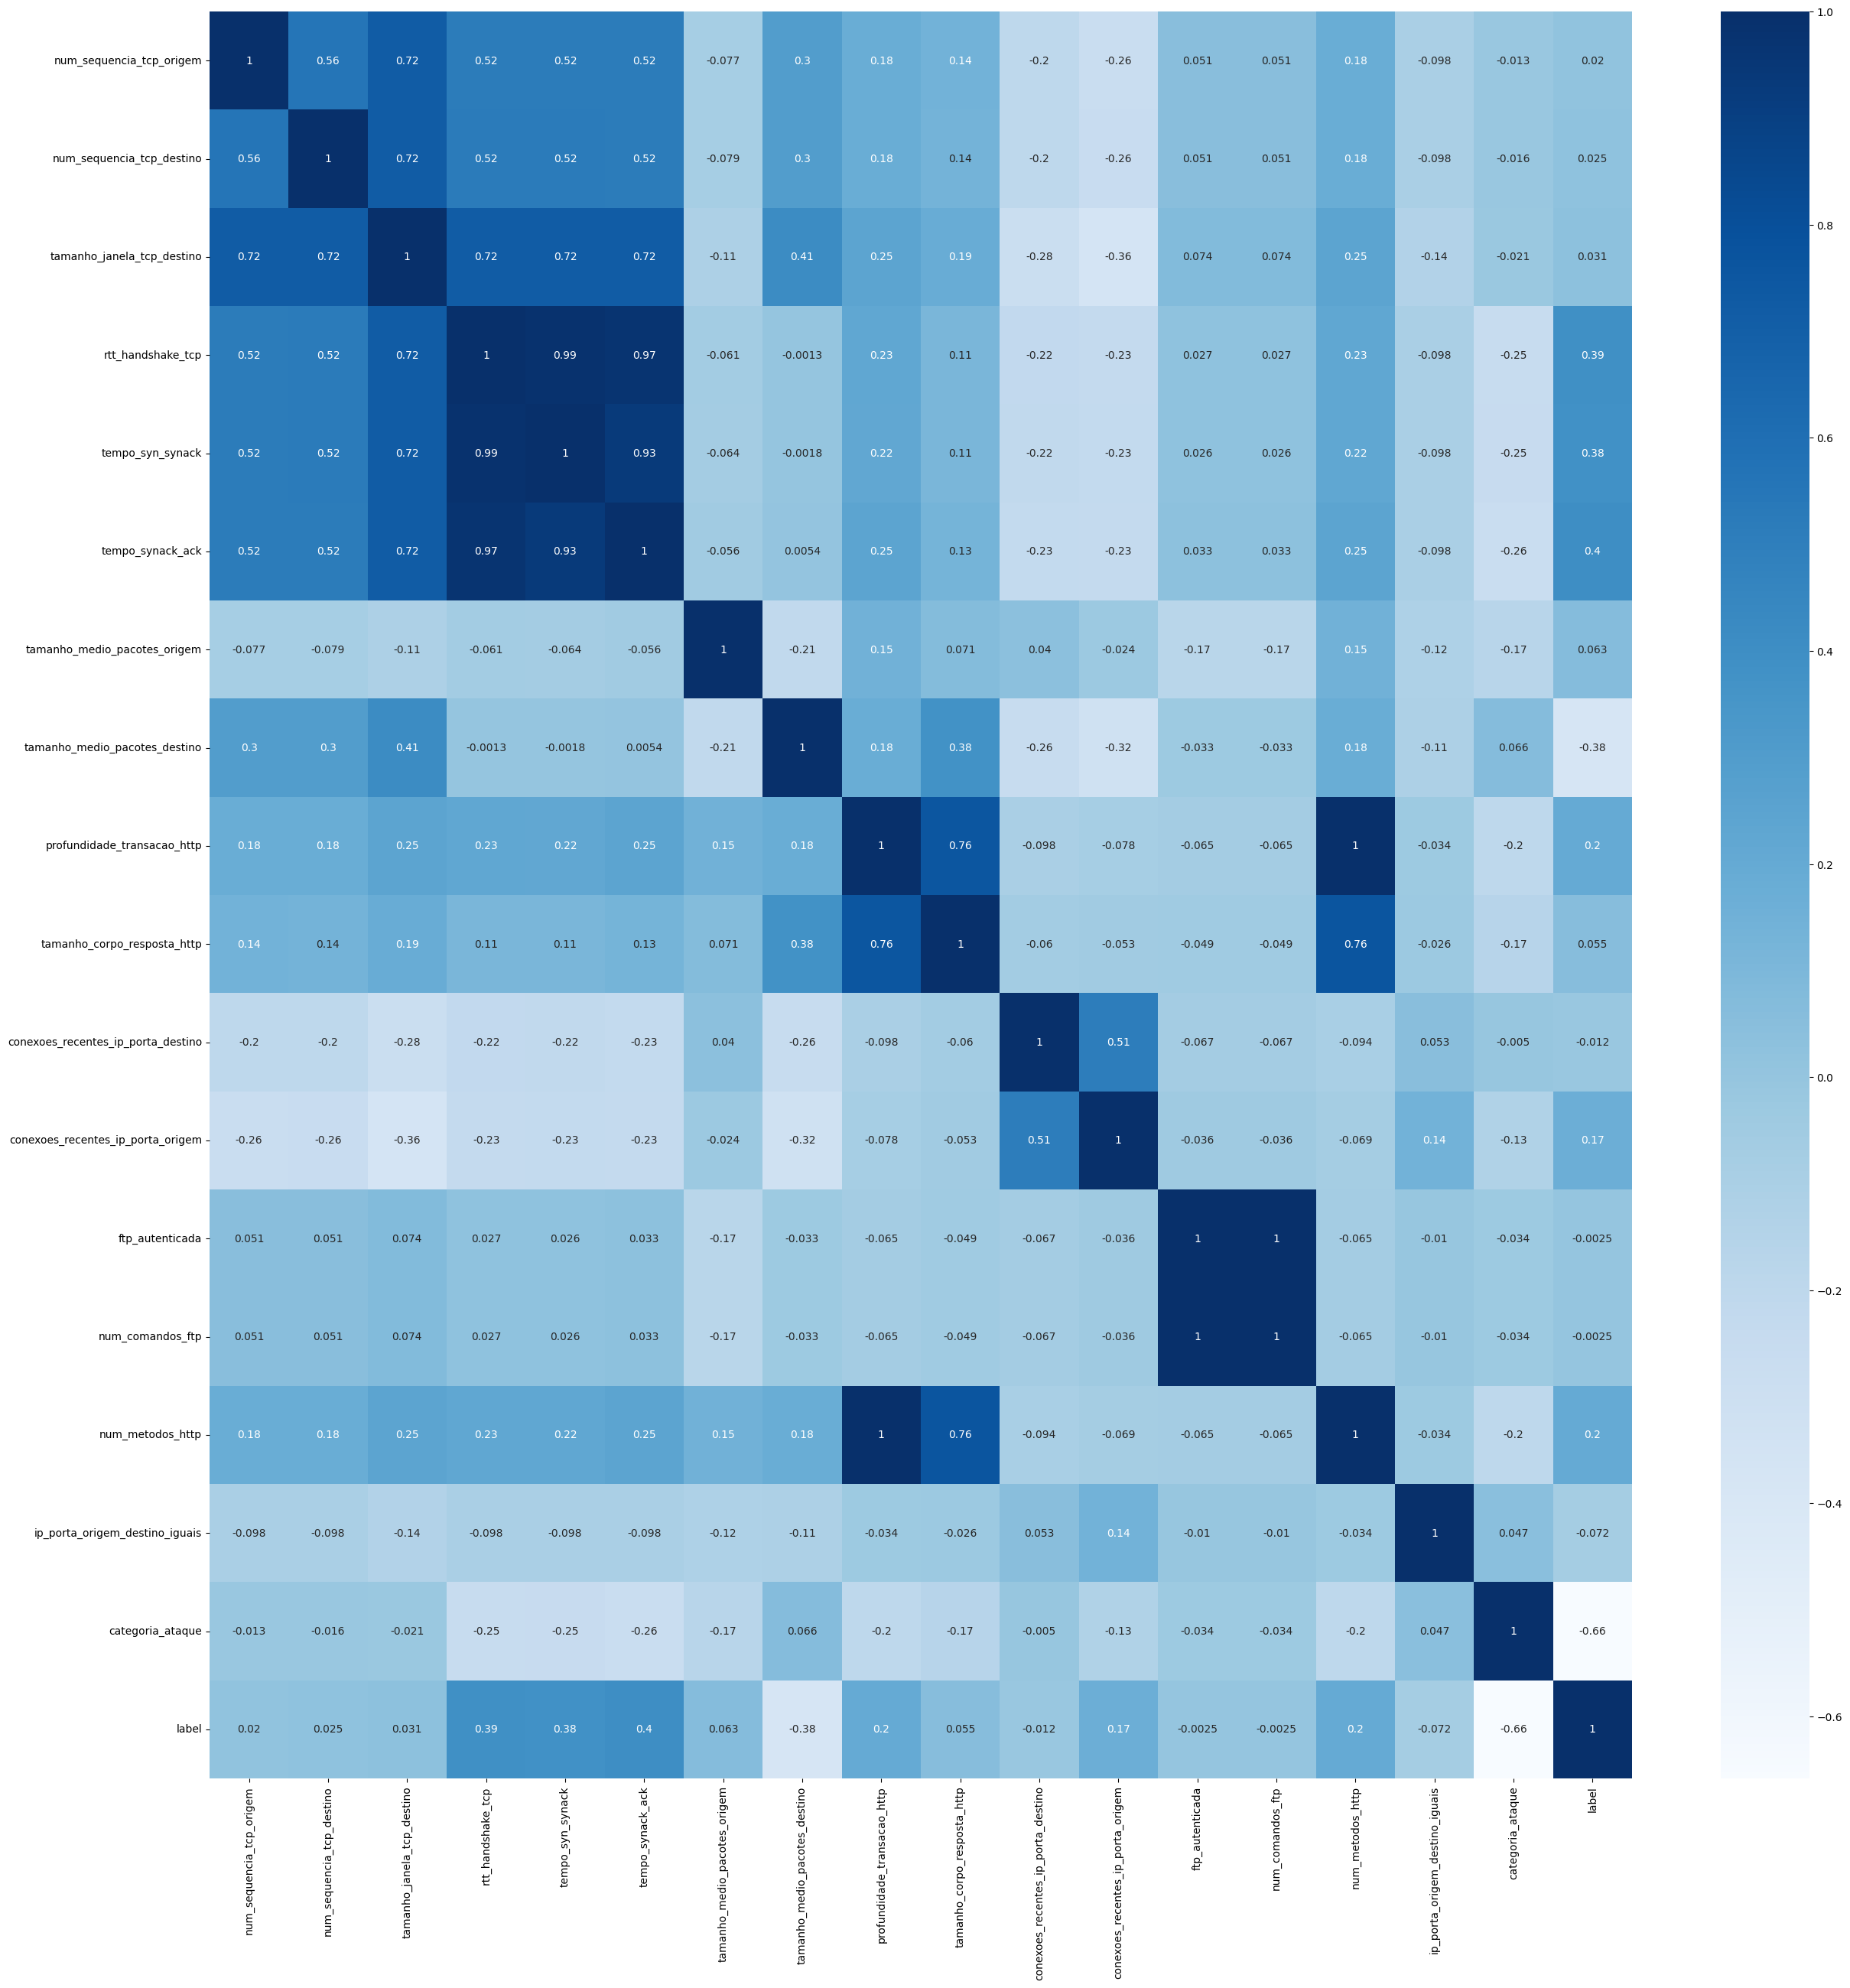

In [27]:
matriz_correlacao = df[colunas_parte2].corr(method='spearman')

plt.figure(figsize=(30,30))

sns.heatmap(matriz_correlacao, annot=True, cmap='Blues')

plt.show()

#### 6.4. Análises da Matriz de Correlação de Spearman
---

A análise a ser feita é entre as features e os potenciais targets, `label` e `categoria_ataque`. 

O objetivo é saber quais possuem maior afinidade positiva ou negativa com os alvos, com o intuito de determinar quais features tem prioridade e quais tem menor, podendo até ser estudado a exclusão dela.

| Feature | categoria_ataque | Label |
| :---: | :---: | :---: |
| `duracao_conexao_seg` | -0.21 | **0.28** |
| `protocolo_rede` | **0.16** | -0.18 |
| `servico_conexao` | -0.24 | 0.13 |
| `estado_conexao` | -0.23 | **0.37** |
| `num_pacotes_origem` | 0.021 | -0.17 |
| `num_pacotes_destino` | 0.061 | -0.24 |
| `total_bytes_origem` | -0.046 | -0.13 |
| `total_bytes_destino` | 0.046 | **-0.26** |
| `taxa_pacote` | 0.16 | **-0.31** |
| `carga_origem`  | 0.12 | **-0.29** |
| `carga_destino` | **0.26** | **-0.56** |
| `pacotes_perdidos_origem` | 0.016 | -0.16 |
| `pacotes_perdidos_destino` | 0.0093 | -0.21 |
| `tempo_medio_pacote_origem` | -0.17 | **0.31** |
| `bytes_por_pacote_destino` | -0.16 | **0.32** |
| `var_lat_pacotes_origem` | -0.15 | **0.3** |
| `var_lat_pacotes_destino` | -0.15| 0.22 |
| `tamanho_janela_tcp_origem` | -0.017 | 0.026 |
| `num_sequencia_tcp_origem` | -0.00085  | 0.0033 |
| `num_sequencia_tcp_destino` | -0.00032 | 0.0016 | 
| `tamanho_janela_tcp_destino` | -0.021 | 0.031 |
| `rtt_handshake_tcp` | **-0.25** | **0.39** |
| `tempo_syn_synack` | **-0.25** | **0.38** |
| `tempo_synack_ack` | **-0.26** | **0.4** |
| `tamanho_medio_pacotes_origem` | -0.17 | 0.063 |
| `tamanho_medio_pacotes_destino` | 0.066 | **-0.38** |
| `profundidade_transacao_http` | -0.2 | 0.2 |
| `tamanho_corpo_resposta_http` | -0.17 | 0.055 |
| `conexoes_recentes_ip_porta_destino` | -0.005 | -0.012 |
| `conexoes_recentes_ip_porta_origem ` | -0.13 | 0.17 |
| `ftp_autenticada` | -0.034 | -0.0025 |
| `num_comandos_ftp` | -0.034 | -0.0025 |
| `num_metodos_http` | -0.2 | 0.2 |
| `ip_porta_origem_destino_iguais` | 0.0047 | -0.072 |
| `categoria_ataque` | 1 | -0.66 |
| `label` | -0.66 | 1 |

É revelado que o dataset possui uma estrutura de dependência não linear onde os aspectos temporais e a integridade do protocolo de rede são os principais divisores entre o `tráfego legítimo` e o `tráfego malicioso`. O maior destaque reside no processo de estabelecimento de conexão, onde o tempo de resposta entre o envio do sinal de sincronização e a confirmação final, representado por variáveis como `tempo_synack_ack` (0.40), `rtt_handshake_tcp` (0.39) e `tempo_syn_synack` (0.38), demonstra ser o indicador mais robusto de anomalias. Esses valores elevados sugerem que tentativas de invasão ou ataques de negação de serviço costumam causar gargalos imediatos no "aperto de mão" do protocolo TCP, tornando a latência de handshake um preditor mais eficaz do que a simples duração total da conexão.

Paralelamente, observa-se uma relação inversa, e notável no volume de dados, com a `carga_destino` (-0.56) apresentando a correlação negativa mais forte de todo o conjunto. Esse fenômeno indica que, durante um evento de ataque, a eficiência na entrega de dados úteis diminui severamente, possivelmente devido à saturação do link por pacotes de controle ou à interrupção de fluxos de aplicação, o que é corroborado pela queda no `tamanho_medio_pacotes_destino` (−0.38) e na `taxa_pacote` (−0.31). O `estado_conexao` (0.37) também é uma variável crítica, reforçando que a máquina de estados do protocolo é frequentemente manipulada ou forçada a comportamentos atípicos durante atividades de exploração ou varredura de vulnerabilidades.

Em contraste, atributos como `num_sequencia_tcp_origem` e `conexoes_recentes_ip_porta_destino` exibem correlações próximas de zero, evidenciando que certas métricas de contagem ou endereçamento não possuem peso estatístico para diferenciar a natureza do tráfego neste cenário específico. A discrepância entre as correlações do `label` (binário) e da `categoria_ataque` (multiclasse) sugere que, embora os sinais de atraso e carga sejam excelentes para alertar sobre a existência de uma ameaça, a distinção entre diferentes tipos de ataque exigirá uma combinação mais complexa de atributos, como os metadados de protocolos HTTP e FTP, que apresentam correlações moderadas, mas essenciais para a especialização do modelo de aprendizado de máquina. Diante disto, o atributo `label` se mostra como o target com maior potencial de previsibilidade imediata, enquanto `categoria_ataque` possa requerer algoritmos mais complexos.

## E - Criação do Dataset Pré-processado de Treino
---

Este dataset será usado em conjunto com o de teste nos modelos preditivos.

In [28]:
df.to_parquet('../dataset/treino_pre_processado.parquet')